# PINN para Laplace e Poisson em 2D: benchmarks do TCC

**Paralelismo em PINNs para resolução de EDPs elípticas**

Este notebook leva a PINN 1D (Laplace e Poisson em uma barra) para a **classe de problemas definida para o TCC 2**:

$$
\begin{cases}
-\nabla^2 u(\mathbf{x}) = f(\mathbf{x}), & \mathbf{x} \in \Omega = (0,1)^2 \\
u(\mathbf{x}) = g(\mathbf{x}), & \mathbf{x} \in \partial\Omega
\end{cases}
$$

- $\nabla^2 u = \dfrac{\partial^2 u}{\partial x^2} + \dfrac{\partial^2 u}{\partial y^2}$: o Laplaciano. É a soma das curvaturas nas duas direções; em 1D era só $u''$.
- $f$: fonte interna. Com $f = 0$ temos Laplace; com $f \neq 0$, Poisson.
- $g$: valor imposto na borda do quadrado (Dirichlet).

**O que está neste notebook**

| Seção | Conteúdo | Ligação com o documento de definição |
|---|---|---|
| 1 | Benchmarks L0, P0, P1, P2($n$) e L1($m$) | §4 e §6 |
| 2 | Referência FDM de 5 pontos | §9: verificação independente do pipeline |
| 3 | Métricas: $\mathcal{E}_{L^2}$, $\mathcal{E}_{H^1}$, $\mathcal{L}_{PDE}$, espectrais (DST-I) e físicas (balanço global) | §8, RQ2 |
| 4 | A PINN: contorno fraco no núcleo (duas formulações exatas como sensibilidade), Adam + L-BFGS até o platô | TCC §2.2.5 a §2.2.7, eq. 10 |
| 5 e 6 | PINN monolítica (baseline) em L0, P0, P1 e P2($n$) | §6 e §7, RQ2 e RQ3 |
| 7 | Tabela de resultados e *time-to-solution* | §8 e TCC §3.7 |
| 8 | Sementes: estatística em escala log, comparação pareada e teste de equivalência | TCC §3.4 |
| 9 | Sensibilidade à formulação do contorno (só na monolítica): fraco × exato com $D$ produto × exato transfinito | §12.4 e TCC eq. 10 |
| 10 | DDP real (processos `gloo`): verificação com orçamento fixo (TOST), speedup e Amdahl com vários $p$ e $N_f$ | §10, H1 |
| 11 | XPINN: sub-redes, interface, saltos medidos, propagação da baixa frequência e resíduo por subdomínio | §12.2 a §12.4, H2 |
| 12 | Piloto L0 e estimativa de custo das execuções | §13 |
| 13 | P2 completo com contorno fraco, comparação pareada e varredura de $n$ com pontos por comprimento de onda constantes | §11, §12, RQ3 |
| 14 | O que levar para a reunião | §16 |

**Sobre o hardware desta execução:** Intel Xeon E5-2620 v3 (6 núcleos físicos, 12 threads, 2,4 GHz), 16 GB de RAM e GPU NVIDIA GeForce GTX 1660 (6 GB), Windows 10, PyTorch 2.13 com CUDA.

- **Monolítica e XPINN rodam na GPU**, em `float32`, **exceto o XPINN da seção 13, que roda em CPU** (1 thread): para estas redes pequenas, o XPINN mediu ~43 ms por iteração em CPU contra ~100 ms na GPU (seção 12). A seção 13 só reporta acurácia. Por semente, o dispositivo **muda a trajetória** do XPINN: outro gerador aleatório na inicialização dos pesos e outra ordem das somas. O que não deve depender do dispositivo é a **distribuição** do erro entre sementes. Os pontos de colocação vêm do LHS do SciPy e são os mesmos nos dois dispositivos, então o pareamento por semente continua valendo. Numa medição isolada, uma iteração com $N_f = 2000$ custou ~20 ms na GPU contra ~55 ms em 1 thread de CPU; com $N_f = 16000$, ~25 ms contra ~550 ms. Com redes deste tamanho, o custo na GPU é dominado pelo lançamento das operações, e não pela conta.
- **O DDP (seção 10) roda em CPU**, backend `gloo`, 1 thread por processo, até 6 processos (um por núcleo físico). Há uma GPU só: **DDP multi-GPU com NCCL não é possível nesta máquina.** A plataforma real deste trabalho é, então, DDP em CPU com `gloo` em até 6 núcleos e uma GPU para os treinos sequenciais (monolítica e XPINN).
- **Nas medições de tempo do DDP, cada processo fica preso a um núcleo físico** (afinidade fixa). Sem isso, o Windows pode pôr dois processos no mesmo núcleo, nos dois processadores lógicos do *hyper-threading*. O **turbo** do processador (até 3,2 GHz com um núcleo ativo, menos com todos) não é controlado; a seção 10 mede o tamanho desse efeito. A referência sequencial do DDP também roda em CPU com 1 thread, para que os tempos do DDP sejam comparáveis entre si.
- **Tempos de GPU e de CPU não se comparam entre si.** Dentro de cada dispositivo, sim. O XPINN distribuído por replicação de parâmetros, em CPU (`gloo`), está na seção 11. A escalabilidade em GPU, que exigiria várias GPUs, fica fora deste notebook.
- **Os números vêm de quatro execuções nesta máquina.**
  - A **execução completa**, de ponta a ponta (~11 h 30 min): seções 1 a 9, as partes sequenciais da seção 11, a seção 12 e a varredura de $n$ da seção 13.
  - Uma **re-execução parcial** (~7 h 20 min, 17/11/2026), só das células afetadas pela segunda revisão: configuração, teste de determinismo (seção 11), seção 10 (verificação com 20 sementes; tempos com afinidade e controle do turbo), XPINN distribuído (seção 11) e a seção 13 da escolha de $\lambda_I$ até a comparação pareada em $n = 13$.
  - Uma **segunda re-execução parcial** (~3 h 55 min, 18/11/2026), só das células novas da seção 13: o teste confirmatório da H2 ($\lambda_{BC}$ da monolítica, $n = 13$ e $n = 15$ com as sementes 20 a 29) e o sequencial em `float64` (teste da ordem das somas). Cada treino roda num processo próprio e grava um `.json`; as funções de base são as mesmas das outras execuções, e a primeira célula nova confere, bit a bit, que o processo reproduz o notebook.
  - Uma **terceira re-execução parcial** (~66 min, 19/11/2026), só da verificação complementar no fim da seção 13: a monolítica de $n = 15$ em CPU, com as sementes 20 a 29.
  - O código é o mesmo em todas. A primeira re-execução parcial refez a monolítica de P2(11) (sementes 0 a 5) e a monolítica da grade, e repetiu a execução completa em todos os dígitos impressos.

Neste notebook a solução exata **não entra no treino**: ela é usada só para gerar $f$ e $g$ (como no MMS) e para medir o erro depois.

In [1]:
import os

# Antes de qualquer operação na GPU: cuBLAS com resultado determinístico
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import inspect
import json
import linecache
import math
import socket
import subprocess
import sys
import time
import warnings

import psutil

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy import stats
from scipy.fft import dstn
from scipy.stats import qmc

SEMENTE = 0
torch.manual_seed(SEMENTE)
np.random.seed(SEMENTE)

# Treinos sequenciais (monolitica e XPINN) na GPU, quando houver. O DDP (secao 10) roda em CPU, em outros processos.
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_device(DISPOSITIVO)
torch.use_deterministic_algorithms(True, warn_only=True)    # pede a versao deterministica de cada operacao

# Operacoes SEM versao deterministica emitem um aviso. Em vez de silenciar, o texto e guardado (um por tipo):
# a secao 11 imprime a lista e testa o determinismo de fato, rodando a mesma configuracao duas vezes.
AVISOS_DETERMINISMO = set()
_mostrar_aviso = warnings.showwarning


def _registrar_aviso(message, category, filename, lineno, file=None, line=None):
    if "deterministic" in str(message):
        AVISOS_DETERMINISMO.add(str(message).split("\n")[0][:300])
    else:
        _mostrar_aviso(message, category, filename, lineno, file, line)


warnings.showwarning = _registrar_aviso

# CPU: 1 thread no processo do notebook (FDM, DST, avaliacao). Cada processo do DDP tambem usa 1 thread.
torch.set_num_threads(1)

print("PyTorch", torch.__version__, "| núcleos lógicos de CPU:", os.cpu_count(), "| dispositivo:", DISPOSITIVO,
      f"({torch.cuda.get_device_name(0)})" if DISPOSITIVO == "cuda" else "")


PyTorch 2.13.0+cu132 | núcleos lógicos de CPU: 12 | dispositivo: cuda (NVIDIA GeForce GTX 1660)


---
## 1. Os benchmarks

Cada benchmark é um par de funções: a solução exata $u^*(x,y)$ e a fonte $f(x,y)$. O contorno $g$ é sempre $u^*$ avaliada na borda.

### Como foram construídos

- **Solução clássica (L0, L1):** fixamos a equação e o contorno e resolvemos por separação de variáveis.
- **Soluções manufaturadas, MMS (P0, P1, P2):** escolhemos primeiro $u^*$ e calculamos $f = -\nabla^2 u^*$ e $g = u^*|_{\partial\Omega}$.

Para P1 e P2, $u^*$ é combinação das **autofunções do Laplaciano** com Dirichlet no quadrado:

$$
\varphi_{mn}(x,y) = \sin(m\pi x)\sin(n\pi y), \qquad -\nabla^2\varphi_{mn} = (m^2+n^2)\pi^2\,\varphi_{mn}
$$

Então a fonte sai multiplicando cada modo pelo seu autovalor, sem precisar derivar nada à mão.

| ID | $u^*$ | $f$ | Papel |
|---|---|---|---|
| **L0** | $\sin(\pi x)\dfrac{\sinh(\pi y)}{\sinh\pi}$ | $0$ | Laplace, contorno não nulo só em $y=1$ |
| **P0** | $A\,x(1-x)\,y(1-y)\,(x+y)$ | $A\,[2y(1-y)(3x+y-1) + 2x(1-x)(x+3y-1)]$ | Sanidade fora da família trigonométrica |
| **P1** | $\sin\pi x\sin\pi y$ | $2\pi^2\sin\pi x\sin\pi y$ | Poisson, escala única |
| **P2($n$)** | $\varphi_{11} + \varepsilon\varphi_{nn}$ | $2\pi^2\varphi_{11} + 2\varepsilon n^2\pi^2\varphi_{nn}$ | Dois modos: *spectral bias* e condicionamento da perda |
| **L1($m$)** | $\sin(m\pi x)\dfrac{\sinh(m\pi y)}{\sinh(m\pi)}$ | $0$ | Camada limite (opcional) |

As funções são escritas em `torch`. Assim o mesmo código serve para o treino, para a referência FDM e para calcular o gradiente exato (necessário no $\mathcal{E}_{H^1}$) via autograd.

### O levantamento de contorno $G$

Cada benchmark também traz uma função $G(x,y)$ que vale $g$ na borda. Ela só é usada nas formulações com **contorno exato**, que entram como sensibilidade na seção 9 (o núcleo usa contorno fraco, seção 4):

| ID | $G$ | Conferência na borda |
|---|---|---|
| L0 | $y\sin(\pi x)$ | $0$ em $x = 0$, $x = 1$ e $y = 0$; $\sin(\pi x)$ em $y = 1$ |
| L1($m$) | $y\sin(m\pi x)$ | idem, com $\sin(m\pi x)$ em $y = 1$ |
| P0, P1, P2 | $0$ | contorno homogêneo |

**Sobre o P0.** O documento v2 define $u^*_{P0} = x(1-x)\,y(1-y)$. Esse $u^*$ é **igual** à função $D$ usada no contorno exato (seção 4), então a rede só precisaria produzir a constante 1 e o controle de sanidade deixaria de testar qualquer coisa. A troca por $x(1-x)\,y(1-y)\,(x+y)$ mantém o caráter polinomial e o grau 3 em cada variável (o FDM continua exato no arredondamento, seção 2), e o quociente $u^*/D = x + y$ deixa de ser constante. É uma **proposta de alteração** do documento v2.

**Reescala do P0.** Sem fator, o máximo de $x(1-x)\,y(1-y)\,(x+y)$ é $0{,}06912$, em $(0{,}6;\ 0{,}6)$. Com contorno fraco e $\lambda_{BC} = 1$, um erro de borda absoluto fixo vira um erro relativo ~14 vezes maior que nos outros benchmarks, que têm amplitude 1: é um efeito de escala, não do problema. Por isso $A = 1/0{,}06912 \approx 14{,}47$, e $\max u^*_{P0} = 1$, como em L0, P1 e P2.

In [2]:
def phi(m, n, x, y):
    # Autofuncao do Laplaciano de Dirichlet no quadrado unitario
    return torch.sin(m * torch.pi * x) * torch.sin(n * torch.pi * y)


# ---------------- L0: Laplace classico ----------------
def L0_u(x, y):
    return torch.sin(torch.pi * x) * torch.sinh(torch.pi * y) / math.sinh(math.pi)

def L0_f(x, y):
    return torch.zeros_like(x)


# ---------------- P0: polinomial (MMS) ----------------
def P0_u(x, y):
    # A x(1-x)y(1-y)(x+y): grau 3 em cada variavel. u*/D = A(x + y) deixa de ser constante.
    # A = 1/0.06912 leva o maximo (em x = y = 0.6) a 1, a mesma amplitude dos outros benchmarks.
    return x * (1 - x) * y * (1 - y) * (x + y) / 0.06912

def P0_f(x, y):
    # -lap(u) = A [2y(1-y)(3x + y - 1) + 2x(1-x)(x + 3y - 1)]
    return (2 * y * (1 - y) * (3 * x + y - 1) + 2 * x * (1 - x) * (x + 3 * y - 1)) / 0.06912


# ---------------- P1: um modo (MMS) ----------------
def P1_u(x, y):
    return phi(1, 1, x, y)

def P1_f(x, y):
    return 2 * torch.pi**2 * phi(1, 1, x, y)


# ---------------- P2(n): dois modos (MMS) ----------------
def P2_u(x, y, n, eps=0.1):
    return phi(1, 1, x, y) + eps * phi(n, n, x, y)

def P2_f(x, y, n, eps=0.1):
    return 2 * torch.pi**2 * phi(1, 1, x, y) + 2 * eps * n**2 * torch.pi**2 * phi(n, n, x, y)


# ---------------- L1(m): camada limite (opcional) ----------------
def L1_u(x, y, m):
    return torch.sin(m * torch.pi * x) * torch.sinh(m * torch.pi * y) / math.sinh(m * math.pi)

def L1_f(x, y, m):
    return torch.zeros_like(x)


def criar_problema(nome, n=None, eps=0.1, m=None):
    # Junta u*, f, o levantamento de contorno G e os parametros em um dicionario simples.
    # G e qualquer funcao suave com G = g na borda (usada no contorno exato u = D * NN + G).
    zero = lambda x, y: torch.zeros_like(x)
    if nome == "L0":
        return {"nome": "L0", "u": L0_u, "f": L0_f,
                "G": lambda x, y: y * torch.sin(torch.pi * x)}          # 0 em x=0, x=1, y=0; sin(pi x) em y=1
    if nome == "P0":
        return {"nome": "P0", "u": P0_u, "f": P0_f, "G": zero}
    if nome == "P1":
        return {"nome": "P1", "u": P1_u, "f": P1_f, "G": zero}
    if nome == "P2":
        return {"nome": f"P2(n={n})", "n": n, "eps": eps,
                "u": lambda x, y: P2_u(x, y, n, eps),
                "f": lambda x, y: P2_f(x, y, n, eps), "G": zero}
    if nome == "L1":
        return {"nome": f"L1(m={m})",
                "u": lambda x, y: L1_u(x, y, m),
                "f": lambda x, y: L1_f(x, y, m),
                "G": lambda x, y: y * torch.sin(m * torch.pi * x)}

### Conferindo a construção: $-\nabla^2 u^* = f$ via autograd

Antes de treinar qualquer coisa, verificamos que cada par $(u^*, f)$ está correto, derivando $u^*$ com o mesmo autograd que a PINN vai usar. Se esta célula mostrar resíduo grande, o erro está na definição do benchmark, não na rede.

Esta é a função que calcula o Laplaciano. Ela é a versão 2D das duas chamadas de `torch.autograd.grad` do notebook 1D: lá havia uma derivada segunda; aqui são duas ($u_{xx}$ e $u_{yy}$) somadas.

In [3]:
def laplaciano(u, xy):
    # u: (N,1) saida da rede (ou da funcao exata), xy: (N,2) com requires_grad
    grad = torch.autograd.grad(u, xy, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grad[:, 0:1]
    u_y = grad[:, 1:2]

    u_xx = torch.autograd.grad(u_x, xy, grad_outputs=torch.ones_like(u_x), create_graph=True)[0][:, 0:1]
    u_yy = torch.autograd.grad(u_y, xy, grad_outputs=torch.ones_like(u_y), create_graph=True)[0][:, 1:2]

    return u_xx + u_yy


xy_teste = torch.rand(2000, 2, dtype=torch.float64, requires_grad=True)
x_t, y_t = xy_teste[:, 0:1], xy_teste[:, 1:2]

problemas_teste = [criar_problema("L0"), criar_problema("P0"), criar_problema("P1"),
                   criar_problema("P2", n=5), criar_problema("P2", n=13), criar_problema("L1", m=5)]

print(f"{'benchmark':>10} {'max |-lap(u*) - f|':>20} {'max |f|':>10}")
for prob in problemas_teste:
    u = prob["u"](x_t, y_t)
    residuo = -laplaciano(u, xy_teste) - prob["f"](x_t, y_t)
    print(f"{prob['nome']:>10} {residuo.abs().max().item():20.2e} {prob['f'](x_t, y_t).abs().max().item():10.2f}")

 benchmark   max |-lap(u*) - f|    max |f|
        L0             3.55e-15       0.00
        P0             7.11e-15      21.93
        P1             3.55e-15      19.73
   P2(n=5)             1.42e-14      68.32


  P2(n=13)             1.71e-13     347.28
   L1(m=5)             2.84e-14       0.00


O resíduo fica no nível do arredondamento de `float64` em todos os casos. Repare na última coluna: a amplitude de $f$ em P2 cresce com $n^2$ ($\approx 2\varepsilon n^2\pi^2$). É a §7 do documento: mudar $n$ muda junto a magnitude do resíduo que a PINN precisa zerar.

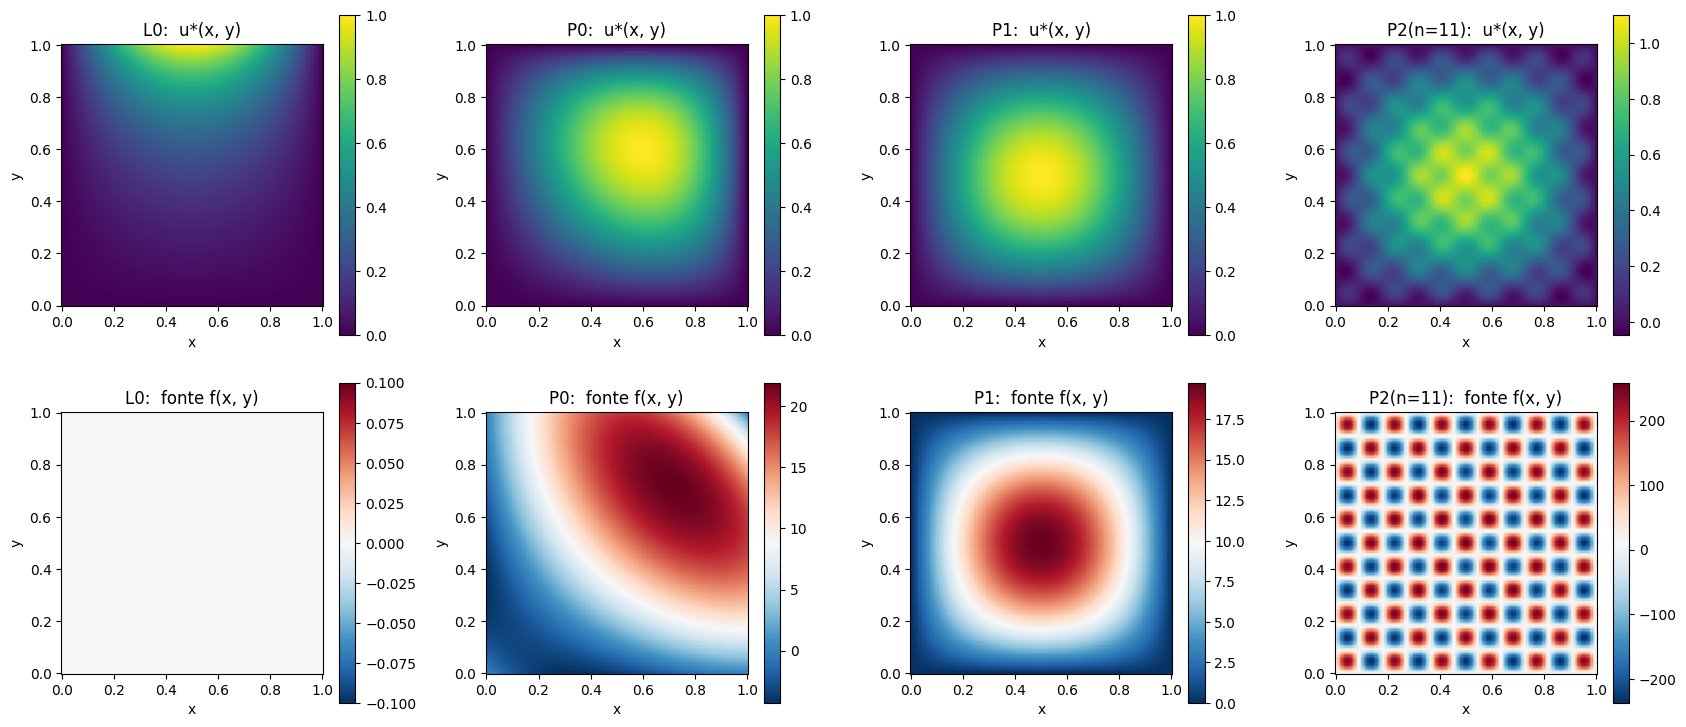

In [4]:
grade = torch.linspace(0, 1, 201, dtype=torch.float64, device="cpu")
X, Y = torch.meshgrid(grade, grade, indexing="ij")

fig, ax = plt.subplots(2, 4, figsize=(17, 7.5))
lista = [criar_problema("L0"), criar_problema("P0"), criar_problema("P1"), criar_problema("P2", n=11)]
for j, prob in enumerate(lista):
    im = ax[0, j].pcolormesh(X, Y, prob["u"](X, Y), shading="auto", cmap="viridis")
    ax[0, j].set_title(f"{prob['nome']}:  u*(x, y)")
    plt.colorbar(im, ax=ax[0, j])
    im = ax[1, j].pcolormesh(X, Y, prob["f"](X, Y), shading="auto", cmap="RdBu_r")
    ax[1, j].set_title(f"{prob['nome']}:  fonte f(x, y)")
    plt.colorbar(im, ax=ax[1, j])
for a in ax.flat:
    a.set_aspect("equal")
    a.set_xlabel("x")
    a.set_ylabel("y")
plt.tight_layout()
plt.show()

Em P2($n=11$), $u^*$ é quase igual a P1 (o modo alto tem amplitude $\varepsilon = 0{,}1$), mas a fonte é **dominada pelo modo alto** e assume valores positivos e negativos. Na leitura térmica, isso é geração **e remoção** distribuídas de calor (§3 do documento).

---
## 2. Referência por diferenças finitas (5 pontos)

É a extensão 2D da matriz `D2` do notebook do coorientador. Em uma grade interior com $N \times N$ pontos e espaçamento $h = 1/(N+1)$:

$$
-\nabla^2 u_{i,j} \approx \frac{4u_{i,j} - u_{i+1,j} - u_{i-1,j} - u_{i,j+1} - u_{i,j-1}}{h^2}
$$

- O termo central $4u_{i,j}$ e os quatro vizinhos formam o "estêncil de 5 pontos".
- A matriz 2D é montada a partir da 1D com produto de Kronecker: $A = D_1 \otimes I + I \otimes D_1$. A primeira parcela deriva em $x$ e a segunda em $y$.
- Os vizinhos que caem na borda são valores conhecidos ($g$) e vão para o lado direito.
- Com $N = 63$ há $3969$ incógnitas. Uma matriz densa seria desnecessária, então usamos `scipy.sparse`.

Papel no TCC (§9): **não é a referência de erro** (essa é a solução analítica). Ela serve para verificar, de forma independente, que o pipeline de métricas está correto: o erro do FDM tem que cair como $h^2$.

In [5]:
def resolver_fdm(prob, N=63):
    h = 1.0 / (N + 1)
    x = torch.arange(1, N + 1, dtype=torch.float64, device="cpu") * h        # pontos interiores (FDM em CPU)
    X, Y = torch.meshgrid(x, x, indexing="ij")                  # X[i, j] = x_i, Y[i, j] = y_j

    # Matriz 1D de -u'' (igual a do coorientador, sem as linhas de contorno)
    D1 = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(N, N)) / h**2
    I = sp.identity(N)
    A = (sp.kron(D1, I) + sp.kron(I, D1)).tocsr()               # -lap em 2D

    # Lado direito: fonte + vizinhos de borda (valores de g conhecidos)
    b = prob["f"](X, Y).clone()
    zero = torch.zeros(N, dtype=torch.float64, device="cpu")
    um = torch.ones(N, dtype=torch.float64, device="cpu")
    b[0, :]  += prob["u"](zero, x) / h**2      # borda x = 0
    b[-1, :] += prob["u"](um, x) / h**2        # borda x = 1
    b[:, 0]  += prob["u"](x, zero) / h**2      # borda y = 0
    b[:, -1] += prob["u"](x, um) / h**2        # borda y = 1

    U = spla.spsolve(A, b.numpy().ravel()).reshape(N, N)
    return X.numpy(), Y.numpy(), U


print(f"{'benchmark':>10} " + " ".join(f"{'N=' + str(N):>11}" for N in [15, 31, 63, 127]) + "   razao (deve ser ~4)")
for prob in [criar_problema("L0"), criar_problema("P0"), criar_problema("P1"), criar_problema("P2", n=5)]:
    erros = []
    for N in [15, 31, 63, 127]:
        X_np, Y_np, U = resolver_fdm(prob, N)
        U_ex = prob["u"](torch.from_numpy(X_np), torch.from_numpy(Y_np)).numpy()
        erros.append(np.linalg.norm(U - U_ex) / np.linalg.norm(U_ex))
    razoes = [erros[k] / erros[k + 1] for k in range(3)]
    print(f"{prob['nome']:>10} " + " ".join(f"{e:11.2e}" for e in erros) + "   " + " ".join(f"{r:.2f}" for r in razoes))

 benchmark        N=15        N=31        N=63       N=127   razao (deve ser ~4)
        L0    2.14e-03    5.10e-04    1.24e-04    3.07e-05   4.21 4.10 4.05


        P0    5.46e-16    3.41e-15    6.28e-15    1.03e-14   0.16 0.54 0.61
        P1    3.22e-03    8.04e-04    2.01e-04    5.02e-05   4.01 4.00 4.00


   P2(n=5)    8.98e-03    2.17e-03    5.39e-04    1.35e-04   4.13 4.03 4.01


**Como ler:** a razão entre erros consecutivos fica em torno de 4. Dobrar a resolução ($h \to h/2$) divide o erro por 4, que é a ordem $h^2$ esperada para o estêncil de 5 pontos.

P0 é um caso especial: com $u^*$ polinomial de grau 3 em cada variável, as derivadas de 4ª ordem que formam o erro de truncamento são zero e o FDM acerta no nível do arredondamento. Isso confirma que P0 testa o pipeline sem depender da família trigonométrica.

---
## 3. Métricas

### 3.1 Métricas globais (TCC §3.5.1)

Avaliadas em uma grade uniforme interior com $N \times N$ pontos:

$$
\mathcal{E}_{L^2} = \frac{\lVert u_\theta - u^* \rVert_{L^2}}{\lVert u^* \rVert_{L^2}}, \qquad
\mathcal{E}_{H^1} = \frac{\big(\lVert u_\theta - u^*\rVert^2_{L^2} + \lVert \nabla u_\theta - \nabla u^*\rVert^2_{L^2}\big)^{1/2}}{\big(\lVert u^*\rVert^2_{L^2} + \lVert \nabla u^*\rVert^2_{L^2}\big)^{1/2}}
$$

- $\mathcal{E}_{L^2}$: erro do valor da solução.
- $\mathcal{E}_{H^1}$: inclui o erro do **gradiente**. Um modo alto pequeno em amplitude tem gradiente grande ($\propto n$), então o $H^1$ é mais sensível a ele.
- $\mathcal{L}_{PDE}$: média de $(-\nabla^2 u_\theta - f)^2$ na grade. É diagnóstica: resíduo baixo não garante erro baixo.

Os gradientes exatos $\nabla u^*$ vêm do autograd aplicado à própria função `torch` do benchmark.

### 3.2 Métricas espectrais (§8, para P2)

Em uma grade interior uniforme $x_j = j/(N+1)$, a **transformada de senos DST-I** recupera exatamente os coeficientes de uma soma de $\varphi_{mn}$ com $m, n \le N$:

$$
u = \sum_{m,n} a_{mn}\,\varphi_{mn} \quad\Rightarrow\quad a_{mn} = \frac{\mathrm{DST\text{-}I}(U)_{mn}}{(N+1)^2}
$$

(Com a FFT haveria vazamento espectral, porque $u$ não é periódica no quadrado.) Para P2 o esperado é $a_{11} = 1$, $a_{nn} = \varepsilon$ e zero no resto:

$$
E_n = \frac{|a_{nn} - \varepsilon|}{\varepsilon}, \qquad
E_1 = |a_{11} - 1|, \qquad
E_{\text{esp}} = \Big(\sum_{(m,k)\notin\{(1,1),(n,n)\}} a_{mk}^2\Big)^{1/2}
$$

In [6]:
def grade_interior(N=63):
    x = torch.arange(1, N + 1, dtype=torch.float32) / (N + 1)
    X, Y = torch.meshgrid(x, x, indexing="ij")
    xy = torch.stack([X.ravel(), Y.ravel()], dim=1)
    return xy, X, Y


def coeficientes_seno(U):
    # U: matriz N x N na grade interior (indexacao ij). Devolve a[m-1, n-1].
    N = U.shape[0]
    return dstn(U, type=1) / (N + 1) ** 2


def metricas_espectrais(a, n, eps):
    E_n = abs(a[n - 1, n - 1] - eps) / eps
    E_1 = abs(a[0, 0] - 1.0)
    resto = a.copy()
    resto[0, 0] = 0.0
    resto[n - 1, n - 1] = 0.0
    E_esp = np.sqrt(np.sum(resto ** 2))
    return E_n, E_1, E_esp


# Conferencia do instrumento na propria solucao exata de P2(n=11)
_, Xg, Yg = grade_interior(63)
a_ex = coeficientes_seno(criar_problema("P2", n=11)["u"](Xg.double(), Yg.double()).cpu().numpy())
print("a_11 =", round(a_ex[0, 0], 12), "| a_(11,11) =", round(a_ex[10, 10], 12))
print("E_n, E_1, E_esp na solucao exata:", metricas_espectrais(a_ex, 11, 0.1))

a_11 = 1.0 | a_(11,11) = 0.1
E_n, E_1, E_esp na solucao exata: (np.float64(1.3877787807814457e-16), np.float64(0.0), np.float64(4.60899917572116e-16))


In [7]:
def avaliar(u_func, prob, N=63):
    # u_func: funcao (N,2) -> (N,1). Pode ser a rede ou qualquer aproximacao.
    xy, X, Y = grade_interior(N)
    xy = xy.clone().requires_grad_(True)
    x, y = xy[:, 0:1], xy[:, 1:2]

    u_ap = u_func(xy)
    u_ex = prob["u"](x, y)

    grad_ap = torch.autograd.grad(u_ap, xy, torch.ones_like(u_ap), create_graph=True)[0]
    grad_ex = torch.autograd.grad(u_ex, xy, torch.ones_like(u_ex), create_graph=True)[0]
    residuo = -laplaciano(u_ap, xy) - prob["f"](x, y)

    e, ge = (u_ap - u_ex).detach(), (grad_ap - grad_ex).detach()
    ue, gue = u_ex.detach(), grad_ex.detach()

    m = {
        "L2": (torch.sqrt((e**2).sum()) / torch.sqrt((ue**2).sum())).item(),
        "H1": (torch.sqrt((e**2).sum() + (ge**2).sum()) / torch.sqrt((ue**2).sum() + (gue**2).sum())).item(),
        "PDE": (residuo.detach()**2).mean().item(),
        "U": u_ap.detach().reshape(N, N).cpu().numpy().astype(np.float64),
    }
    if "n" in prob:
        a = coeficientes_seno(m["U"])
        m["E_n"], m["E_1"], m["E_esp"] = metricas_espectrais(a, prob["n"], prob["eps"])
        m["coef"] = a
    return m

### 3.3 Métrica física (RQ2): balanço global

Integrando $-\nabla^2 u = f$ no quadrado e usando o teorema da divergência:

$$
\int_\Omega f \, dA = -\oint_{\partial\Omega} \frac{\partial u}{\partial n}\, ds
$$

A solução exata satisfaz isso exatamente. Para a PINN, medimos o desequilíbrio relativo

$$
\mathcal{E}_{\text{bal}} = \frac{\big|\int_\Omega f\,dA + \oint_{\partial\Omega} \partial_n u_\theta\, ds\big|}{\oint_{\partial\Omega} |\partial_n u^*|\, ds}
$$

com quadratura de Gauss-Legendre (64 pontos por direção). Ela verifica a "conservação" que a RQ2 menciona: a fonte total tem que sair pela borda. É sensível ao **gradiente na borda**, que nenhuma das métricas anteriores olha diretamente. (Os saltos de $u$ e de $\partial_n u$ nas interfaces do XPINN, a outra métrica da RQ2, estão na seção 11.)

In [8]:
def balanco_global(modelo, prob, Nq=64):
    # Teorema da divergencia: -lap u = f  =>  integral de f em Omega = - integral de du/dn na borda.
    # Devolve |int f + int du_theta/dn| / int |du*/dn|  (0 para a solucao exata).
    t, w = np.polynomial.legendre.leggauss(Nq)
    t = torch.tensor((t + 1) / 2, dtype=torch.float32).unsqueeze(1)
    w = torch.tensor(w / 2, dtype=torch.float32).unsqueeze(1)
    X, Y = torch.meshgrid(t.ravel(), t.ravel(), indexing="ij")
    integral_f = (prob["f"](X, Y) * (w @ w.T)).sum()

    z, o = torch.zeros_like(t), torch.ones_like(t)
    lados = [(torch.cat([z, t], 1), 0, -1.0), (torch.cat([o, t], 1), 0, 1.0),     # x = 0 e x = 1
             (torch.cat([t, z], 1), 1, -1.0), (torch.cat([t, o], 1), 1, 1.0)]     # y = 0 e y = 1
    fluxo_rede, fluxo_exato_abs = 0.0, 0.0
    for pts, comp, sinal in lados:
        pts = pts.clone().requires_grad_(True)
        for func, alvo in [(modelo, "rede"), (lambda p: prob["u"](p[:, 0:1], p[:, 1:2]), "exato")]:
            u = func(pts)
            dn = sinal * torch.autograd.grad(u, pts, torch.ones_like(u))[0][:, comp:comp + 1]
            if alvo == "rede":
                fluxo_rede += (dn * w).sum().item()
            else:
                fluxo_exato_abs += (dn.abs() * w).sum().item()
    return abs(integral_f.item() + fluxo_rede) / fluxo_exato_abs


for prob in [criar_problema("L0"), criar_problema("P0"), criar_problema("P1"), criar_problema("P2", n=11)]:
    exata = lambda p, prob=prob: prob["u"](p[:, 0:1], p[:, 1:2])
    print(f"{prob['nome']:>9}: E_bal da solução exata = {balanco_global(exata, prob):.1e}")

       L0: E_bal da solução exata = 1.9e-08
       P0: E_bal da solução exata = 0.0e+00
       P1: E_bal da solução exata = 6.0e-08


 P2(n=11): E_bal da solução exata = 8.9e-08


---
## 4. A PINN

É a mesma receita do notebook 1D, agora com entrada $(x, y)$:

1. **Rede:** MLP com entrada 2, 4 camadas ocultas de largura 64 com `Tanh`, saída 1. Pesos inicializados com Glorot/Xavier (TCC §3.4).
2. **Pontos de colocação:** $N_f = 2000$ pontos no interior, por **Latin Hypercube Sampling** (TCC §2.2.6). Ficam **fixos** durante o treino: sem reamostragem adaptativa no núcleo (§12.4 do documento).
3. **Contorno fraco (padrão deste notebook, eq. 10 do TCC):**

$$
\mathcal{L} = \lambda_{PDE}\,\mathcal{L}_{PDE} + \lambda_{BC}\,\mathcal{L}_{BC}, \qquad
\mathcal{L}_{BC} = \frac{1}{N_b}\sum_{j=1}^{N_b} \big(u_\theta(\mathbf{x}_j) - g(\mathbf{x}_j)\big)^2
$$

   com $N_b = 400$ pontos equiespaçados na borda, $\lambda_{PDE} = 1/\overline{f^2}$ e $\lambda_{BC} = 1$.
   - É a **única formulação que serve para as três arquiteturas** (monolítica, DDP e XPINN). A transfinita acopla sub-redes não vizinhas no XPINN (seção 13), e o $D$ produto altera o conteúdo espectral do que a rede aprende (seção 9).
   - É a eq. 10 original do TCC: não há afastamento a justificar no texto.

   Duas formulações de **contorno exato** estão implementadas e entram **só como sensibilidade, na monolítica** (seção 9). Nelas $u_\theta = g$ na borda por construção e a perda fica só com a EDP:

   - `contorno="exato"` ($D$ produto, Lagaris et al., 1998; Sukumar e Srivastava, 2022):

$$
u_\theta(x, y) = D(x, y)\,\mathrm{NN}_\theta(x, y) + G(x, y), \qquad D(x, y) = x(1-x)\,y(1-y)
$$

     $D$ zera a rede na borda e $G$ vale $g$ ali. **Cuidado:** a rede não aprende $u^*$, aprende $(u^* - G)/D$; a seção 9 mostra o quanto isso muda o problema.
   - `contorno="transfinito"`: $u_\theta = \mathrm{NN} - T[\mathrm{NN}] + T[G]$, com $T$ a interpolação transfinita (Coons) dos valores na borda:

$$
T[F](x,y) = (1-x)F(0,y) + xF(1,y) + (1-y)F(x,0) + yF(x,1) - \big[(1-x)(1-y)F(0,0) + x(1-y)F(1,0) + (1-x)yF(0,1) + xyF(1,1)\big]
$$

   Na borda $T[F] = F$, então $u_\theta = g$ por construção. **Não há divisão:** se a rede acertar $u^*$, então $u_\theta = u^*$. O custo é avaliar a rede também nas quatro linhas da borda.
4. **Otimizador:** Adam (3000 épocas, lr $10^{-3}$) seguido de L-BFGS **até o platô**.

### Por que dois otimizadores

O Adam é robusto no começo, quando a rede está longe da solução, mas fica oscilando perto do mínimo. O L-BFGS usa uma aproximação da curvatura da perda e refina muito mais rápido quando já está perto. Adam → L-BFGS é a receita padrão em PINNs, e o TCC (§2.2.5) já cita os dois.

### Critério de parada do L-BFGS

O L-BFGS roda em passos de 20 iterações e para quando **a perda cai menos de 1% em 10 passos** (200 iterações), com teto de 100 passos (2000 iterações). Assim, cada execução termina perto do mínimo que consegue atingir, e não num ponto arbitrário. O notebook registra se a execução parou por platô ou pelo teto (coluna "platô" nas tabelas); quando para pelo teto, o resultado reflete o orçamento, não a acurácia atingível.

### O fator $\lambda_{PDE} = 1/\overline{f^2}$

Na formulação fraca, ele põe o resíduo da EDP na mesma escala do termo de borda em todos os benchmarks: todas as soluções têm amplitude ~1 (por isso o P0 foi reescalado), então $\mathcal{L}_{BC}$ já está na casa de 1, e $\mathcal{L}_{PDE}/\overline{f^2}$ também. Em L0, $f = 0$ e $\lambda_{PDE} = 1$. Com contorno exato, a perda tem um termo só e o fator não muda o mínimo. Ele é calculado sobre o conjunto **global** de pontos, o que importa no DDP.

### Preparado para o DDP

`treinar_pinn` tem um parâmetro `distribuido`. Com `False` (padrão), é o treino sequencial. Com `True`, o **mesmo código** divide os pontos entre os processos e envolve a rede em `DistributedDataParallel` (seção 10). A perda é calculada com **uma única passagem** pela rede: o DDP exige um forward por backward.

### Registro do treino

Guardamos o $\mathcal{E}_{L^2}$ (e $E_n$ em P2) **junto com o tempo de relógio** a cada 100 iterações. Isso permite medir *time-to-solution*, o tempo até atingir um limiar de erro (TCC §3.7), em vez de tempo por época.

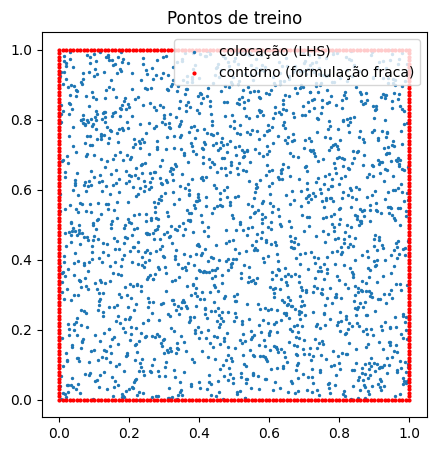

In [9]:
def criar_rede(largura=64, camadas_ocultas=4):
    camadas = [torch.nn.Linear(2, largura), torch.nn.Tanh()]
    for _ in range(camadas_ocultas - 1):
        camadas += [torch.nn.Linear(largura, largura), torch.nn.Tanh()]
    camadas += [torch.nn.Linear(largura, 1)]
    rede = torch.nn.Sequential(*camadas)
    for c in rede:
        if isinstance(c, torch.nn.Linear):
            torch.nn.init.xavier_normal_(c.weight)
            torch.nn.init.zeros_(c.bias)
    return rede


def pontos_colocacao(N_f, semente):
    lhs = qmc.LatinHypercube(d=2, seed=semente)
    return torch.tensor(lhs.random(N_f), dtype=torch.float32)


def pontos_contorno(N_b):
    # N_b/4 pontos por lado, sem repetir os cantos
    s = torch.linspace(0, 1, N_b // 4 + 1)[:-1]
    zero, um = torch.zeros_like(s), torch.ones_like(s)
    lados = [torch.stack([s, zero], 1),        # y = 0
             torch.stack([um, s], 1),          # x = 1
             torch.stack([1 - s, um], 1),      # y = 1
             torch.stack([zero, 1 - s], 1)]    # x = 0
    return torch.cat(lados, 0)


xy_b = pontos_contorno(400).cpu()
xy_f = pontos_colocacao(2000, SEMENTE).cpu()
plt.figure(figsize=(5, 5))
plt.scatter(xy_f[:, 0], xy_f[:, 1], s=2, label="colocação (LHS)")
plt.scatter(xy_b[:, 0], xy_b[:, 1], s=4, c="r", label="contorno (formulação fraca)")
plt.gca().set_aspect("equal")
plt.legend(loc="upper right")
plt.title("Pontos de treino")
plt.show()

As classes do contorno exato (usadas na seção 9) ficam numa célula só com definições: o script do DDP (seção 10) copia esta célula inteira.

In [10]:
def distancia_contorno(x, y):
    # D(x, y) = x(1-x)y(1-y): zero nos quatro lados, positiva no interior
    return x * (1 - x) * y * (1 - y)


class ContornoExato(torch.nn.Module):
    # u(x, y) = D(x, y) * NN(x, y) + G(x, y)
    # D zera a rede na borda e G carrega o valor de Dirichlet: u = g na borda por construcao
    def __init__(self, rede, G):
        super().__init__()
        self.rede = rede
        self.G = G

    def forward(self, xy):
        x, y = xy[:, 0:1], xy[:, 1:2]
        return distancia_contorno(x, y) * self.rede(xy) + self.G(x, y)


class ContornoTransfinito(torch.nn.Module):
    # u = NN - T[NN] + T[G], com T a interpolacao transfinita (Coons) dos valores na borda.
    # Na borda, T[F] = F, entao u = G = g por construcao. Nao ha divisao por D:
    # se NN = u*, entao u = u*, e a rede pode representar a propria solucao.
    def __init__(self, rede, G):
        super().__init__()
        self.rede = rede
        self.G = G

    @staticmethod
    def T(F, x, y):
        z, o = torch.zeros_like(x), torch.ones_like(x)
        cantos = F(torch.tensor([[0.0], [1.0], [0.0], [1.0]], device=x.device), torch.tensor([[0.0], [0.0], [1.0], [1.0]], device=x.device))
        c00, c10, c01, c11 = cantos[0], cantos[1], cantos[2], cantos[3]
        return ((1 - x) * F(z, y) + x * F(o, y) + (1 - y) * F(x, z) + y * F(x, o)
                - ((1 - x) * (1 - y) * c00 + x * (1 - y) * c10 + (1 - x) * y * c01 + x * y * c11))

    def forward(self, xy):
        x, y = xy[:, 0:1], xy[:, 1:2]
        NN = lambda a, b: self.rede(torch.cat([a, b], 1))
        return NN(x, y) - self.T(NN, x, y) + self.T(self.G, x, y)

In [11]:
def otimizar(parametros, perdas, registrar, mostrar, relogio, media_global, epocas_adam, passos_lbfgs_max,
             iter_por_passo, lr, tolerancia_plato, janela_plato, avaliar_a_cada, somar_gradientes=lambda: None):
    # Adam com numero fixo de epocas, depois L-BFGS ate o plato (ou ate passos_lbfgs_max).
    # Plato: a perda caiu menos que tolerancia_plato (relativo) nos ultimos janela_plato passos.
    # somar_gradientes: chamado depois de cada backward (XPINN distribuido: all-reduce dos gradientes).
    # Na GPU as operacoes sao assincronas: sincroniza antes de ler o relogio
    sincronizar = torch.cuda.synchronize if parametros[0].is_cuda else (lambda: None)
    adam = torch.optim.Adam(parametros, lr=lr)
    for epoca in range(epocas_adam):
        t0 = time.perf_counter()
        adam.zero_grad()
        termos = perdas()
        termos[0].backward()                              # no DDP, aqui acontece o all-reduce
        somar_gradientes()
        adam.step()
        sincronizar()
        relogio[0] += time.perf_counter() - t0            # so o treino entra no relogio
        valores = [media_global(v).item() for v in termos]
        m = registrar(epoca, valores, forcar=(epoca % avaliar_a_cada == 0))
        if epoca % 1000 == 0:
            mostrar("Adam ", epoca, valores, m)

    lbfgs = torch.optim.LBFGS(parametros, lr=1.0, max_iter=iter_por_passo, history_size=50,
                              line_search_fn="strong_wolfe", tolerance_grad=0, tolerance_change=0)
    def closure():
        lbfgs.zero_grad()
        loss = perdas()[0]
        loss.backward()
        somar_gradientes()
        # A busca de linha compara valores da perda: todos os processos precisam ver o MESMO valor
        return media_global(loss)

    it, perda_passos, passos = epocas_adam, [], 0
    for passo in range(passos_lbfgs_max):
        t0 = time.perf_counter()
        perda_passo = float(lbfgs.step(closure).detach())
        sincronizar()
        relogio[0] += time.perf_counter() - t0
        it += iter_por_passo
        passos += 1
        perda_passos.append(perda_passo)
        avaliar_agora = (passo + 1) % (avaliar_a_cada // iter_por_passo) == 0
        valores = [media_global(v).item() for v in perdas(registro=True)]
        m = registrar(it, valores, forcar=avaliar_agora)
        if (passo + 1) % 25 == 0:
            mostrar("LBFGS", it, valores, m)
        if not math.isfinite(perda_passo):
            break
        if len(perda_passos) > janela_plato:
            antes = perda_passos[-janela_plato - 1]
            if (antes - perda_passo) / abs(antes) < tolerancia_plato:
                break
    registrar(it, valores, forcar=True)                   # avaliacao final sempre registrada
    return it, passos


def treinar_pinn(prob, contorno="fraco", epocas_adam=3000, passos_lbfgs_max=100, iter_por_passo=20,
                 tolerancia_plato=0.01, janela_plato=10, N_f=2000, N_b=400, lr=1e-3, largura=64, camadas_ocultas=4,
                 semente=SEMENTE, lam_pde="auto", lam_bc=1.0, avaliar_a_cada=100, imprimir=True, distribuido=False,
                 N_aval=63):
    # contorno: "fraco" (nucleo, eq. 10 do TCC), "exato" (D produto) ou "transfinito" (sensibilidade, secao 9).
    # tolerancia_plato = -inf: orcamento fixo, roda todos os passos do L-BFGS. N_aval: grade de avaliacao N x N.
    torch.manual_seed(semente)
    rede = criar_rede(largura, camadas_ocultas)
    if contorno == "exato":
        rede_final = ContornoExato(rede, prob["G"])                 # u = D * NN + G
    elif contorno == "transfinito":
        rede_final = ContornoTransfinito(rede, prob["G"])           # u = NN - T[NN] + T[G]
    else:
        rede_final = rede                                           # contorno por penalidade

    # Pontos GLOBAIS, fixos durante o treino (iguais em todos os processos)
    xy_f = pontos_colocacao(N_f, semente)
    f_f = prob["f"](xy_f[:, 0:1], xy_f[:, 1:2]).detach()
    xy_b = pontos_contorno(N_b) if contorno == "fraco" else torch.zeros(0, 2)

    # Peso da EDP: "auto" = 1/media(f^2) sobre o conjunto GLOBAL (no DDP nao pode ser por rank).
    # Contorno fraco: poe o residuo na escala do termo de borda (solucoes com amplitude ~1).
    # Contorno exato: a perda tem um termo so, e esse fator apenas deixa os numeros na casa de 1.
    if lam_pde == "auto":
        escala = torch.mean(f_f**2).item()
        lam_pde = 1.0 / escala if escala > 0 else 1.0

    # DDP: cada processo fica com uma fatia de tamanho IGUAL dos pontos (secao 10 do documento)
    modelo, p = rede_final, 1
    if distribuido:
        rank, p = dist.get_rank(), dist.get_world_size()
        assert N_f % p == 0 and len(xy_b) % p == 0, "N_f e N_b precisam ser divisiveis pelo numero de processos"
        xy_f = torch.chunk(xy_f, p)[rank]
        xy_b = torch.chunk(xy_b, p)[rank] if len(xy_b) else xy_b
        modelo = DDP(rede_final)

    xy_f = xy_f.clone().requires_grad_(True)
    f_f = prob["f"](xy_f[:, 0:1], xy_f[:, 1:2]).detach()
    g_b = prob["u"](xy_b[:, 0:1], xy_b[:, 1:2]).detach() if len(xy_b) else None
    n_f = xy_f.shape[0]

    def perdas(registro=False):
        # Uma unica passagem pela rede com interior + contorno (o DDP exige 1 forward por backward).
        # registro=True: so para registrar, sem passar pelo DDP.
        mod = rede_final if registro else modelo
        u = mod(torch.cat([xy_f, xy_b]))
        residuo = -laplaciano(u[:n_f], xy_f) - f_f          # -lap(u) - f deve ser 0
        loss_pde = torch.mean(residuo**2)
        if contorno == "fraco":
            loss_bc = torch.mean((u[n_f:] - g_b)**2)        # u = g na borda (penalidade)
        else:
            loss_bc = torch.zeros(())                        # u = g na borda por construcao
        return lam_pde * loss_pde + lam_bc * loss_bc, loss_pde, loss_bc

    def media_global(valor):
        # Valor medio entre processos (para registrar e para a busca de linha do L-BFGS)
        if not distribuido:
            return valor
        v = valor.detach().clone()
        dist.all_reduce(v)
        return v / p

    hist = {"it": [], "loss": [], "pde": [], "bc": [], "aval_it": [], "aval_tempo": [], "L2": [], "E_n": [], "E_1": [],
            "fim_adam": epocas_adam, "lam_pde": lam_pde, "lam_bc": lam_bc, "contorno": contorno}
    relogio = [0.0]

    def registrar(it, valores, forcar=False):
        hist["it"].append(it)
        hist["loss"].append(valores[0])
        hist["pde"].append(valores[1])
        hist["bc"].append(valores[2])
        if forcar:
            m = avaliar(rede_final, prob, N_aval)
            hist["aval_it"].append(it)
            hist["aval_tempo"].append(relogio[0])
            hist["L2"].append(m["L2"])
            if "n" in prob:
                hist["E_n"].append(m["E_n"])
                hist["E_1"].append(m["E_1"])
            return m

    def mostrar(fase, it, valores, m):
        if imprimir and m is not None:
            extra = f" | E_n {m['E_n']:.3f}" if "n" in prob else ""
            print(f"[{prob['nome']}] {fase} it {it:5d} | loss {valores[0]:.2e} | PDE {valores[1]:.2e} | BC {valores[2]:.2e} | L2 {m['L2']:.2e}{extra}")

    it_final, passos = otimizar(list(rede_final.parameters()), perdas, registrar, mostrar, relogio, media_global,
                                epocas_adam, passos_lbfgs_max, iter_por_passo, lr, tolerancia_plato, janela_plato,
                                avaliar_a_cada)
    hist["it_final"], hist["passos_lbfgs"] = it_final, passos
    hist["platô"] = passos < passos_lbfgs_max
    return rede_final, hist, relogio[0]


def time_to_solution(hist, chave, limiar):
    # Tempo de relogio a partir do qual hist[chave] fica abaixo do limiar ATE O FIM do treino.
    # (So "a primeira vez abaixo" nao serve: E_n pode cruzar o limiar de passagem
    #  enquanto o coeficiente a_nn ainda esta oscilando.)
    valores = hist[chave]
    for k in range(len(valores)):
        if all(v < limiar for v in valores[k:]):
            return hist["aval_tempo"][k]
    return None

In [12]:
def mostrar_resultado(rede, prob, hist, N=63):
    m = avaliar(rede, prob, N)
    _, X, Y = grade_interior(N)
    U_ex = prob["u"](X, Y).cpu().numpy()
    X, Y = X.cpu(), Y.cpu()

    fig, ax = plt.subplots(1, 4, figsize=(19, 4))
    for a, Z, titulo, cmap in [(ax[0], U_ex, "u* exata", "viridis"),
                                (ax[1], m["U"], "u PINN", "viridis"),
                                (ax[2], np.abs(m["U"] - U_ex), "|erro|", "magma")]:
        im = a.pcolormesh(X, Y, Z, shading="auto", cmap=cmap)
        a.set_title(f"{prob['nome']}: {titulo}")
        a.set_aspect("equal")
        plt.colorbar(im, ax=a)

    ax[3].semilogy(hist["it"], hist["pde"], label="L_PDE (sem peso)", lw=1)
    if hist["contorno"] == "fraco":
        ax[3].semilogy(hist["it"], hist["bc"], label="L_BC", lw=1)
    ax[3].semilogy(hist["aval_it"], hist["L2"], "k-", label="E_L2 (teste)", lw=2)
    ax[3].axvline(hist["fim_adam"], color="gray", ls=":", label="Adam → L-BFGS")
    ax[3].set_xlabel("iteração")
    ax[3].legend()
    ax[3].grid(True, which="both", alpha=.3)
    ax[3].set_title(f"Treino ({'parou no platô' if hist['platô'] else 'parou no teto de iterações'})")
    plt.tight_layout()
    plt.show()
    return m

---
## 5. Núcleo: L0, P0 e P1

Mesma rede, mesmos pontos, mesmo otimizador, mesma formulação (contorno fraco) e mesma semente para os três. Só muda o problema.

### L0: Laplace

$$-\nabla^2 u = 0, \qquad u(x, 1) = \sin(\pi x), \quad u = 0 \text{ nos outros três lados}$$

É o análogo 2D do Laplace 1D: sem fonte, toda a informação vem do contorno. A solução $\sin(\pi x)\sinh(\pi y)/\sinh\pi$ cresce da borda de baixo (zero) até a de cima (o seno). Com contorno fraco, essa informação entra **só** pelo termo de borda $\mathcal{L}_{BC}$.

[L0] Adam  it     0 | loss 7.84e-02 | PDE 8.88e-03 | BC 6.95e-02 | L2 7.09e-01


[L0] Adam  it  1000 | loss 1.94e-02 | PDE 1.42e-03 | BC 1.80e-02 | L2 2.53e-01


[L0] Adam  it  2000 | loss 5.20e-03 | PDE 1.08e-03 | BC 4.12e-03 | L2 1.50e-01


[L0] LBFGS it  3500 | loss 4.47e-05 | PDE 3.21e-05 | BC 1.26e-05 | L2 5.56e-03


[L0] LBFGS it  4000 | loss 1.29e-05 | PDE 5.65e-06 | BC 7.22e-06 | L2 4.02e-03


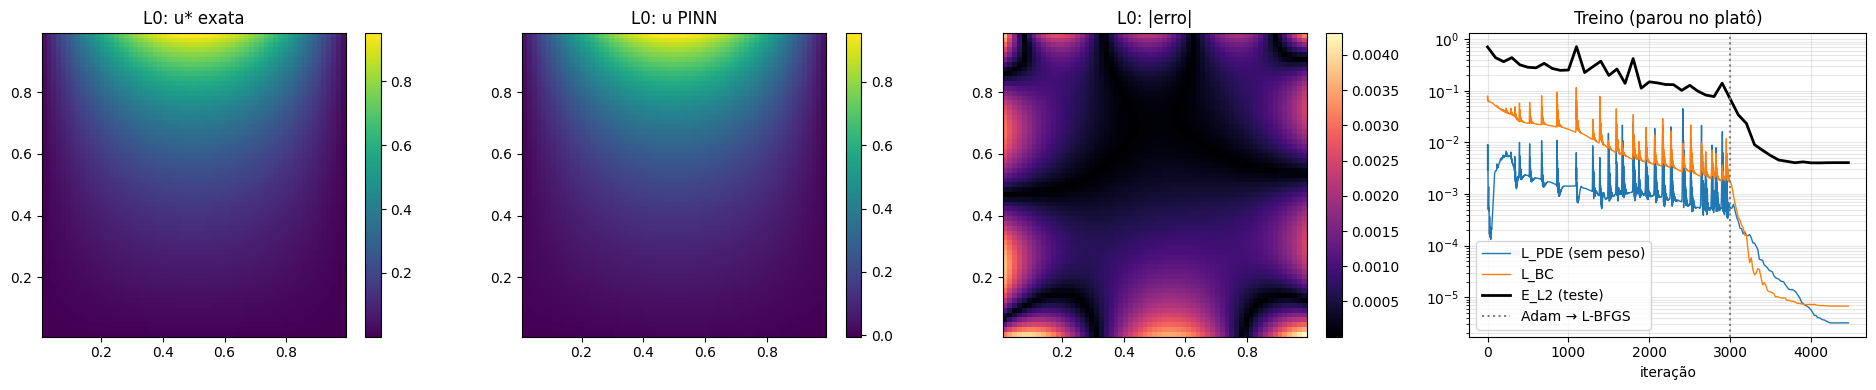

In [13]:
resultados = {}

prob = criar_problema("L0")
rede, hist, tempo = treinar_pinn(prob)
resultados["L0"] = (prob, rede, hist, tempo, mostrar_resultado(rede, prob, hist))

### P0: Poisson polinomial

$$-\nabla^2 u = A\,[2y(1-y)(3x+y-1) + 2x(1-x)(x+3y-1)], \qquad u = 0 \text{ na borda}$$

com solução $u^* = A\,x(1-x)\,y(1-y)\,(x+y)$ e $A = 1/0{,}06912$ (máximo 1, seção 1).

Controle de sanidade fora da família de senos: se o pipeline tiver algum viés escondido para funções trigonométricas, ele aparece aqui.

[P0] Adam  it     0 | loss 1.02e+00 | PDE 1.57e+02 | BC 3.66e-02 | L2 1.03e+00


[P0] Adam  it  1000 | loss 1.07e-03 | PDE 1.37e-01 | BC 2.16e-04 | L2 1.25e-02


[P0] Adam  it  2000 | loss 3.42e-04 | PDE 4.14e-02 | BC 8.29e-05 | L2 7.61e-03


[P0] LBFGS it  3500 | loss 2.70e-05 | PDE 3.42e-03 | BC 5.52e-06 | L2 1.85e-03


[P0] LBFGS it  4000 | loss 5.32e-06 | PDE 7.04e-04 | BC 9.11e-07 | L2 6.17e-04


[P0] LBFGS it  4500 | loss 1.99e-06 | PDE 2.01e-04 | BC 7.32e-07 | L2 5.35e-04


[P0] LBFGS it  5000 | loss 9.95e-07 | PDE 1.01e-04 | BC 3.61e-07 | L2 3.93e-04


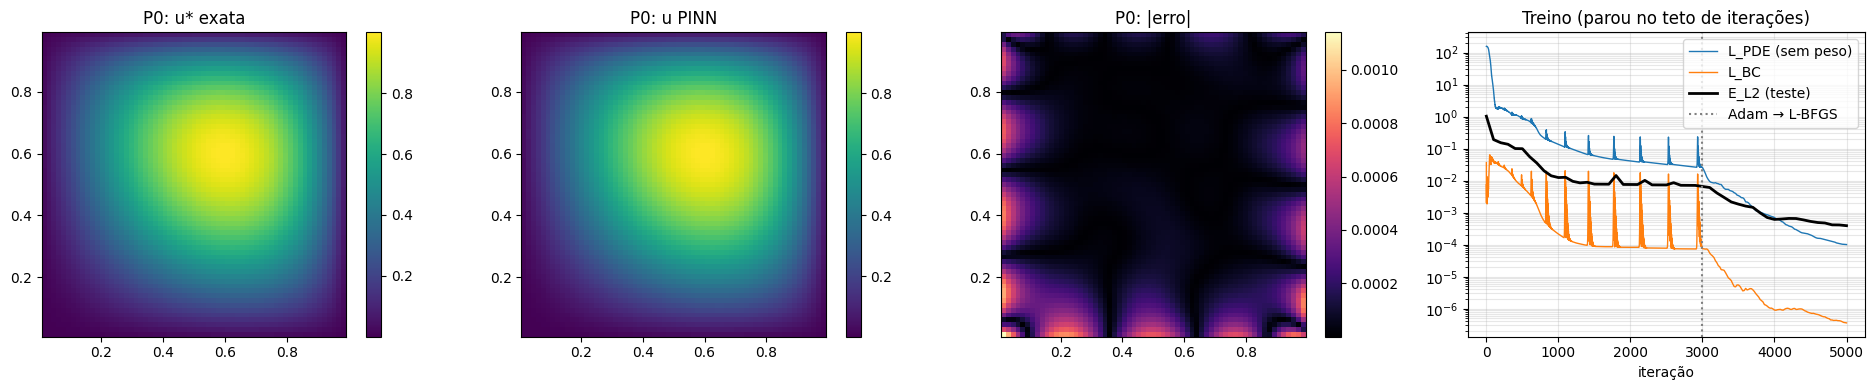

In [14]:
prob = criar_problema("P0")
rede, hist, tempo = treinar_pinn(prob)
resultados["P0"] = (prob, rede, hist, tempo, mostrar_resultado(rede, prob, hist))

### P1: Poisson com um modo

$$-\nabla^2 u = 2\pi^2 \sin(\pi x)\sin(\pi y), \qquad u = 0 \text{ na borda}$$

A versão 2D direta do Poisson 1D ($-u'' = \pi^2\sin\pi x$). O fator passa de $\pi^2$ para $2\pi^2$ porque agora há curvatura nas duas direções.

[P1] Adam  it     0 | loss 1.02e+00 | PDE 9.59e+01 | BC 3.66e-02 | L2 1.03e+00


[P1] Adam  it  1000 | loss 1.12e-04 | PDE 9.50e-03 | BC 1.45e-05 | L2 4.04e-03


[P1] Adam  it  2000 | loss 2.64e-05 | PDE 2.33e-03 | BC 2.38e-06 | L2 1.07e-03


[P1] LBFGS it  3500 | loss 5.59e-07 | PDE 4.48e-05 | BC 9.89e-08 | L2 2.33e-04


[P1] LBFGS it  4000 | loss 2.08e-07 | PDE 1.93e-05 | BC 9.85e-09 | L2 7.09e-05


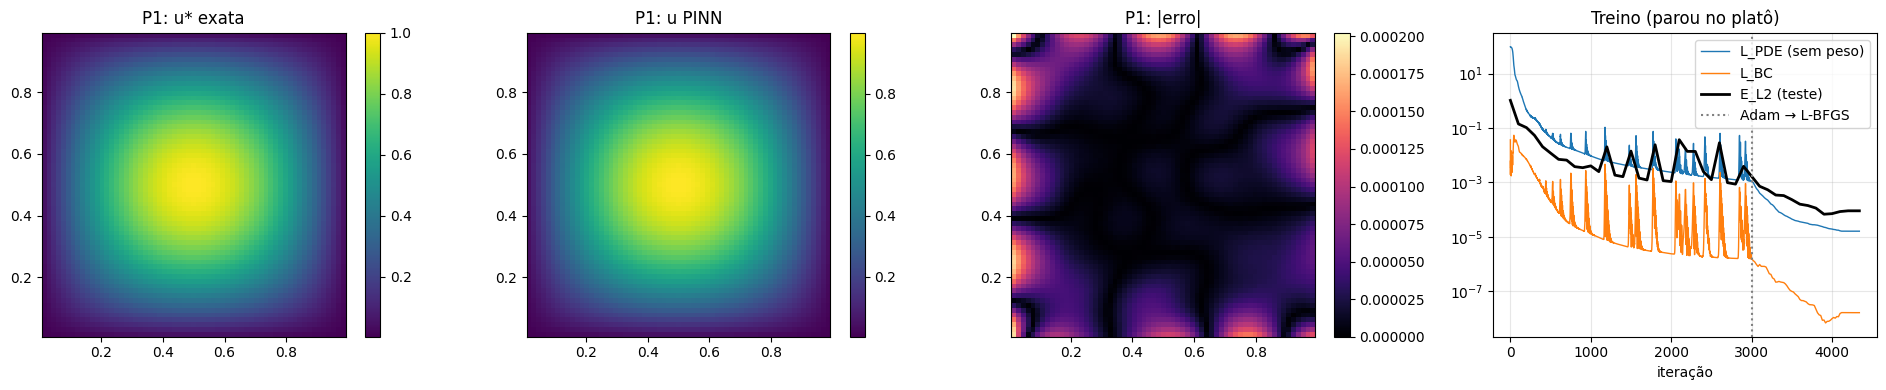

In [15]:
prob = criar_problema("P1")
rede, hist, tempo = treinar_pinn(prob)
resultados["P1"] = (prob, rede, hist, tempo, mostrar_resultado(rede, prob, hist))

---
## 6. P2($n$): dois modos de frequências diferentes

$$
u^* = \varphi_{11} + \varepsilon\,\varphi_{nn}, \qquad \varepsilon = 0{,}1
$$

O *spectral bias* é a tendência das redes neurais de aprenderem primeiro (e melhor) as componentes de **baixa frequência**. Em P2, o modo $\varphi_{11}$ é fácil e o modo $\varphi_{nn}$ é o difícil.

**O que conta como *spectral bias* aqui:** $E_1$ pequeno **e** $E_n$ grande (a rede aprende o modo baixo e erra o alto). Se os dois modos se perdem juntos, o problema é outro; a seção 13 mostra que é isso o que acontece acima de $n \approx 13$.

### Por que o $\mathcal{E}_{L^2}$ sozinho não basta (§7)

Se a rede acerta $\varphi_{11}$ e **ignora completamente** $\varphi_{nn}$, o erro é $\varepsilon\varphi_{nn}$ e

$$
\mathcal{E}_{L^2} = \frac{\varepsilon}{\sqrt{1 + \varepsilon^2}} \approx 0{,}0995,
$$

independente de $n$. Um $\mathcal{E}_{L^2}$ de 9% pode significar "errou tudo um pouco" ou "acertou o modo baixo e não aprendeu o alto". Só $E_n$ separa os dois casos.

Rodamos $n = 5$ e $n = 11$ com a mesma configuração.

Teto do E_L2 para quem ignora o modo alto: 0.0995
[P2(n=5)] Adam  it     0 | loss 1.03e+00 | PDE 7.04e+02 | BC 3.66e-02 | L2 1.05e+00 | E_n 1.017


[P2(n=5)] Adam  it  1000 | loss 3.28e-03 | PDE 1.66e+00 | BC 9.24e-04 | L2 2.00e-02 | E_n 0.011


[P2(n=5)] Adam  it  2000 | loss 2.68e-03 | PDE 1.01e+00 | BC 1.25e-03 | L2 5.17e-02 | E_n 0.031


[P2(n=5)] LBFGS it  3500 | loss 2.58e-05 | PDE 1.50e-02 | BC 4.51e-06 | L2 1.23e-03 | E_n 0.005


[P2(n=5)] LBFGS it  4000 | loss 8.71e-06 | PDE 5.74e-03 | BC 5.86e-07 | L2 4.47e-04 | E_n 0.001


[P2(n=5)] LBFGS it  4500 | loss 4.21e-06 | PDE 2.75e-03 | BC 3.17e-07 | L2 3.26e-04 | E_n 0.001


[P2(n=5)] LBFGS it  5000 | loss 2.48e-06 | PDE 1.63e-03 | BC 1.62e-07 | L2 2.21e-04 | E_n 0.000


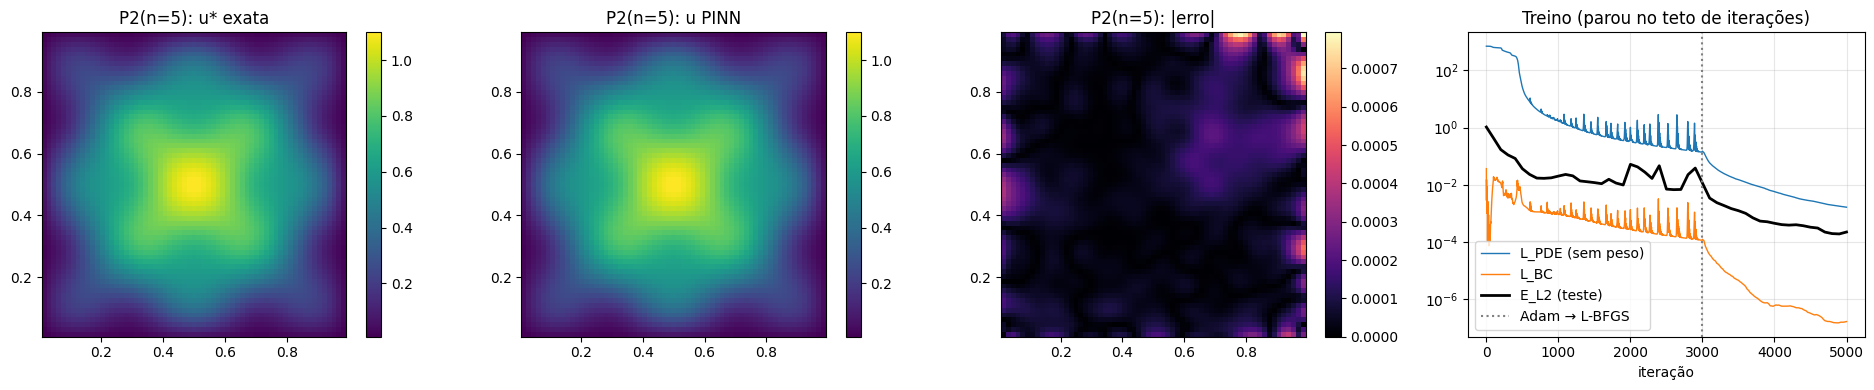

[P2(n=11)] Adam  it     0 | loss 1.04e+00 | PDE 1.45e+04 | BC 3.66e-02 | L2 1.05e+00 | E_n 1.003


[P2(n=11)] Adam  it  1000 | loss 9.92e-01 | PDE 1.43e+04 | BC 4.93e-04 | L2 3.25e-01 | E_n 1.003


[P2(n=11)] Adam  it  2000 | loss 5.12e-01 | PDE 7.38e+03 | BC 2.12e-03 | L2 2.83e-01 | E_n 0.530


[P2(n=11)] LBFGS it  3500 | loss 1.07e-01 | PDE 1.51e+03 | BC 3.08e-03 | L2 1.90e-01 | E_n 0.131


[P2(n=11)] LBFGS it  4000 | loss 2.91e-02 | PDE 3.91e+02 | BC 2.07e-03 | L2 1.30e-01 | E_n 0.032


[P2(n=11)] LBFGS it  4500 | loss 5.95e-03 | PDE 7.83e+01 | BC 5.37e-04 | L2 7.54e-02 | E_n 0.006


[P2(n=11)] LBFGS it  5000 | loss 2.14e-03 | PDE 2.85e+01 | BC 1.74e-04 | L2 4.60e-02 | E_n 0.001


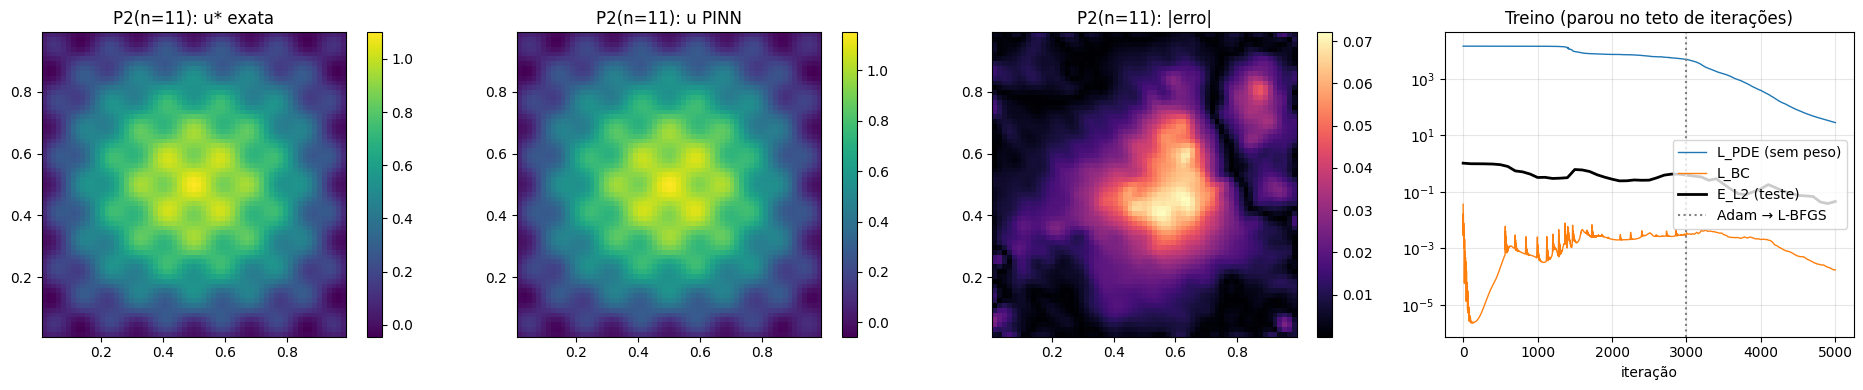

In [16]:
TETO_L2 = 0.1 / math.sqrt(1 + 0.1**2)
print(f"Teto do E_L2 para quem ignora o modo alto: {TETO_L2:.4f}")

for n in [5, 11]:
    prob = criar_problema("P2", n=n)
    rede, hist, tempo = treinar_pinn(prob)
    resultados[prob["nome"]] = (prob, rede, hist, tempo, mostrar_resultado(rede, prob, hist))

### Dinâmica do treino: qual modo é aprendido primeiro

$E_1$ (modo baixo) e $E_n$ (modo alto) ao longo das épocas. A linha tracejada é o critério de convergência proposto para P2: $E_n < 0{,}1$.

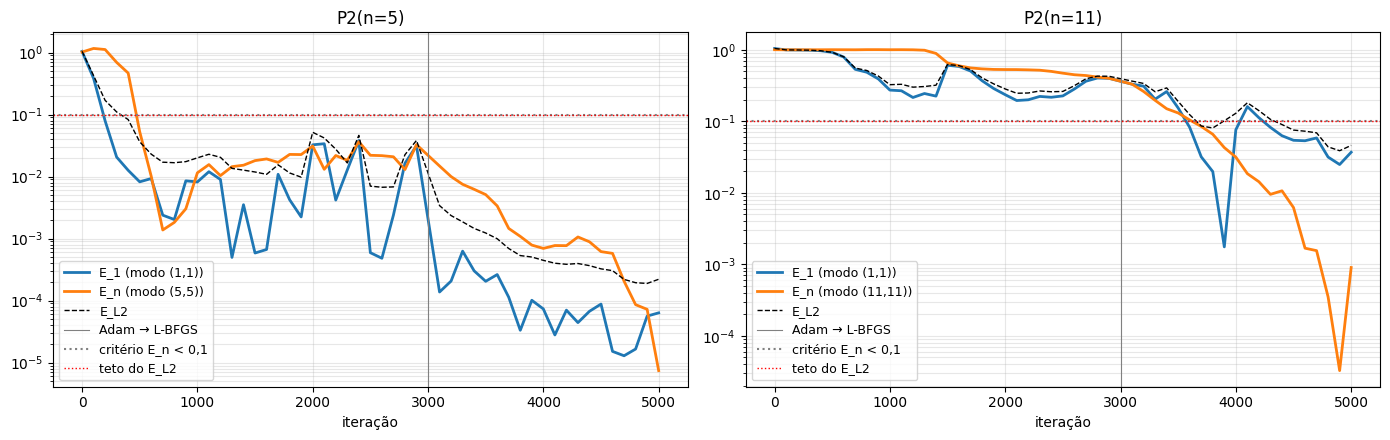

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for j, n in enumerate([5, 11]):
    prob, rede, hist, tempo, m = resultados[f"P2(n={n})"]
    ax[j].semilogy(hist["aval_it"], hist["E_1"], label="E_1 (modo (1,1))", lw=2)
    ax[j].semilogy(hist["aval_it"], hist["E_n"], label=f"E_n (modo ({n},{n}))", lw=2)
    ax[j].semilogy(hist["aval_it"], hist["L2"], "k--", label="E_L2", lw=1)
    ax[j].axvline(hist["fim_adam"], color="gray", ls="-", lw=.8, label="Adam → L-BFGS")
    ax[j].axhline(0.1, color="gray", ls=":", label="critério E_n < 0,1")
    ax[j].axhline(TETO_L2, color="r", ls=":", lw=1, label="teto do E_L2")
    ax[j].set_title(f"P2(n={n})")
    ax[j].set_xlabel("iteração")
    ax[j].legend(fontsize=9)
    ax[j].grid(True, which="both", alpha=.3)
plt.tight_layout()
plt.show()

### Espectro: coeficientes $|a_{mk}|$ da solução exata e da PINN

Cada pixel é a amplitude de um modo $\varphi_{mk}$ (eixos até 16). A exata tem só dois pixels acesos. Na PINN, energia espalhada fora deles é o que $E_{\text{esp}}$ mede.

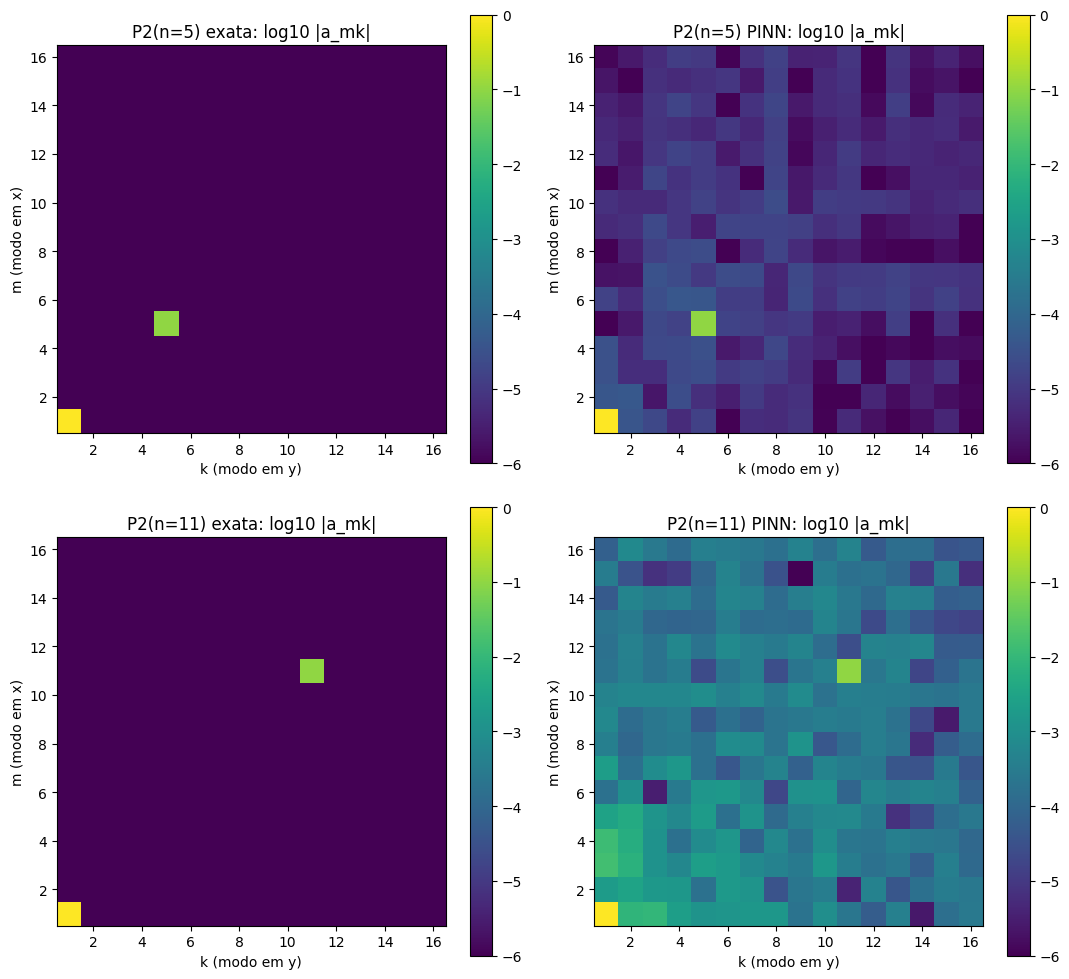

In [18]:
K = 16
fig, ax = plt.subplots(2, 2, figsize=(11, 10))
for j, n in enumerate([5, 11]):
    prob, rede, hist, tempo, m = resultados[f"P2(n={n})"]
    _, Xg, Yg = grade_interior(63)
    a_exata = coeficientes_seno(prob["u"](Xg.double(), Yg.double()).cpu().numpy())
    for i, (a, titulo) in enumerate([(a_exata, "exata"), (m["coef"], "PINN")]):
        im = ax[j, i].imshow(np.log10(np.abs(a[:K, :K]) + 1e-8), origin="lower", vmin=-6, vmax=0,
                             extent=[0.5, K + 0.5, 0.5, K + 0.5], cmap="viridis")
        ax[j, i].set_title(f"P2(n={n}) {titulo}: log10 |a_mk|")
        ax[j, i].set_xlabel("k (modo em y)")
        ax[j, i].set_ylabel("m (modo em x)")
        plt.colorbar(im, ax=ax[j, i])
plt.tight_layout()
plt.show()

---
## 7. Tabela de resultados

Uma semente só. No experimento final cada configuração roda com $N = 10$ sementes e os resultados são reportados como média, desvio padrão e IC 95% (TCC §3.4). Para isso, basta chamar `treinar_pinn(prob, semente=s)` para `s` em `range(10)`.

In [19]:
print(f"{'benchmark':>10} {'E_L2':>9} {'E_H1':>9} {'L_PDE':>9} {'E_n':>7} {'E_1':>9} {'E_esp':>9} {'tempo (s)':>10} {'TTS (s)':>8} {'iterações':>10} {'platô':>6} {'E_bal':>9}")
for nome, (prob, rede, hist, tempo, m) in resultados.items():
    if "n" in prob:
        tts = time_to_solution(hist, "E_n", 0.1)          # criterio espectral para P2
        esp = f"{m['E_n']:7.3f} {m['E_1']:9.2e} {m['E_esp']:9.2e}"
    else:
        tts = time_to_solution(hist, "L2", 1e-2)          # criterio E_L2 < 1% para os demais
        esp = f"{'-':>7} {'-':>9} {'-':>9}"
    tts = f"{tts:8.1f}" if tts is not None else f"{'não':>8}"
    print(f"{nome:>10} {m['L2']:9.2e} {m['H1']:9.2e} {m['PDE']:9.2e} {esp} {tempo:10.1f} {tts} {hist['it_final']:10d} {'sim' if hist['platô'] else 'não':>6} {balanco_global(rede, prob):9.1e}")

print(f"\nTTS: time-to-solution, tempo a partir do qual o criterio vale ate o fim do treino.")
print(f"L0/P0/P1: E_L2 < 1e-2. P2: E_n < 0,1. Teto do E_L2 em P2: {TETO_L2:.4f}")

 benchmark      E_L2      E_H1     L_PDE     E_n       E_1     E_esp  tempo (s)  TTS (s)  iterações  platô     E_bal
        L0  4.06e-03  1.13e-02  2.76e-06       -         -         -      130.1     69.9       4460    sim   1.0e-05
        P0  3.93e-04  1.73e-03  9.11e-05       -         -         -      179.3     40.1       5000    não   4.0e-05
        P1  9.03e-05  3.65e-04  1.57e-05       -         -         -      123.6     47.4       4340    sim   1.1e-05
   P2(n=5)  2.21e-04  1.24e-03  1.60e-03   0.000  6.36e-05  2.13e-04      176.7      9.2       5000    não   4.3e-05
  P2(n=11)  4.60e-02  7.79e-02  1.18e+02   0.001  3.69e-02  2.79e-02      175.6     94.3       5000    não   6.5e-03

TTS: time-to-solution, tempo a partir do qual o criterio vale ate o fim do treino.
L0/P0/P1: E_L2 < 1e-2. P2: E_n < 0,1. Teto do E_L2 em P2: 0.0995


### Como ler a tabela

Todas as linhas usam **contorno fraco** (o núcleo).

- **L0, P0 e P1** passam no critério $\mathcal{E}_{L^2} < 10^{-2}$: $4 \times 10^{-3}$, $4 \times 10^{-4}$ e $9 \times 10^{-5}$. O balanço global fica em $\mathcal{E}_{\text{bal}} \le 4 \times 10^{-5}$.
  - O fraco é pior que o contorno exato nesses três (a seção 9 mede quanto). Em L0, o erro está concentrado perto da borda, onde $u^*$ é imposto só pela perda.
  - O P0 reescalado (amplitude ~1) foi até o teto de 5000 iterações, ainda melhorando.
- **P2(5)** acerta os dois modos ($E_n < 10^{-3}$, $E_1 \sim 6 \times 10^{-5}$).
- **P2(11)** também acerta os dois modos: $E_n \approx 0{,}001$, $E_1 \approx 0{,}04$, $\mathcal{E}_{L^2} \approx 0{,}05$. O modo alto **é** aprendido. O balanço global ($6{,}5 \times 10^{-3}$) é o maior da tabela, mas bem abaixo de 0,1.
- **"Parou no platô" não quer dizer "convergiu"**, e "não parou" não quer dizer "falhou": P0 e os dois P2 foram até o teto ainda melhorando.
- **$\mathcal{E}_{H^1} > \mathcal{E}_{L^2}$** em todos os casos: o erro no gradiente é maior que no valor.
- A coluna $\mathcal{L}_{PDE}$ está sem o peso $\lambda_{PDE}$, por isso é grande em P2(11), onde $|f|$ chega a ~$10^4$. Só compare dentro do mesmo benchmark.

---
## 8. Sementes: estatística em escala log, comparação pareada e equivalência

Uma execução só não diz se uma diferença entre configurações é real ou é sorte da inicialização. O TCC (§3.4) prevê $N = 10$ sementes por configuração.

A semente controla **duas** coisas: a inicialização dos pesos e o sorteio LHS dos pontos de colocação. Isso atende à condição 3 da §10 do documento.

### Por que escala log

Os erros variam em ordens de grandeza entre configurações e, às vezes, entre sementes. A média aritmética fica dominada pela pior semente. Por isso as contas são feitas em $\ell_s = \log_{10} e_s$:

$$
\bar\ell = \frac{1}{N}\sum_s \ell_s, \qquad
s_\ell = \sqrt{\tfrac{1}{N-1}\textstyle\sum_s (\ell_s - \bar\ell)^2}, \qquad
\text{IC}_{95\%} = \bar\ell \pm t_{0{,}975;\,N-1}\,\frac{s_\ell}{\sqrt N}
$$

e voltam para a escala original: $10^{\bar\ell}$ é a **média geométrica**, $10^{s_\ell}$ é o **fator de dispersão** (um fator 1,5 quer dizer que uma semente típica erra até 1,5 vez para mais ou para menos), e o IC vira um intervalo multiplicativo.

### Comparação pareada

Com a mesma semente, duas configurações usam **os mesmos pontos de colocação**. Então a comparação certa é **por par**: para cada semente, $d_s = \log_{10} e^{A}_s - \log_{10} e^{B}_s$. Testamos se a mediana (Wilcoxon) e a média ($t$ pareado) de $d_s$ são zero. A razão $10^{\bar d}$ diz quantas vezes $A$ erra mais (ou menos) que $B$.

Com $N$ pares, o menor valor-$p$ possível do Wilcoxon bilateral é $2/2^N$: com $N = 5$ ele é 0,0625, e **nunca** dá significância a 5%. Com $N = 10$ o mínimo é 0,002.

### Equivalência (TOST)

"Sem diferença significativa" **não** prova que duas configurações são equivalentes: com poucas sementes, quase nada é significativo. Para afirmar equivalência (o que a H1 precisa para o DDP), o teste certo é o **TOST** (*two one-sided tests*):

1. Fixa-se **antes do experimento** uma margem para a razão geométrica $A/B$, por exemplo $[0{,}8;\ 1{,}25]$ (até 25% para cada lado em escala multiplicativa).
2. Testa-se, em log, se a média de $d_s$ está acima do limite inferior **e** abaixo do superior.
3. Equivalência é aceita se os dois testes rejeitam a 5%. É o mesmo que o **IC 90%** da razão ficar inteiro dentro da margem.

In [20]:
N_SEMENTES = 10
SEMENTES = list(range(N_SEMENTES))


def resumo_log(valores):
    # Media geometrica, fator de dispersao e IC 95% calculados em log10
    l = np.log10(np.asarray(valores, dtype=float))
    media, dp = l.mean(), l.std(ddof=1)
    meia = stats.t.ppf(0.975, len(l) - 1) * dp / np.sqrt(len(l))
    return 10**media, 10**dp, (10**(media - meia), 10**(media + meia))


def rodar_sementes(treinar, prob, sementes, **kw):
    # treinar: treinar_pinn ou treinar_xpinn (mesma assinatura)
    linhas = []
    for s in sementes:
        rede, hist, tempo = treinar(prob, semente=s, imprimir=False, **kw)
        m = avaliar(rede, prob)
        linhas.append({"semente": s, "L2": m["L2"], "H1": m["H1"], "tempo": tempo,
                       "E_n": m.get("E_n"), "E_1": m.get("E_1"), "platô": hist["platô"], "hist": hist})
        extra = f" | E_n {m['E_n']:.3f} | E_1 {m['E_1']:.2e}" if "E_n" in m else ""
        print(f"  semente {s}: E_L2 {m['L2']:.2e} | E_H1 {m['H1']:.2e}{extra} | tempo {tempo:.1f} s")
    return linhas


def imprimir_resumo(linhas, chaves=("L2", "H1")):
    print(f"\n{'métrica':>8} {'média geom.':>12} {'fator disp.':>12} {'IC 95% (geom.)':>26}")
    for k in chaves:
        g, fator, (lo, hi) = resumo_log([l[k] for l in linhas])
        print(f"{k:>8} {g:12.2e} {fator:12.2f}   [{lo:9.2e}, {hi:9.2e}]")
    t = [l["tempo"] for l in linhas]
    print(f"{'tempo':>8} {np.mean(t):12.1f} s (média aritmética; desvio {np.std(t, ddof=1):.1f} s)")


def comparar_pareado(a, b, nome_a="A", nome_b="B"):
    # a, b: listas de erros, mesma ordem de sementes
    la, lb = np.log10(a), np.log10(b)
    d = la - lb
    t = stats.ttest_rel(la, lb)
    w = stats.wilcoxon(la, lb)
    razao = 10**d.mean()
    print(f"{nome_a} / {nome_b}: razão geométrica {razao:.2f} "
          f"({'pior' if razao > 1 else 'melhor'}) | {nome_a} pior em {np.sum(d > 0)} de {len(d)} sementes")
    print(f"  t pareado em log10: p = {t.pvalue:.3g} | Wilcoxon: p = {w.pvalue:.3g}")
    return razao, t.pvalue, w.pvalue


def tost_log(a, b, margem=(0.8, 1.25)):
    # Teste de equivalencia (TOST) pareado em log10: A e B sao equivalentes se a razao geometrica
    # A/B esta dentro da margem fixada ANTES do experimento. Equivale a IC 90% dentro da margem.
    d = np.log10(a) - np.log10(b)
    lo, hi = np.log10(margem[0]), np.log10(margem[1])
    p_inf = stats.ttest_1samp(d, lo, alternative="greater").pvalue
    p_sup = stats.ttest_1samp(d, hi, alternative="less").pvalue
    meia = stats.t.ppf(0.95, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    return 10**d.mean(), (10**(d.mean() - meia), 10**(d.mean() + meia)), max(p_inf, p_sup)

P1, PINN monolítica, 10 sementes


  semente 0: E_L2 9.03e-05 | E_H1 3.65e-04 | tempo 125.1 s


  semente 1: E_L2 1.12e-04 | E_H1 4.62e-04 | tempo 113.2 s


  semente 2: E_L2 1.27e-04 | E_H1 5.13e-04 | tempo 119.7 s


  semente 3: E_L2 1.27e-04 | E_H1 4.82e-04 | tempo 115.4 s


  semente 4: E_L2 1.37e-04 | E_H1 5.78e-04 | tempo 102.0 s


  semente 5: E_L2 9.01e-05 | E_H1 4.09e-04 | tempo 114.7 s


  semente 6: E_L2 1.83e-04 | E_H1 7.30e-04 | tempo 118.4 s


  semente 7: E_L2 1.03e-04 | E_H1 3.85e-04 | tempo 129.5 s


  semente 8: E_L2 1.24e-04 | E_H1 4.84e-04 | tempo 117.3 s


  semente 9: E_L2 1.41e-04 | E_H1 6.24e-04 | tempo 139.9 s

 métrica  média geom.  fator disp.             IC 95% (geom.)
      L2     1.21e-04         1.24   [ 1.04e-04,  1.41e-04]
      H1     4.92e-04         1.24   [ 4.21e-04,  5.76e-04]
   tempo        119.5 s (média aritmética; desvio 10.2 s)


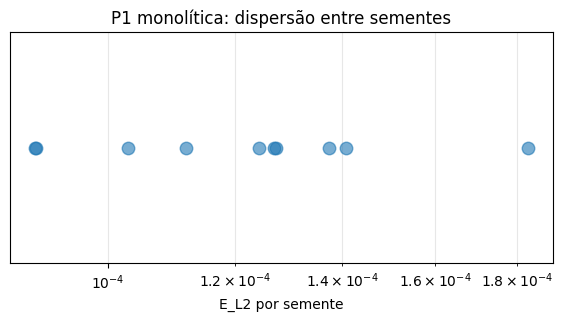

In [21]:
print("P1, PINN monolítica,", N_SEMENTES, "sementes")
sementes_P1 = rodar_sementes(treinar_pinn, criar_problema("P1"), SEMENTES)
imprimir_resumo(sementes_P1)

plt.figure(figsize=(7, 3))
plt.semilogx([l["L2"] for l in sementes_P1], np.zeros(N_SEMENTES), "o", ms=9, alpha=.6)
plt.yticks([])
plt.xlabel("E_L2 por semente")
plt.title("P1 monolítica: dispersão entre sementes")
plt.grid(True, which="both", alpha=.3)
plt.show()

**Como ler:**

- Em P1, a média geométrica do $\mathcal{E}_{L^2}$ é $1{,}2 \times 10^{-4}$, com fator de dispersão 1,24: uma semente típica erra até ~1,24 vez para mais ou para menos que a média geométrica.
- A semente 0, usada na seção 5 ($9{,}0 \times 10^{-5}$), é uma das duas melhores das 10. Um valor de uma semente só pode não ser representativo, nos dois sentidos.
- O tempo vai de 102 a 140 s (média 120 s, na GPU), porque a parada por platô depende da trajetória. Para comparar configurações, o *time-to-solution* é mais justo que o tempo total.

---
## 9. Sensibilidade à formulação do contorno (monolítica): fraco × exato ($D$ produto) × exato transfinito

O núcleo usa contorno fraco. Esta seção roda as duas formulações exatas **só na monolítica**, para medir o quanto a escolha da formulação muda o resultado.

### Três efeitos que se misturam em P2

**1. A perda de resíduo pesa cada modo pelo quadrado do autovalor.** Se a rede erra o coeficiente do modo $\varphi_{mk}$ por $\delta$, o resíduo ganha $\delta\,(m^2+k^2)\pi^2\,\varphi_{mk}$, e o custo na perda é $\propto \delta^2 (m^2+k^2)^2$. O mesmo erro custa $n^4$ vezes mais no modo $(n,n)$ que no $(1,1)$; para $n = 11$, ~14.600 vezes. Isso vale para **qualquer** formulação e arquitetura, porque a $\mathcal{L}_{PDE}$ é a mesma.

**2. Com penalidade, o peso escolhido acopla $n$ à borda.** $\lambda_{PDE} = 1/\overline{f^2}$ cai com $n^4$, então o peso do modo baixo em relação à borda cai ~40 vezes entre $n = 5$ e $n = 13$.

**3. Com $D$ produto, a rede aprende $u^*/D$, não $u^*$.** Como $D$ se anula linearmente nos lados e quadraticamente nos cantos:

- P1: $\varphi_{11}/D$ vai de $\pi^2 \approx 9{,}9$ nos cantos a 16 no centro. É quase constante.
- Modo alto: $\sin(n\pi x)/x \to n\pi$, então $\varepsilon\varphi_{nn}/D$ chega a $\varepsilon(n\pi)^2 \approx 119$ nos cantos para $n = 11$, contra 1,6 no centro. A parte difícil fica **concentrada e ampliada perto da borda**.

Isso **não é exclusivo deste $D$.** Qualquer $D$ suave que zere nos quatro lados precisa zerar pelo menos quadraticamente nos cantos, então todo ansatz multiplicativo $D \cdot \mathrm{NN}$ amplia o modo alto ali. A alternativa que elimina o quociente é a **transfinita** (seção 4): a rede representa $u^*$ diretamente.

P1:         phi_11 / D  entre 9.9 e 16.0
P2(n=11):   0,1 phi_11,11 / D  com |.| máximo 120  (centro: 1.6)


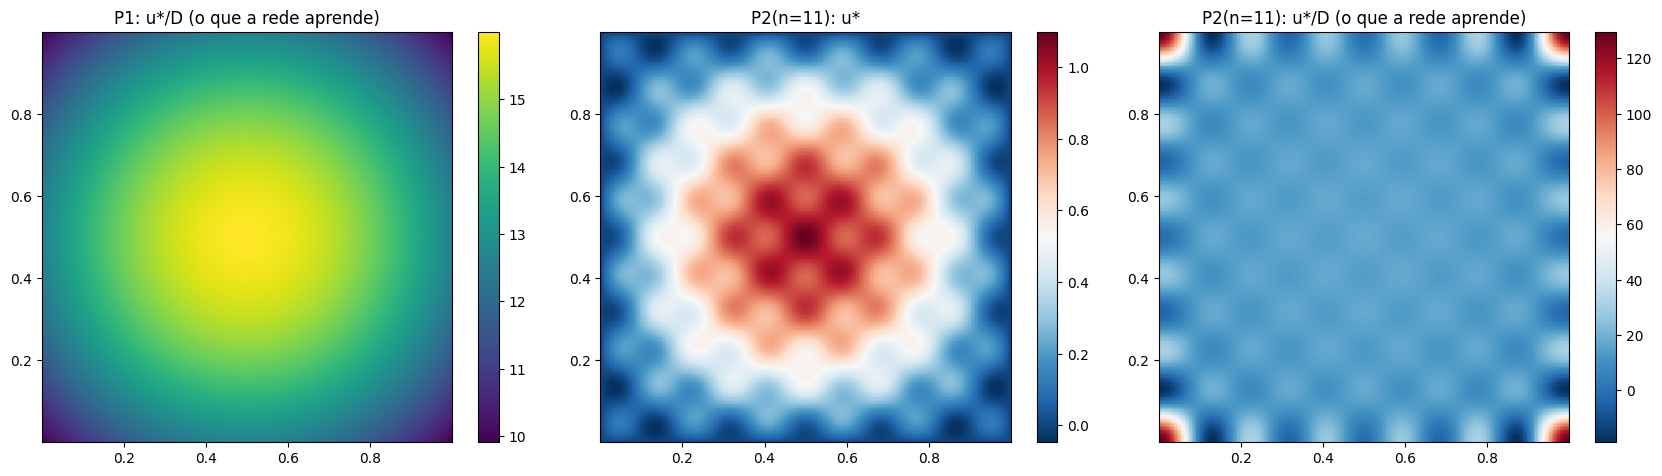

In [22]:
g = torch.linspace(0.002, 0.998, 300, dtype=torch.float64, device="cpu")
X, Y = torch.meshgrid(g, g, indexing="ij")
D = distancia_contorno(X, Y)
P1q = criar_problema("P1")["u"](X, Y) / D
altoq = 0.1 * phi(11, 11, X, Y) / D

print(f"P1:         phi_11 / D  entre {P1q.min():.1f} e {P1q.max():.1f}")
print(f"P2(n=11):   0,1 phi_11,11 / D  com |.| máximo {altoq.abs().max():.0f}  (centro: {0.1 * 16:.1f})")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, Z, titulo in [(ax[0], P1q, "P1: u*/D (o que a rede aprende)"),
                     (ax[1], criar_problema("P2", n=11)["u"](X, Y), "P2(n=11): u*"),
                     (ax[2], criar_problema("P2", n=11)["u"](X, Y) / D, "P2(n=11): u*/D (o que a rede aprende)")]:
    im = a.pcolormesh(X, Y, Z, shading="auto", cmap="RdBu_r" if "P2" in titulo else "viridis")
    a.set_title(titulo)
    a.set_aspect("equal")
    plt.colorbar(im, ax=a)
plt.tight_layout()
plt.show()

### Benchmarks simples, uma semente

Contorno exato com $D$ produto e transfinito em L0, P0, P1 e P2(5), comparados com o contorno fraco das seções 5 e 6 (o núcleo). Em P2(11), o fraco **sem** normalização ($\lambda_{PDE} = 1$) mostra o papel do fator $1/\overline{f^2}$.

In [23]:
simples = {}
for nome, kw, contorno, lp in [("L0", {}, "exato", "auto"), ("P0", {}, "exato", "auto"), ("P1", {}, "exato", "auto"),
                                ("P2", {"n": 5}, "exato", "auto"),
                                ("L0", {}, "transfinito", "auto"), ("P0", {}, "transfinito", "auto"),
                                ("P1", {}, "transfinito", "auto"), ("P2", {"n": 5}, "transfinito", "auto"),
                                ("P2", {"n": 11}, "fraco", 1.0)]:
    prob = criar_problema(nome, **kw)
    rede, hist, tempo = treinar_pinn(prob, contorno=contorno, lam_pde=lp, imprimir=False)
    simples[(prob["nome"], contorno, lp)] = (avaliar(rede, prob), balanco_global(rede, prob), tempo)

ROTULOS = {"fraco": "fraco", "exato": "exato (D produto)", "transfinito": "transfinito"}
print(f"{'benchmark':>10} {'formulação':>24} {'E_L2':>9} {'E_n':>7} {'E_1':>9} {'E_bal':>9} {'tempo (s)':>10}")
def linha(nome, rotulo, m, bal, tempo):
    en = f"{m['E_n']:7.3f} {m['E_1']:9.2e}" if "E_n" in m else f"{'-':>7} {'-':>9}"
    print(f"{nome:>10} {rotulo:>24} {m['L2']:9.2e} {en} {bal:9.1e} {tempo:10.1f}")

for nome in ["L0", "P0", "P1", "P2(n=5)", "P2(n=11)"]:
    if nome in resultados:
        prob_r, rede, hist, tempo, m = resultados[nome]
        linha(nome, "fraco (núcleo)", m, balanco_global(rede, prob_r), tempo)
    for (n_, contorno, lp), (m, bal, tempo) in simples.items():
        if n_ == nome:
            linha(nome, ROTULOS[contorno] + (", lam_PDE = 1" if lp == 1.0 else ""), m, bal, tempo)


 benchmark               formulação      E_L2     E_n       E_1     E_bal  tempo (s)
        L0           fraco (núcleo)  4.06e-03       -         -   1.0e-05      130.1
        L0        exato (D produto)  1.05e-05       -         -   1.4e-06      135.3
        L0              transfinito  1.05e-05       -         -   5.6e-06      424.5
        P0           fraco (núcleo)  3.93e-04       -         -   4.0e-05      179.3
        P0        exato (D produto)  3.41e-05       -         -   2.5e-06      106.1
        P0              transfinito  4.30e-05       -         -   1.8e-05      416.1
        P1           fraco (núcleo)  9.03e-05       -         -   1.1e-05      123.6
        P1        exato (D produto)  7.16e-06       -         -   8.5e-06      221.8
        P1              transfinito  1.91e-04       -         -   2.6e-04      298.9
   P2(n=5)           fraco (núcleo)  2.21e-04   0.000  6.36e-05   4.3e-05      176.7
   P2(n=5)        exato (D produto)  1.93e-04   0.000  1.21e-04  

### P2(11): as três formulações com várias sementes, pareadas

A monolítica com $D$ produto foi bimodal na versão anterior ($E_1$ de 0,01 a 1,5 entre sementes), então uma semente não decide nada. Aqui as três formulações rodam com as mesmas 6 sementes (mesmos pontos de colocação por semente) e são comparadas pelo teste pareado da seção 8. Com 6 pares, o menor valor-$p$ possível do Wilcoxon é $2/2^6 \approx 0{,}031$.


Contorno fraco


  semente 0: E_L2 4.60e-02 | E_H1 7.79e-02 | E_n 0.001 | E_1 3.69e-02 | tempo 179.0 s


  semente 1: E_L2 1.21e-02 | E_H1 4.09e-02 | E_n 0.002 | E_1 8.18e-03 | tempo 178.2 s


  semente 2: E_L2 6.38e-03 | E_H1 1.84e-02 | E_n 0.003 | E_1 3.91e-03 | tempo 178.4 s


  semente 3: E_L2 8.78e-03 | E_H1 3.14e-02 | E_n 0.001 | E_1 9.01e-04 | tempo 178.9 s


  semente 4: E_L2 2.46e-03 | E_H1 9.69e-03 | E_n 0.001 | E_1 1.34e-03 | tempo 179.7 s


... (9 outputs left out)

  semente 2: E_L2 7.09e-03 | E_H1 1.05e-02 | E_n 0.001 | E_1 6.16e-03 | tempo 615.8 s


  semente 3: E_L2 2.59e-02 | E_H1 3.18e-02 | E_n 0.004 | E_1 2.42e-02 | tempo 663.0 s


  semente 4: E_L2 3.27e-02 | E_H1 4.34e-02 | E_n 0.002 | E_1 2.69e-02 | tempo 659.6 s


  semente 5: E_L2 6.57e-01 | E_H1 6.90e-01 | E_n 0.126 | E_1 6.13e-01 | tempo 645.0 s


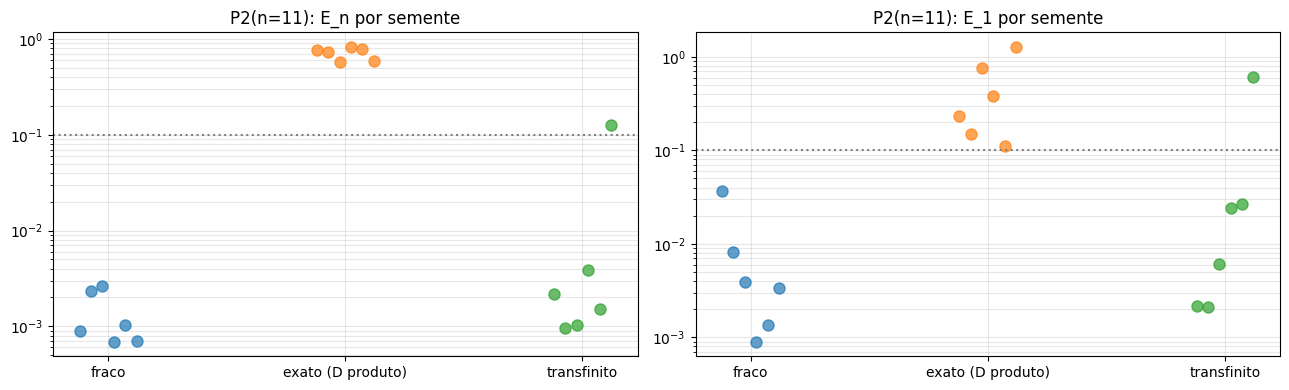


[E_n]  medianas: fraco 9.64e-04 | exato 7.45e-01 | transfinito 1.85e-03
exato / fraco: razão geométrica 597.06 (pior) | exato pior em 6 de 6 sementes
  t pareado em log10: p = 2.52e-06 | Wilcoxon: p = 0.0312
transfinito / exato: razão geométrica 0.00 (melhor) | transfinito pior em 0 de 6 sementes
  t pareado em log10: p = 0.00101 | Wilcoxon: p = 0.0312
transfinito / fraco: razão geométrica 2.89 (pior) | transfinito pior em 4 de 6 sementes
  t pareado em log10: p = 0.303 | Wilcoxon: p = 0.438

[E_1]  medianas: fraco 3.65e-03 | exato 3.08e-01 | transfinito 1.52e-02
exato / fraco: razão geométrica 81.56 (pior) | exato pior em 6 de 6 sementes
  t pareado em log10: p = 0.00146 | Wilcoxon: p = 0.0312
transfinito / exato: razão geométrica 0.04 (melhor) | transfinito pior em 0 de 6 sementes
  t pareado em log10: p = 0.00742 | Wilcoxon: p = 0.0312
transfinito / fraco: razão geométrica 3.66 (pior) | transfinito pior em 4 de 6 sementes
  t pareado em log10: p = 0.347 | Wilcoxon: p = 0.312

[L2] 

In [24]:
N_FORM = 6
SEMENTES_FORM = list(range(N_FORM))
prob11 = criar_problema("P2", n=11)

formulacoes = {}
for contorno in ["fraco", "exato", "transfinito"]:
    print(f"\nContorno {contorno}")
    formulacoes[contorno] = rodar_sementes(treinar_pinn, prob11, SEMENTES_FORM, contorno=contorno)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, chave in enumerate(["E_n", "E_1"]):
    for i, contorno in enumerate(formulacoes):
        v = [l[chave] for l in formulacoes[contorno]]
        ax[j].semilogy(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, "o", ms=8, alpha=.7)
    ax[j].set_xticks(range(3))
    ax[j].set_xticklabels(["fraco", "exato (D produto)", "transfinito"])
    ax[j].axhline(0.1, color="gray", ls=":")
    ax[j].set_title(f"P2(n=11): {chave} por semente")
    ax[j].grid(True, which="both", alpha=.3)
plt.tight_layout()
plt.show()

for chave in ["E_n", "E_1", "L2"]:
    print(f"\n[{chave}]  medianas: " + " | ".join(f"{c} {np.median([l[chave] for l in formulacoes[c]]):.2e}" for c in formulacoes))
    comparar_pareado([l[chave] for l in formulacoes["exato"]], [l[chave] for l in formulacoes["fraco"]], "exato", "fraco")
    comparar_pareado([l[chave] for l in formulacoes["transfinito"]], [l[chave] for l in formulacoes["exato"]], "transfinito", "exato")
    comparar_pareado([l[chave] for l in formulacoes["transfinito"]], [l[chave] for l in formulacoes["fraco"]], "transfinito", "fraco")

### Como ler

**Benchmarks simples (uma semente).**
- **O contorno exato com $D$ produto é melhor que o fraco em L0, P0 e P1:** ~400 vezes em L0 ($1{,}0 \times 10^{-5}$ contra $4{,}1 \times 10^{-3}$) e ~12 vezes em P0 e P1. Em P2(5) as três formulações empatam.
- **O transfinito** empata com o $D$ produto em L0 e P0. Em P1 é pior que o fraco nesta semente ($1{,}9 \times 10^{-4}$). Custa de 2 a 4 vezes mais tempo por execução (300 a 600 s).
- **O fraco sem normalização** ($\lambda_{PDE} = 1$) falha em P2(11): $E_n \approx 0{,}26$ e $\mathcal{E}_{L^2} \approx 1$.

**P2(11), 6 sementes pareadas: o resultado principal desta seção.**

| | $E_n$ mediano | $E_1$ mediano | $\mathcal{E}_{L^2}$ mediano |
|---|---|---|---|
| Fraco (núcleo) | 0,001 | 0,004 | 0,008 |
| Exato, $D$ produto | **0,75** | **0,31** | **0,43** |
| Exato, transfinito | 0,002 | 0,015 | 0,017 |

- **$D$ produto contra fraco:** pior **em todas as 6 sementes**. Em $E_n$, a razão geométrica é ~600 ($t$ pareado $p \approx 2{,}5 \times 10^{-6}$; Wilcoxon $p \approx 0{,}031$, o mínimo possível com 6 pares).
- **Transfinito contra fraco:** sem diferença significativa em nenhuma métrica ($p \ge 0{,}3$). Mas a semente 5 do transfinito falhou parcialmente ($E_n \approx 0{,}13$, $\mathcal{E}_{L^2} \approx 0{,}66$). O fraco não falhou em nenhuma.
- **A falha da monolítica no modo alto de P2(11) é efeito do quociente $u^*/D$, e não da rede.** Sem quociente (transfinito) ou sem contorno imposto (fraco), a mesma rede acerta o modo $(11, 11)$.

**Consequências (já aplicadas neste notebook):**

1. **O contorno fraco é o núcleo** das três arquiteturas. Ele é barato, não falhou em nenhuma semente de P2(11) e é o único que se aplica igual à monolítica, ao DDP e ao XPINN. O custo é a acurácia em L0, P0 e P1 ($10^{-4}$ a $4 \times 10^{-3}$, contra ~$10^{-5}$ com contorno exato), ainda dentro do critério $10^{-2}$.
2. **O $D$ produto e o transfinito ficam só como sensibilidade**, na monolítica.
3. **Tudo o que a versão anterior mediu com $D$ produto em P2 foi refeito** com contorno fraco (seções 11 e 13).

---
## 10. DDP real com processos `gloo`

### O que o DDP faz

- O treino roda em $p$ processos. Cada um tem uma **cópia idêntica** da rede.
- Os $N_f$ pontos de colocação (e os $N_b$ de contorno) são divididos em $p$ fatias **de tamanho igual**.
- Cada processo calcula a perda **média nas suas fatias** e o gradiente dela.
- No `backward`, o DDP faz um **all-reduce**: soma os gradientes dos processos e divide por $p$. Todos aplicam o mesmo gradiente médio, então as cópias continuam idênticas.

Com fatias iguais, a média das médias locais é a média global, e o gradiente é o mesmo do treino sequencial (§10 do documento). O DDP muda **o custo**, não o problema de otimização.

### Detalhes da implementação (em `treinar_pinn(..., distribuido=True)`)

| Condição | Como foi garantida |
|---|---|
| Contorno fraco | Os $N_b$ pontos de contorno também são divididos em fatias iguais: `assert N_b % p == 0` |
| Mesmo conjunto global de pontos | Todos os processos sorteiam o mesmo LHS com a mesma semente e ficam com `torch.chunk(...)[rank]` |
| Partição igual (interior e contorno) | `assert N_f % p == 0 and N_b % p == 0` |
| $\lambda_{PDE}$ igual em todos | Calculado com $\overline{f^2}$ **global**, antes da partição |
| Um forward por backward | Interior e contorno passam juntos pela rede |
| L-BFGS sincronizado | A *closure* devolve a perda **média entre processos**. Sem isso, cada processo veria um valor diferente na busca de linha, escolheria um passo diferente, e as cópias da rede se separariam. O critério de platô usa essa mesma perda global, então todos param juntos |
| Mesmo orçamento de threads | 1 thread por processo, em CPU; a referência sequencial também roda em CPU com 1 thread |

### Por que um script

`torch.distributed` precisa de vários **processos**, e o notebook é um processo só. Então:

1. A célula abaixo grava `pinn_comum.py` copiando o **código-fonte das funções deste notebook** (`inspect.getsource`). Para a classe `ContornoExato`, o Jupyter não guarda a origem da classe, então a célula em que ela foi definida é copiada inteira (por isso ela está numa célula só com definições). Não há uma segunda versão do código: o script usa exatamente o mesmo.
2. `ddp_pinn.py` só lê os argumentos, chama `treinar_pinn(..., distribuido=True)` e salva o resultado. Com `--sequencial`, chama `treinar_pinn(..., distribuido=False)` num processo só: é a **referência sequencial em CPU**, com o mesmo código e o mesmo orçamento de threads.
3. O notebook dispara os $p$ processos diretamente, com as variáveis `RANK`, `WORLD_SIZE`, `MASTER_ADDR` e `MASTER_PORT` que o `torchrun` definiria (inicialização `env://`). Motivo: neste Windows, o `torchrun` do PyTorch 2.13 falha ao criar o `TCPStore`, porque o binário não tem suporte a libuv; com `USE_LIBUV=0` e `env://`, a inicialização funciona.
4. O *backend* é `gloo`, em CPU. O `nccl` exige uma GPU por processo, e esta máquina tem uma só.

In [25]:
CABECALHO = """import math
import time

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from scipy.fft import dstn
from scipy.stats import qmc

SEMENTE = 0
"""


def codigo_fonte(obj):
    # Funcoes: inspect.getsource. Classes: o Jupyter nao guarda a origem da classe,
    # entao copiamos a celula inteira em que o metodo forward foi definido.
    if inspect.isclass(obj):
        return "".join(linecache.getlines(inspect.getsourcefile(obj.forward)))
    return inspect.getsource(obj)


OBJETOS_COMUNS = [phi, L0_u, L0_f, P0_u, P0_f, P1_u, P1_f, P2_u, P2_f, L1_u, L1_f, criar_problema,
                  laplaciano, grade_interior, coeficientes_seno, metricas_espectrais, avaliar,
                  criar_rede, pontos_colocacao, pontos_contorno, ContornoExato, otimizar, treinar_pinn]

with open("pinn_comum.py", "w", encoding="utf-8") as arquivo:     # o codigo tem acentos ("platô")
    arquivo.write("# Gerado automaticamente a partir do notebook. Nao editar a mao.\n")
    arquivo.write(CABECALHO)
    for objeto in OBJETOS_COMUNS:
        arquivo.write("\n\n" + codigo_fonte(objeto))

import importlib
import pinn_comum                       # confere que o modulo gerado importa sem erro
importlib.reload(pinn_comum)
print("pinn_comum.py gravado e importado:", len(OBJETOS_COMUNS), "objetos")

pinn_comum.py gravado e importado: 23 objetos


In [26]:
%%writefile ddp_pinn.py
import argparse
import json
import math
import warnings

import torch
import torch.distributed as dist

from pinn_comum import avaliar, criar_problema, treinar_pinn

warnings.filterwarnings("ignore")

parser = argparse.ArgumentParser()
parser.add_argument("--problema", required=True)
parser.add_argument("--n", type=int, default=None)
parser.add_argument("--semente", type=int, default=0)
parser.add_argument("--contorno", default="fraco")
parser.add_argument("--N_f", type=int, default=2000)
parser.add_argument("--N_b", type=int, default=400)
parser.add_argument("--epocas_adam", type=int, default=3000)
parser.add_argument("--passos_lbfgs", type=int, default=100)
parser.add_argument("--sem_plato", action="store_true")      # orcamento fixo: roda todos os passos do L-BFGS
parser.add_argument("--sem_avaliacao", action="store_true")  # medicao de tempo: avalia so no inicio e no fim
parser.add_argument("--sequencial", action="store_true")     # referencia: treino sem distribuir, 1 processo
parser.add_argument("--M", type=int, default=0)               # 0: monolitica (DDP); M > 0: XPINN M x M distribuido
parser.add_argument("--lam_i", type=float, default=1.0)       # so no XPINN
parser.add_argument("--saida", required=True)
args = parser.parse_args()

torch.set_num_threads(1)
distribuido = not args.sequencial
if distribuido:
    dist.init_process_group("gloo")      # env://: RANK, WORLD_SIZE, MASTER_ADDR, MASTER_PORT (e USE_LIBUV=0)
rank = dist.get_rank() if distribuido else 0

prob = criar_problema(args.problema, n=args.n)
kw = dict(contorno=args.contorno, N_f=args.N_f, N_b=args.N_b, epocas_adam=args.epocas_adam,
          passos_lbfgs_max=args.passos_lbfgs, semente=args.semente, distribuido=distribuido, imprimir=False)
if args.sem_plato:
    kw["tolerancia_plato"] = -math.inf
if args.sem_avaliacao:
    kw["avaliar_a_cada"] = 10**9
if args.M > 0:
    from pinn_xpinn import treinar_xpinn          # gerado na secao 11
    rede, hist, tempo = treinar_xpinn(prob, M=args.M, lam_i=args.lam_i, **kw)
else:
    rede, hist, tempo = treinar_pinn(prob, **kw)

if rank == 0:
    m = avaliar(rede, prob)
    metricas = {k: float(v) for k, v in m.items() if k in ("L2", "H1", "PDE", "E_n", "E_1", "E_esp")}
    with open(args.saida, "w") as arquivo:
        json.dump({"processos": dist.get_world_size() if distribuido else 1, "tempo": tempo,
                   "metricas": metricas, "hist": hist}, arquivo)

if distribuido:
    dist.destroy_process_group()


Writing ddp_pinn.py


In [14]:
def porta_livre():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]


def cpu_do_rank(rank):
    # Um processo por nucleo FISICO: no Windows, os processadores logicos 2k e 2k+1 sao o mesmo nucleo
    return [(2 * rank) % os.cpu_count()]


def iniciar_ddp(nome, p=4, semente=SEMENTE, n=None, afinidade=False, reaproveitar=True, rotulo="", **opcoes):
    # Dispara os p processos (o que o torchrun faria). p = 1: referencia sequencial (treinar_pinn sem DDP).
    # opcoes: contorno, N_f, N_b, epocas_adam, passos_lbfgs (valores); sem_plato, sem_avaliacao (True/False).
    # afinidade: prende o rank r ao processador logico 2r (um processo por nucleo fisico). Usado nas medicoes de tempo.
    # reaproveitar: se o arquivo de resultado ja existe, nao roda de novo (retomada depois de uma interrupcao).
    # rotulo: sufixo do arquivo, para separar medicoes com as mesmas opcoes e condicoes diferentes.
    sufixo = "".join(f"_{k}{'' if v is True else v}" for k, v in sorted(opcoes.items()) if v is not False)
    saida = f"ddp_{nome}{'' if n is None else n}_p{p}_s{semente}{sufixo}{rotulo}.json"
    if reaproveitar and os.path.exists(saida):
        return saida, []
    argumentos = ["ddp_pinn.py", "--problema", nome, "--semente", str(semente), "--saida", saida]
    if n is not None:
        argumentos += ["--n", str(n)]
    for k, v in opcoes.items():
        if v is True:
            argumentos.append(f"--{k}")
        elif v is not False:
            argumentos += [f"--{k}", str(v)]
    if p == 1:
        argumentos.append("--sequencial")
    porta, procs = porta_livre(), []
    for rank in range(p):
        ambiente = dict(os.environ, RANK=str(rank), LOCAL_RANK=str(rank), WORLD_SIZE=str(p), MASTER_ADDR="127.0.0.1",
                        MASTER_PORT=str(porta), USE_LIBUV="0", OMP_NUM_THREADS="1", MKL_NUM_THREADS="1",
                        CUDA_VISIBLE_DEVICES="")                                # DDP so em CPU
        log = open(f"{saida}.r{rank}.log", "w")
        proc = subprocess.Popen([sys.executable] + argumentos, env=ambiente, stdout=log, stderr=log)
        if afinidade:
            psutil.Process(proc.pid).cpu_affinity(cpu_do_rank(rank))
        procs.append((proc, log))
    return saida, procs


def concluir_ddp(saida, procs):
    for proc, log in procs:
        proc.wait()
        log.close()
    if any(proc.returncode != 0 for proc, _ in procs):
        with open(f"{saida}.r0.log") as arquivo:
            print(arquivo.read()[-3000:])
        raise RuntimeError("DDP falhou")
    for rank in range(len(procs)):
        os.remove(f"{saida}.r{rank}.log")
    with open(saida) as arquivo:
        return json.load(arquivo)


def rodar_ddp(nome, p=4, semente=SEMENTE, n=None, **opcoes):
    return concluir_ddp(*iniciar_ddp(nome, p, semente, n, **opcoes))


def rodar_ddp_lote(tarefas, nucleos=6):
    # Varias execucoes ao mesmo tempo, sem passar de `nucleos` processos (1 por nucleo fisico).
    # So para ACURACIA: execucoes simultaneas disputam memoria, entao os tempos delas nao entram em contas de speedup.
    saidas, ativos, fila = [None] * len(tarefas), [], list(enumerate(tarefas))
    while fila or ativos:
        while fila and sum(len(pr) for _, _, pr in ativos) + fila[0][1].get("p", 4) <= nucleos:
            i, t = fila.pop(0)
            ativos.append((i, *iniciar_ddp(**t)))
        time.sleep(0.5)
        for item in [a for a in ativos if all(proc.poll() is not None for proc, _ in a[2])]:
            ativos.remove(item)
            saidas[item[0]] = concluir_ddp(item[1], item[2])
    return saidas


# Teste rapido do lancamento (orcamento minimo): 2 processos + referencia sequencial
teste = rodar_ddp_lote([dict(nome="P1", p=2, epocas_adam=20, passos_lbfgs=1, sem_plato=True, reaproveitar=False),
                        dict(nome="P1", p=1, epocas_adam=20, passos_lbfgs=1, sem_plato=True, reaproveitar=False)])
print("Lançamento OK | E_L2 após 40 iterações: DDP p=2 {:.3e} | sequencial {:.3e}".format(
      teste[0]["metricas"]["L2"], teste[1]["metricas"]["L2"]))


Lançamento OK | E_L2 após 40 iterações: DDP p=2 1.164e-01 | sequencial 1.164e-01


### Verificação: o DDP reproduz o treino sequencial?

Protocolo fixado **antes** de rodar. Ele corrige o da versão anterior, em que a parada por platô disparava em iterações diferentes no DDP e no sequencial, e isso alargava o IC do TOST.

- **Orçamento fixo, sem critério de platô:** 3000 épocas de Adam + 100 passos de L-BFGS = 5000 iterações em todas as execuções. Todas param na mesma iteração, então a diferença final mede só o arredondamento acumulado.
- **Referência:** `treinar_pinn` sequencial (sem DDP), em CPU, 1 thread, mesma semente e mesmo orçamento. Comparar com a monolítica da GPU misturaria o efeito do dispositivo: outro gerador aleatório na inicialização e outra ordem de soma.
- **Perguntas:**
  1. No começo do treino, as perdas coincidem até o arredondamento de `float32`? Se sim, a partição, o all-reduce, o $\lambda_{PDE}$ global e o L-BFGS sincronizado estão corretos.
  2. Com **20 sementes**, $p = 2$ e $p = 4$ são equivalentes ao sequencial pelo TOST pareado, com a margem $[0{,}8;\ 1{,}25]$ fixada antes? São **dois testes** ($p = 2$ e $p = 4$), então a equivalência só é afirmada com $p < 0{,}025$ em cada um (correção de Bonferroni). Entre 0,025 e 0,05, o resultado é descrito como "compatível com equivalência".

As sementes 0 a 9 vêm da execução anterior: `rodar_ddp` reaproveita o arquivo `.json` de uma execução que já terminou, com o mesmo código e as mesmas opções. Só as sementes 10 a 19 rodam de novo.

Aqui só a acurácia importa, então as execuções rodam várias ao mesmo tempo, até 6 processos (um por núcleo físico). A medição de tempo vem depois, com cada execução sozinha na máquina.

p = 2: diferença relativa de L_PDE nas 100 primeiras iterações: máx 2.2e-07 | no fim: 1.1e+00
p = 4: diferença relativa de L_PDE nas 100 primeiras iterações: máx 2.4e-07 | no fim: 1.0e+00


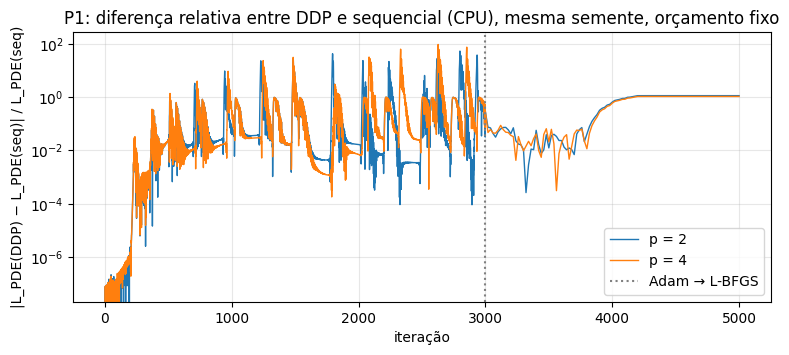


Iterações finais: p=1: [5000], p=2: [5000], p=4: [5000]

semente  E_L2 seq.      p = 2      p = 4
      0   9.69e-05   1.47e-04   1.50e-04
      1   1.47e-04   9.63e-05   8.95e-05
      2   1.09e-04   9.85e-05   8.91e-05
      3   1.14e-04   7.86e-05   9.99e-05
      4   1.47e-04   1.46e-04   1.46e-04
      5   1.09e-04   1.02e-04   9.41e-05
      6   9.61e-05   1.03e-04   1.12e-04
      7   1.29e-04   1.25e-04   1.22e-04
      8   1.58e-04   1.49e-04   1.20e-04
      9   1.49e-04   1.14e-04   1.04e-04
     10   1.39e-04   1.54e-04   1.15e-04
     11   1.01e-04   1.10e-04   9.92e-05
     12   8.78e-04   6.98e-05   6.39e-05
     13   6.39e-05   1.42e-04   6.72e-05
     14   1.36e-04   1.16e-04   1.26e-04
     15   1.31e-04   9.54e-05   1.22e-04
     16   2.09e-04   2.30e-04   1.38e-04
     17   9.94e-05   7.85e-05   9.56e-05
     18   1.30e-04   1.24e-04   1.30e-04
     19   6.36e-05   6.22e-05   6.31e-05

p = 2: razão geométrica DDP/sequencial 0.858 | IC 90% [0.675, 1.092] | TOST p = 

In [15]:
ORCAMENTO_FIXO = dict(sem_plato=True)          # 3000 Adam + 100 x 20 L-BFGS = 5000 iteracoes em todas as execucoes
MARGEM_TOST = (0.8, 1.25)                       # fixada antes do experimento
P_VERIF = (2, 4)
SEMENTES_DDP = list(range(20))                  # 0-9 reaproveitadas dos .json da execucao anterior
ALFA = 0.05                                     # por teste: ALFA / 2 com Bonferroni (dois testes)

tarefas = [dict(nome="P1", p=p, semente=s, **ORCAMENTO_FIXO) for s in SEMENTES_DDP for p in (1, *P_VERIF)]
verif = {(t["p"], t["semente"]): r for t, r in zip(tarefas, rodar_ddp_lote(tarefas))}

# (1) Perda ao longo do treino, semente 0
h_seq = verif[(1, 0)]["hist"]
pde_seq, its = np.array(h_seq["pde"]), np.array(h_seq["it"])
plt.figure(figsize=(9, 3.5))
for p in P_VERIF:
    dif = np.abs(np.array(verif[(p, 0)]["hist"]["pde"]) - pde_seq) / pde_seq
    plt.semilogy(its, dif, lw=1, label=f"p = {p}")
    print(f"p = {p}: diferença relativa de L_PDE nas 100 primeiras iterações: máx {dif[:100].max():.1e} | no fim: {dif[-1]:.1e}")
plt.axvline(h_seq["fim_adam"], color="gray", ls=":", label="Adam → L-BFGS")
plt.xlabel("iteração")
plt.ylabel("|L_PDE(DDP) − L_PDE(seq)| / L_PDE(seq)")
plt.title("P1: diferença relativa entre DDP e sequencial (CPU), mesma semente, orçamento fixo")
plt.legend()
plt.grid(True, which="both", alpha=.3)
plt.show()

# (2) Equivalencia: TOST pareado com 20 sementes
print(f"\nIterações finais: " + ", ".join(f"p={p}: {sorted({verif[(p, s)]['hist']['it_final'] for s in SEMENTES})}" for p in (1, *P_VERIF)))
print(f"\n{'semente':>7} {'E_L2 seq.':>10} " + " ".join(f"{'p = ' + str(p):>10}" for p in P_VERIF))
for s in SEMENTES_DDP:
    print(f"{s:>7} {verif[(1, s)]['metricas']['L2']:10.2e} " + " ".join(f"{verif[(p, s)]['metricas']['L2']:10.2e}" for p in P_VERIF))
l2_seq = [verif[(1, s)]["metricas"]["L2"] for s in SEMENTES_DDP]
print()
for p in P_VERIF:
    l2_p = [verif[(p, s)]["metricas"]["L2"] for s in SEMENTES_DDP]
    razao, (ic_lo, ic_hi), p_tost = tost_log(l2_p, l2_seq, margem=MARGEM_TOST)
    print(f"p = {p}: razão geométrica DDP/sequencial {razao:.3f} | IC 90% [{ic_lo:.3f}, {ic_hi:.3f}] | "
          f"TOST p = {p_tost:.2g} -> " + ("equivalência demonstrada (Bonferroni, 2 testes)" if p_tost < ALFA / len(P_VERIF)
                                             else "compatível com equivalência, sem correção" if p_tost < ALFA
                                             else "equivalência NÃO demonstrada"))
print("Fator de dispersão entre sementes: sequencial {:.2f} | ".format(resumo_log(l2_seq)[1]) +
      " | ".join(f"p={p} {resumo_log([verif[(p, s)]['metricas']['L2'] for s in SEMENTES_DDP])[1]:.2f}" for p in P_VERIF))


### Tempo por iteração e Amdahl com vários $p$ e $N_f$

Cada execução roda **sozinha** na máquina, com orçamento curto e fixo: 500 épocas de Adam + 10 passos de L-BFGS = 700 iterações, sem avaliação intermediária (a avaliação não entra no relógio, mas ocuparia a máquina).

- $p \in \{1, 2, 3, 4, 6\}$: até o número de núcleos físicos. Com *hyper-threading*, $p > 6$ disputaria núcleo.
- **Afinidade fixa:** o rank $r$ fica preso ao processador lógico $2r$, um processo por núcleo físico.
- **Controle do turbo:** com um núcleo só ativo, o processador sobe para até 3,2 GHz; com todos ativos, fica mais baixo. Isso penaliza o speedup independentemente de $N_f$. Para medir o efeito, a referência $p = 1$ é medida duas vezes: sozinha e com os outros 5 núcleos físicos ocupados por laços vazios (que não usam memória). Com a referência carregada, sobra no speedup o que é do DDP (comunicação, banda de memória), e não do relógio.
- $N_f \in \{2400, 4800, 9600\}$, com $N_b = 480$: divisíveis por todos os $p$. São valores só da medição de tempo; os treinos de acurácia usam $N_f = 2000$.
- O speedup é **por iteração**, $S(p) = t_1/t_p$, com $t_p$ o tempo por iteração com $p$ processos e o mesmo $N_f$. A referência $p = 1$ é o treino sequencial sem DDP.
- A fração paralelizável $f$ da Eq. 17 do TCC, $S(p) = 1/\big((1-f) + f/p\big)$, é ajustada por mínimos quadrados em $1 - 1/S(p) = f\,(1 - 1/p)$, que é linear em $f$.

   N_f   p  ms/iteração   S(p)  eficiência  S(p), ref. com carga
  2400   1         60.3   1.00        1.00                  1.13
  2400   2         38.8   1.55        0.78                  1.75
  2400   3         34.5   1.75        0.58                  1.97
  2400   4         34.8   1.74        0.43                  1.96
  2400   6         36.3   1.66        0.28                  1.87
       p = 1 com os outros núcleos ocupados: 68.0 ms/iteração (1.13 vez o tempo sozinho)
       Amdahl (Eq. 17),   ref. sozinha: f = 0.571 | fração serial 1 - f = 0.429 | S(p -> infinito) = 2.3
       Amdahl (Eq. 17), ref. com carga: f = 0.665 | fração serial 1 - f = 0.335 | S(p -> infinito) = 3.0

  4800   1        111.5   1.00        1.00                  1.14
  4800   2         74.3   1.50        0.75                  1.72
  4800   3         61.9   1.80        0.60                  2.06
  4800   4         60.5   1.84        0.46                  2.11
  4800   6         61.0   1.83        0.30        

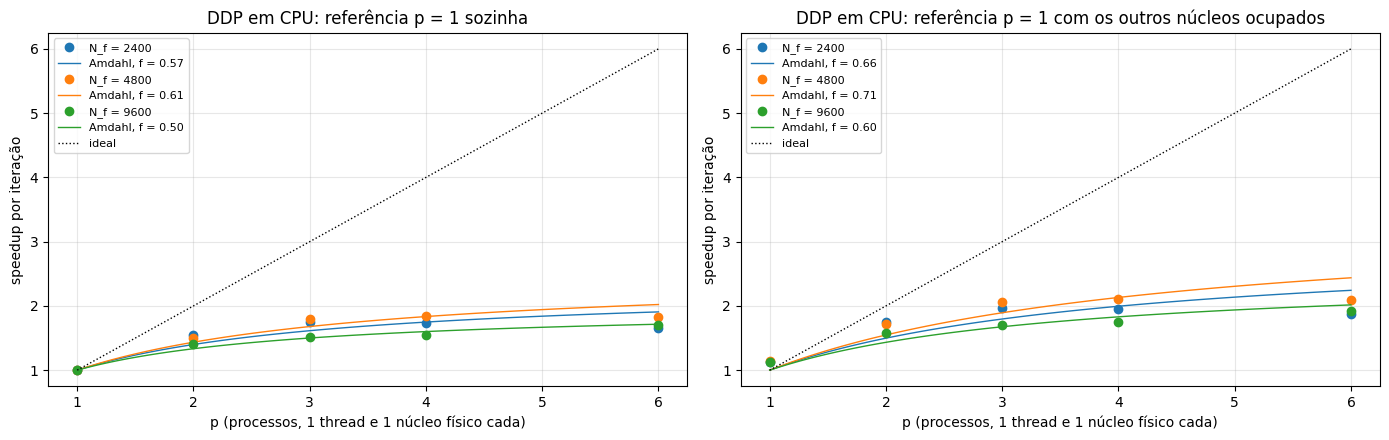

In [16]:
P_TEMPO = [1, 2, 3, 4, 6]
NF_TEMPO = [2400, 4800, 9600]
CURTO = dict(N_b=480, epocas_adam=500, passos_lbfgs=10, sem_plato=True, sem_avaliacao=True)
MEDICAO = dict(afinidade=True, rotulo="_afin")           # um processo por nucleo fisico


def iniciar_carga(cpus):
    # Processos que so giram num laco vazio, cada um preso a um processador logico: os nucleos ficam ativos
    # (frequencia de turbo com todos os nucleos ocupados), sem disputar memoria.
    procs = []
    for c in cpus:
        pr = subprocess.Popen([sys.executable, "-c", "while True: pass"])
        psutil.Process(pr.pid).cpu_affinity([c])
        procs.append(pr)
    time.sleep(2)
    return procs


def parar_carga(procs):
    for pr in procs:
        pr.kill()
        pr.wait()


t_iter, t_iter_carga = {}, {}
for N_f in NF_TEMPO:
    for p in P_TEMPO:
        r = rodar_ddp("P1", p=p, semente=0, N_f=N_f, **CURTO, **MEDICAO)
        t_iter[(N_f, p)] = r["tempo"] / r["hist"]["it_final"]
    # Referencia p = 1 (nucleo 0) com os outros 5 nucleos fisicos ocupados
    carga = iniciar_carga([cpu_do_rank(k)[0] for k in range(1, 6)])
    try:
        r = rodar_ddp("P1", p=1, semente=0, N_f=N_f, **CURTO, afinidade=True, rotulo="_afin_carga")
    finally:
        parar_carga(carga)
    t_iter_carga[N_f] = r["tempo"] / r["hist"]["it_final"]


def ajustar_amdahl(S):
    # Minimos quadrados em 1 - 1/S(p) = f (1 - 1/p), sem p = 1
    x = np.array([1 - 1 / p for p in P_TEMPO[1:]])
    y = np.array([1 - 1 / S[p] for p in P_TEMPO[1:]])
    return float(x @ y / (x @ x))


f_amdahl, f_amdahl_carga = {}, {}
print(f"{'N_f':>6} {'p':>3} {'ms/iteração':>12} {'S(p)':>6} {'eficiência':>11} {'S(p), ref. com carga':>21}")
for N_f in NF_TEMPO:
    S = {p: t_iter[(N_f, 1)] / t_iter[(N_f, p)] for p in P_TEMPO}
    S_c = {p: t_iter_carga[N_f] / t_iter[(N_f, p)] for p in P_TEMPO}
    for p in P_TEMPO:
        print(f"{N_f:>6} {p:>3} {1000 * t_iter[(N_f, p)]:12.1f} {S[p]:6.2f} {S[p] / p:11.2f} {S_c[p]:21.2f}")
    f_amdahl[N_f], f_amdahl_carga[N_f] = ajustar_amdahl(S), ajustar_amdahl(S_c)
    print(f"{'':>6} p = 1 com os outros núcleos ocupados: {1000 * t_iter_carga[N_f]:.1f} ms/iteração "
          f"({t_iter_carga[N_f] / t_iter[(N_f, 1)]:.2f} vez o tempo sozinho)")
    for rot, f in [("ref. sozinha", f_amdahl[N_f]), ("ref. com carga", f_amdahl_carga[N_f])]:
        print(f"{'':>6} Amdahl (Eq. 17), {rot:>14}: f = {f:.3f} | fração serial 1 - f = {1 - f:.3f} | "
              f"S(p -> infinito) = {1 / (1 - f) if f < 1 else float('inf'):.1f}")
    print()

pp = np.linspace(1, 6, 100)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (fs, ref, titulo) in zip(ax, [(f_amdahl, lambda N_f: t_iter[(N_f, 1)], "referência p = 1 sozinha"),
                                     (f_amdahl_carga, lambda N_f: t_iter_carga[N_f], "referência p = 1 com os outros núcleos ocupados")]):
    for N_f, cor in zip(NF_TEMPO, ["tab:blue", "tab:orange", "tab:green"]):
        a.plot(P_TEMPO, [ref(N_f) / t_iter[(N_f, p)] for p in P_TEMPO], "o", color=cor, label=f"N_f = {N_f}")
        a.plot(pp, 1 / ((1 - fs[N_f]) + fs[N_f] / pp), "-", color=cor, lw=1, label=f"Amdahl, f = {fs[N_f]:.2f}")
    a.plot(pp, pp, "k:", lw=1, label="ideal")
    a.set_xlabel("p (processos, 1 thread e 1 núcleo físico cada)")
    a.set_ylabel("speedup por iteração")
    a.set_title(f"DDP em CPU: {titulo}")
    a.legend(fontsize=8)
    a.grid(True, alpha=.3)
plt.tight_layout()
plt.show()


**Como ler:**

**Verificação com orçamento fixo** (5000 iterações, sem platô, 20 sementes; 0 a 9 reaproveitadas da execução completa, 10 a 19 novas):
- **No início, DDP e sequencial coincidem** até ~$2 \times 10^{-7}$ nas primeiras 100 iterações, o arredondamento de `float32`. Partição, all-reduce, $\lambda_{PDE}$ global e L-BFGS sincronizado estão corretos.
- **No fim, as trajetórias já se separaram** (diferença relativa de $\mathcal{L}_{PDE}$ ~100%). O arredondamento cresce ao longo de milhares de passos. Por isso a pergunta certa é estatística, e não "as perdas são iguais?".
- **Todas as execuções pararam em 5000 iterações.**
- **TOST com a margem $[0{,}8;\ 1{,}25]$ fixada antes e Bonferroni ($p < 0{,}025$ em cada teste): equivalência não demonstrada em nenhum dos dois.**
  - $p = 2$: razão geométrica DDP/sequencial 0,86, IC 90% $[0{,}68;\ 1{,}09]$, $p = 0{,}31$.
  - $p = 4$: razão 0,80, IC 90% $[0{,}63;\ 1{,}01]$, $p = 0{,}50$.
  - Com 10 sementes, a execução completa tinha dado $p = 0{,}049$ para $p = 2$, no limite. Com 20 sementes isso não se manteve: a média se afastou de 1 **para baixo**.
- **O DDP não piora a acurácia.** Nos dois casos o IC passa da margem só pelo lado de baixo, e o extremo superior (1,09 e 1,01) fica abaixo de 1,25. Isso é **não inferioridade** com a mesma margem. É uma leitura feita depois de ver os dados; o protocolo fixado antes era o de equivalência, e ele falhou.
- **A conclusão depende de uma única semente.** Na semente 12, o **sequencial** erra $8{,}8 \times 10^{-4}$, ~7 vezes as demais; por isso o fator de dispersão do sequencial (1,70) é maior que o do DDP (1,36 e 1,29). Recalculando a partir da tabela acima (razão DDP/sequencial, IC 90%):

| | 20 sementes (protocolo) | sem a semente 12 | Hodges–Lehmann | média aparada 10% |
|---|---|---|---|---|
| $p = 2$ | 0,86 $[0{,}67;\ 1{,}09]$ | 0,97 $[0{,}87;\ 1{,}09]$ | 0,93 | 0,92 |
| $p = 4$ | 0,80 $[0{,}63;\ 1{,}01]$ | 0,91 $[0{,}84;\ 0{,}99]$ | 0,90 | 0,89 |

  - **Tirar a semente 12 depois de ver os dados não é válido**, e o resultado oficial continua sendo o do protocolo. As outras colunas só mostram o quanto ele depende de um valor extremo.
  - **Para a grade final:** fixar antes um estimador robusto (TOST pelo Hodges–Lehmann ou pela média aparada) e reportar a sensibilidade a valores extremos.
  - Mesmo sem a semente 12, o DDP $p = 4$ fica ~9% **melhor**, com IC que exclui 1. O DDP é pior que o sequencial em 6 de 20 sementes com $p = 2$ e em 3 de 20 com $p = 4$.
- **Uma hipótese testável para o DDP ficar melhor: a ordem das somas.** No DDP, cada processo soma ~$N_f/p$ termos e o all-reduce soma os parciais. Somar em pedaços acumula menos erro de arredondamento em `float32`, e isso pode dar ao L-BFGS uma busca de linha mais precisa. O teste é rodar o sequencial em `float64` (ou com soma em blocos), com as mesmas sementes. Se ele alcançar o DDP, o efeito é **numérico**, e não do paralelismo. Ressalva: o PyTorch já soma em cascata na CPU, então o efeito pode ser pequeno; só o experimento decide. **Rodado no fim da seção 13** (teste da ordem das somas): o `float64` melhora o sequencial (~18% pelo Hodges–Lehmann, 17 de 20 sementes) e **desfaz o valor extremo da semente 12** ($8{,}8 \times 10^{-4} \to 7{,}2 \times 10^{-5}$). Contra o sequencial em `float64`, o DDP fica 10 a 18% **pior**. O DDP $p = 4$ fica **entre** os dois sequenciais, de forma robusta à semente 12 (Wilcoxon contra o `float32`: $p = 0{,}009$). Isso é compatível com as somas em pedaços tirando parte do erro de arredondamento, mas o teste não isola esse mecanismo.

**Tempo e Amdahl** (cada execução sozinha na máquina, afinidade fixa, 500 Adam + 10 L-BFGS, 1 thread por processo):
- **Speedup por iteração:** $S(2) = 1{,}40$ a $1{,}55$; $S(4) = 1{,}54$ a $1{,}84$; $S(6) = 1{,}66$ a $1{,}83$. A eficiência cai para ~0,3 com 6 processos. Com $N_f = 2400$, $p = 6$ é mais lento que $p = 3$ e $p = 4$.
- **A afinidade mudou pouco.** Sem ela, na execução completa: $S(2) = 1{,}4$ a $1{,}55$ e $S(4) = 1{,}6$ a $1{,}85$.
- **Turbo:** a referência $p = 1$ fica **13 a 14% mais lenta** com os outros 5 núcleos ocupados (60,3 → 68,0 ms com $N_f = 2400$). É o tamanho do efeito do turbo nesta máquina.
- **Amdahl (Eq. 17 do TCC, $f$ = fração paralelizável), ajustado em todos os $p$:**

| $N_f$ | $f$, ref. sozinha | $S_\infty$ | $f$, ref. com carga | $S_\infty$ |
|---|---|---|---|---|
| 2400 | 0,57 | 2,3 | 0,67 | 3,0 |
| 4800 | 0,61 | 2,5 | 0,71 | 3,4 |
| 9600 | 0,50 | 2,0 | 0,61 | 2,5 |

- **O turbo responde por ~0,1 de $f$.** Com a referência carregada, o que sobra da fração serial (0,3 a 0,4) é do DDP: comunicação, sincronização e disputa por memória.
- **$f$ não cresce com $N_f$** (é o menor em 9600), ao contrário do que se espera se a parte serial fosse só a comunicação, que não depende de $N_f$. Uma explicação possível, não testada aqui, é a disputa pela banda de memória entre os processos no mesmo processador. Neste hardware, o $f$ ajustado mede o DDP em CPU **como um todo**, e não só a fração serial do algoritmo.


---
## 11. XPINN

### A ideia

O quadrado é dividido em $M \times M$ subdomínios iguais, de lado $1/M$. Cada subdomínio tem **sua própria sub-rede**. A solução final é "cada ponto usa a sub-rede do seu subdomínio".

Enquanto o DDP só divide o **trabalho**, o XPINN muda a **parametrização**: cada sub-rede só precisa representar a solução num pedaço menor. A H2 pergunta se isso facilita aprender o modo alto de P2.

### Coordenadas locais (§12.2)

Cada sub-rede recebe a posição **renormalizada para $[-1, 1]^2$**:

$$
\xi = 2M\,(x - x_{\text{canto}}) - 1, \qquad \eta = 2M\,(y - y_{\text{canto}}) - 1
$$

Assim, o modo $\sin(n\pi x)$ visto por dentro de uma sub-rede tem frequência local proporcional a $n/M$. A conta de $\xi$ fica **dentro** da rede, então o autograd já inclui o fator $(2M)^2$ quando calcula $\nabla^2$ em relação a $x$ e $y$ globais.

### Contorno no XPINN

**Padrão: contorno fraco**, o mesmo da monolítica. Os $N_b$ pontos de contorno são separados por subdomínio, e só as sub-redes que tocam a borda os veem. $\mathcal{L}_{BC}$ é a média sobre os $N_b$ pontos **globais**, como na monolítica.

O $D$ produto também está implementado (`contorno="exato"`: $u = D\,\mathrm{NN}_k + G$, com $D$ e $G$ globais), só para reexaminar o caso da versão anterior (seção 11). A transfinita **não** se aplica ao XPINN: ela avalia a rede nas linhas da borda a partir de qualquer ponto, e isso acoplaria sub-redes não vizinhas.

### A perda

$$
\mathcal{L}_{\text{XPINN}} = \lambda_{PDE}\,\mathcal{L}_{PDE} + \lambda_{BC}\,\mathcal{L}_{BC} + \lambda_I\,\mathcal{L}_{I}
$$

- $\mathcal{L}_{PDE}$: **os mesmos pontos** da monolítica, só separados por subdomínio, com a soma dividida pelo $N_f$ **global**. É idêntica à da monolítica.
- $\mathcal{L}_I$: só existe no XPINN. Em cada interface, as duas sub-redes vizinhas são avaliadas nos mesmos $N_I = 50$ pontos por segmento:

$$
\mathcal{L}_I = \underbrace{\overline{(u_a - u_b)^2}}_{\text{continuidade de } u}
+ \lambda_{PDE}\,\underbrace{\overline{(\nabla^2 u_a - \nabla^2 u_b)^2}}_{\text{continuidade do resíduo}}
+ \underbrace{\overline{(\partial_n u_a - \partial_n u_b)^2}}_{\text{continuidade do fluxo}}
$$

**Convenção de escala (fixada e declarada):** o salto do resíduo é normalizado como a $\mathcal{L}_{PDE}$ (por $\overline{f^2}$); os saltos de $u$ e de $\partial_n u$ ficam em unidades naturais, porque as soluções têm amplitude de ordem 1 (o P0 foi reescalado para amplitude 1, seção 1). Com isso, o peso da interface em relação à EDP **não depende de $n$**. Uma alternativa testada, medir os três saltos na escala do Laplaciano do modo fundamental, faz o peso da interface cair com $n^4$ e desacopla os subdomínios em P2(11) ($E_1 \approx 1$). Por isso foi descartada.

$\lambda_I = 1$ nas seções 11 e 12. Na seção 13, $\lambda_I$ é **escolhido com sementes** antes da grade e das comparações pareadas (§12.4 do documento).

As duas primeiras parcelas de $\mathcal{L}_I$ são as da eq. 15 do TCC. A terceira **não está na eq. 15**, embora o texto do TCC (§2.5.4) fale em continuidade $C^1$ e em troca de "flux information". O experimento abaixo mostra por que ela é necessária.

### Controle de capacidade (§12.4)

| Modo | Largura de cada sub-rede | Parâmetros totais |
|---|---|---|
| **iso-parâmetro** | maior largura com $M^2 \cdot P(w) \le P(64)$ | $\approx$ igual à monolítica |
| **iso-largura** | 64, a mesma da monolítica | $M^2 \times$ a monolítica |

Profundidade fixa em 4 camadas ocultas nos dois modos.

### Execução sequencial e o que muda ao distribuir

Aqui todas as sub-redes treinam **num processo só**: os pesos ficam empilhados em tensores `(M², entrada, saída)` e são calculados juntos com `torch.bmm`.

Num XPINN distribuído, cada processo guarda uma (ou algumas) sub-redes e troca valores de interface com os vizinhos. Ele reproduz **exatamente** este treino se três condições valerem:

1. **Troca síncrona a cada iteração** dos valores de interface ($u$, $\nabla^2 u$, $\partial_n u$) do vizinho.
2. **Médias normalizadas pelo total global**: a soma do resíduo de cada subdomínio dividida por $N_f$ global, não pelo número local de pontos (que varia de subdomínio para subdomínio).
3. **Otimizador que atua por parâmetro.** Com 1 e 2, o gradiente que cada processo calcula para os seus pesos, com os valores do vizinho recebidos e congelados, é a derivada parcial exata da perda global. O **Adam** é elemento a elemento, então serve. O **L-BFGS não**: ele usa produtos internos sobre o vetor inteiro de parâmetros e uma busca de linha sobre a perda global. Um L-BFGS independente por processo é **outro algoritmo**. Manter a equivalência exige calcular esses produtos internos e a perda da busca de linha com all-reduce.

A implementação distribuída do fim desta seção satisfaz as três condições de outro jeito, mais simples: os parâmetros ficam replicados e a sincronização é a soma dos gradientes.

### Saltos nas interfaces, medidos na avaliação (RQ2)

A perda de interface só olha os $N_I$ pontos de treino. Na avaliação, medimos os saltos em 200 pontos por segmento, relativos à escala da solução exata nos mesmos pontos:

$$
\mathcal{J}_u = \frac{\mathrm{RMS}(u_a - u_b)}{\mathrm{RMS}(u^*)}, \qquad
\mathcal{J}_n = \frac{\mathrm{RMS}(\partial_n u_a - \partial_n u_b)}{\mathrm{RMS}(|\nabla u^*|)}
$$

In [30]:
def n_parametros(largura, camadas_ocultas=4):
    # entrada 2 -> largura, (camadas_ocultas - 1) camadas largura -> largura, largura -> 1
    return (2 * largura + largura) + (camadas_ocultas - 1) * (largura**2 + largura) + (largura + 1)


def largura_iso_parametro(M, largura_mono=64, camadas_ocultas=4):
    # Maior largura tal que M^2 sub-redes somem no maximo os parametros da rede monolitica
    alvo = n_parametros(largura_mono, camadas_ocultas) / M**2
    w = 1
    while n_parametros(w + 1, camadas_ocultas) <= alvo:
        w += 1
    return w


class XPINN(torch.nn.Module):
    # M x M sub-redes, uma por subdominio. Os pesos ficam empilhados em tensores (S, entrada, saida)
    # para calcular varias sub-redes de uma vez com torch.bmm.
    # Com G definido, o contorno e exato: u = D(x, y) * NN_k(x, y) + G(x, y), com D e G GLOBAIS.
    def __init__(self, M, largura, camadas_ocultas=4, G=None):
        super().__init__()
        self.M, self.S, self.G = M, M * M, G
        tamanhos = [2] + [largura] * camadas_ocultas + [1]
        self.W = torch.nn.ParameterList()
        self.b = torch.nn.ParameterList()
        for a, c in zip(tamanhos[:-1], tamanhos[1:]):
            desvio = math.sqrt(2.0 / (a + c))                      # Glorot/Xavier normal, igual a monolitica
            self.W.append(torch.nn.Parameter(torch.randn(self.S, a, c) * desvio))
            self.b.append(torch.nn.Parameter(torch.zeros(self.S, 1, c)))
        # Canto inferior esquerdo de cada subdominio k = i*M + j  (i: coluna em x, j: linha em y)
        i, j = torch.meshgrid(torch.arange(M), torch.arange(M), indexing="ij")
        self.register_buffer("canto", torch.stack([i.ravel(), j.ravel()], 1).float().unsqueeze(1) / M)

    def subdominio(self, xy):
        # Indice do subdominio de cada ponto (pontos exatamente na interface vao para o de cima/direita)
        i = torch.clamp((xy[:, 0] * self.M).floor().long(), 0, self.M - 1)
        j = torch.clamp((xy[:, 1] * self.M).floor().long(), 0, self.M - 1)
        return i * self.M + j

    def sub_redes(self, xy, ks):
        # xy: (B, P, 2) em coordenadas GLOBAIS; ks: (B,) qual sub-rede avalia cada lote
        # Renormalizacao para coordenadas locais [-1, 1]^2 (secao 12.2 do documento)
        h = 2 * self.M * (xy - self.canto[ks]) - 1
        for camada in range(len(self.W)):
            h = torch.bmm(h, self.W[camada][ks]) + self.b[camada][ks]
            if camada < len(self.W) - 1:
                h = torch.tanh(h)
        if self.G is not None:
            x, y = xy[..., 0:1], xy[..., 1:2]
            h = distancia_contorno(x, y) * h + self.G(x, y)
        return h                                                    # (B, P, 1)

    def forward(self, xy):
        # Avaliacao em pontos quaisquer (N, 2): cada ponto e calculado so pela sub-rede do seu subdominio
        k = self.subdominio(xy)
        partes, ordem = [], []
        for s in range(self.S):
            idx = torch.nonzero(k == s).squeeze(1)
            if len(idx) > 0:
                partes.append(self.sub_redes(xy[idx].unsqueeze(0), torch.tensor([s]))[0])
                ordem.append(idx)
        ordem = torch.cat(ordem)
        inversa = torch.empty_like(ordem)
        inversa[ordem] = torch.arange(len(ordem))
        return torch.cat(partes)[inversa]


def agrupar_por_subdominio(xy, k, S):
    # Separa os pontos por subdominio num tensor (S, P_max, 2) com mascara (os lotes tem tamanhos diferentes)
    contagem = torch.bincount(k, minlength=S)
    P = int(contagem.max())
    lote = torch.zeros(S, P, 2)
    mascara = torch.zeros(S, P, 1)
    for s in range(S):
        pts = xy[k == s]
        lote[s, :len(pts)] = pts
        lote[s, len(pts):] = pts[0] if len(pts) > 0 else 0.5    # preenchimento (ignorado pela mascara)
        mascara[s, :len(pts)] = 1.0
    return lote, mascara


def pontos_interface(M, N_I):
    # N_I pontos em cada segmento de interface. Devolve pontos (nseg, N_I, 2), o par de sub-redes (a, b)
    # e a direcao normal ao segmento (0 = x, 1 = y)
    t = (torch.arange(N_I) + 0.5) / N_I
    pts, ka, kb, normal = [], [], [], []
    for i in range(1, M):                     # interfaces verticais x = i/M
        for j in range(M):
            y = (j + t) / M
            pts.append(torch.stack([torch.full_like(y, i / M), y], 1))
            ka.append((i - 1) * M + j)
            kb.append(i * M + j)
            normal.append(0)                  # normal na direcao x
    for j in range(1, M):                     # interfaces horizontais y = j/M
        for i in range(M):
            x = (i + t) / M
            pts.append(torch.stack([x, torch.full_like(x, j / M)], 1))
            ka.append(i * M + (j - 1))
            kb.append(i * M + j)
            normal.append(1)                  # normal na direcao y
    if not pts:                               # M = 1: sem interfaces
        vazio = torch.zeros(0, dtype=torch.long)
        return torch.zeros(0, N_I, 2), vazio, vazio, vazio
    return torch.stack(pts), torch.tensor(ka), torch.tensor(kb), torch.tensor(normal)


def treinar_xpinn(prob, M, largura=None, contorno="fraco", epocas_adam=3000, passos_lbfgs_max=100, iter_por_passo=20,
                  tolerancia_plato=0.01, janela_plato=10, N_f=2000, N_b=400, N_I=50, lr=1e-3, camadas_ocultas=4,
                  semente=SEMENTE, lam_pde="auto", lam_bc=1.0, lam_i=1.0, fluxo=True, avaliar_a_cada=100, imprimir=True,
                  distribuido=False):
    # distribuido=True: parametros replicados em todos os processos; cada processo calcula a EDP e o contorno dos
    # SEUS subdominios e uma parte dos segmentos de interface, normalizados pelos totais GLOBAIS. A soma dos
    # gradientes entre processos (all-reduce) e o gradiente da perda global: Adam e L-BFGS ficam identicos.
    torch.manual_seed(semente)
    if largura is None:
        largura = largura_iso_parametro(M, camadas_ocultas=camadas_ocultas)
    rede = XPINN(M, largura, camadas_ocultas, G=prob["G"] if contorno == "exato" else None)
    S = rede.S
    rank, p = (dist.get_rank(), dist.get_world_size()) if distribuido else (0, 1)
    assert S % p == 0, "o numero de subdominios M^2 precisa ser multiplo do numero de processos"
    meus = torch.arange(rank * S // p, (rank + 1) * S // p)        # subdominios deste processo

    # MESMOS pontos globais da monolitica, apenas separados por subdominio
    xy_f = pontos_colocacao(N_f, semente)
    f_global = prob["f"](xy_f[:, 0:1], xy_f[:, 1:2])
    if lam_pde == "auto":
        escala = torch.mean(f_global**2).item()
        lam_pde = 1.0 / escala if escala > 0 else 1.0

    lote_f, masc_f = agrupar_por_subdominio(xy_f, rede.subdominio(xy_f), S)
    n_f_total = masc_f.sum()                                       # N_f global
    lote_f, masc_f = lote_f[meus], masc_f[meus]
    xy_I, ka, kb, normal = pontos_interface(M, N_I)
    nseg_total = xy_I.shape[0]
    if distribuido:                                                # segmentos de interface: um a cada p
        seg = torch.arange(rank, nseg_total, p)
        xy_I, ka, kb, normal = xy_I[seg], ka[seg], kb[seg], normal[seg]
    # Direcao normal de cada ponto como mascara one-hot: (grad * sel).sum(1) = derivada normal.
    # (Equivale a gather, mas o backward do gather usa scatter_add, que nao e deterministico na GPU.)
    sel_normal = torch.nn.functional.one_hot(normal.repeat_interleave(N_I), 2).to(torch.float32)
    ks = meus

    # Folhas "achatadas" para usar o MESMO laplaciano(u, xy) da monolitica
    xy_f_flat = lote_f.reshape(-1, 2).clone().requires_grad_(True)
    f_flat = prob["f"](xy_f_flat[:, 0:1], xy_f_flat[:, 1:2]).detach()
    xy_I_flat = xy_I.reshape(-1, 2).clone().requires_grad_(True)
    nseg = xy_I.shape[0]
    # Media sobre os pontos de interface GLOBAIS (no sequencial, a media de sempre)
    media_I = (lambda v: v.sum() / (nseg_total * N_I)) if distribuido else torch.mean

    if contorno == "fraco":
        xy_b = pontos_contorno(N_b)
        lote_b, masc_b = agrupar_por_subdominio(xy_b, rede.subdominio(xy_b), S)
        n_b_total = masc_b.sum()
        lote_b, masc_b = lote_b[meus], masc_b[meus]
        g_b = prob["u"](lote_b[..., 0:1], lote_b[..., 1:2]).detach()

    def perdas(registro=False):
        # Interior: soma sobre os pontos reais / N_f global = mesma L_PDE da monolitica
        u_f = rede.sub_redes(xy_f_flat.view(len(meus), -1, 2), ks).reshape(-1, 1)
        residuo = (-laplaciano(u_f, xy_f_flat) - f_flat) * masc_f.reshape(-1, 1)
        loss_pde = (residuo**2).sum() / n_f_total

        if contorno == "fraco":
            u_b = rede.sub_redes(lote_b, ks)
            loss_bc = (((u_b - g_b) * masc_b)**2).sum() / n_b_total
        else:
            loss_bc = torch.zeros(())

        # Interface: os dois lados avaliados nos mesmos pontos.
        # Convencao de escala: o salto do residuo e normalizado como a L_PDE (x lam_pde);
        # os saltos de u e de du/dn ficam em unidades naturais (as solucoes tem amplitude de ordem 1).
        # Assim o peso da interface em relacao a EDP nao depende de n.
        loss_i = torch.zeros(())
        if nseg > 0:
            xy_I_view = xy_I_flat.view(nseg, N_I, 2)
            u_a = rede.sub_redes(xy_I_view, ka).reshape(-1, 1)
            u_c = rede.sub_redes(xy_I_view, kb).reshape(-1, 1)
            salto_u = media_I((u_a - u_c)**2)
            salto_res = media_I((laplaciano(u_a, xy_I_flat) - laplaciano(u_c, xy_I_flat))**2)  # f se cancela
            loss_i = salto_u + lam_pde * salto_res
            if fluxo:
                grad_a = torch.autograd.grad(u_a, xy_I_flat, torch.ones_like(u_a), create_graph=True)[0]
                grad_c = torch.autograd.grad(u_c, xy_I_flat, torch.ones_like(u_c), create_graph=True)[0]
                salto_fluxo = media_I((((grad_a - grad_c) * sel_normal).sum(1))**2)
                loss_i = loss_i + salto_fluxo

        loss = lam_pde * loss_pde + lam_i * loss_i + lam_bc * loss_bc
        return loss, loss_pde, loss_bc, loss_i

    hist = {"it": [], "loss": [], "pde": [], "bc": [], "int": [], "aval_it": [], "aval_tempo": [], "L2": [], "E_n": [],
            "E_1": [], "fim_adam": epocas_adam, "lam_pde": lam_pde, "lam_bc": lam_bc, "lam_i": lam_i, "largura": largura,
            "fluxo": fluxo, "contorno": contorno, "parametros": sum(p.numel() for p in rede.parameters())}
    relogio = [0.0]

    def registrar(it, valores, forcar=False):
        hist["it"].append(it)
        hist["loss"].append(valores[0])
        hist["pde"].append(valores[1])
        hist["bc"].append(valores[2])
        hist["int"].append(valores[3])
        if forcar:
            m = avaliar(rede, prob)
            hist["aval_it"].append(it)
            hist["aval_tempo"].append(relogio[0])
            hist["L2"].append(m["L2"])
            if "n" in prob:
                hist["E_n"].append(m["E_n"])
                hist["E_1"].append(m["E_1"])
            return m

    def mostrar(fase, it, valores, m):
        if imprimir and m is not None:
            extra = f" | E_n {m['E_n']:.3f}" if "n" in prob else ""
            print(f"[{prob['nome']} XPINN M={M}] {fase} it {it:5d} | loss {valores[0]:.2e} | PDE {valores[1]:.2e} | INT {valores[3]:.2e} | L2 {m['L2']:.2e}{extra}")

    def soma_global(valor):
        # Cada processo tem uma parte da perda global: o valor global e a SOMA entre processos
        if not distribuido:
            return valor
        v = valor.detach().clone()
        dist.all_reduce(v)
        return v

    def somar_gradientes():
        # Um all-reduce so, com todos os gradientes num vetor (como os "buckets" do DDP): menos latencia que um por tensor
        if distribuido:
            grads = [prm.grad for prm in rede.parameters()]
            plano = torch.cat([g.reshape(-1) for g in grads])
            dist.all_reduce(plano)
            for g, parte in zip(grads, torch.split(plano, [g.numel() for g in grads])):
                g.copy_(parte.view_as(g))

    it_final, passos = otimizar(list(rede.parameters()), perdas, registrar, mostrar, relogio, soma_global,
                                epocas_adam, passos_lbfgs_max, iter_por_passo, lr, tolerancia_plato, janela_plato,
                                avaliar_a_cada, somar_gradientes)
    hist["it_final"], hist["passos_lbfgs"] = it_final, passos
    hist["platô"] = passos < passos_lbfgs_max
    return rede, hist, relogio[0]


def saltos_interface(xpinn, prob, N_I=200):
    # Saltos de u e de du/dn nas interfaces, medidos na avaliacao (nao na perda).
    # Normalizados pelo valor RMS de u* e de |grad u*| nos mesmos pontos.
    xy_I, ka, kb, normal = pontos_interface(xpinn.M, N_I)
    nseg = xy_I.shape[0]
    xy = xy_I.reshape(-1, 2).clone().requires_grad_(True)
    vista = xy.view(nseg, N_I, 2)
    u_a = xpinn.sub_redes(vista, ka).reshape(-1, 1)
    u_b = xpinn.sub_redes(vista, kb).reshape(-1, 1)
    g_a = torch.autograd.grad(u_a, xy, torch.ones_like(u_a), retain_graph=True)[0]
    g_b = torch.autograd.grad(u_b, xy, torch.ones_like(u_b))[0]
    n_pt = normal.repeat_interleave(N_I).unsqueeze(1)
    u_ex = prob["u"](xy[:, 0:1], xy[:, 1:2])
    g_ex = torch.autograd.grad(u_ex, xy, torch.ones_like(u_ex))[0]
    rms = lambda v: torch.sqrt(torch.mean(v**2)).item()
    salto_u = rms(u_a - u_b) / rms(u_ex)
    salto_fluxo = rms(g_a.gather(1, n_pt) - g_b.gather(1, n_pt)) / rms(g_ex.norm(dim=1))
    return salto_u, salto_fluxo

def residuo_por_subdominio(modelo, prob, M, Ng=128):
    # Residuo r = -lap(u) - f numa grade de centros de celula Ng x Ng (nenhum ponto cai numa interface).
    # Para cada subdominio k de uma particao M x M: L_PDE_k = media de r^2 e I_k = integral de r em Omega_k,
    # relativa a int |du*/dn| na borda (a mesma escala do E_bal).
    # Teorema da divergencia: soma_k I_k = [-oint du/dn - int f - (saltos de du/dn nas interfaces)] / escala,
    # entao E_bal grande com saltos pequenos exige |soma_k I_k| grande.
    c = (torch.arange(Ng) + 0.5) / Ng
    X, Y = torch.meshgrid(c, c, indexing="ij")
    xy = torch.stack([X.ravel(), Y.ravel()], 1).requires_grad_(True)
    u = modelo(xy)
    r = (-laplaciano(u, xy) - prob["f"](xy[:, 0:1], xy[:, 1:2])).detach().ravel()
    k = (torch.clamp((xy[:, 0] * M).floor().long(), 0, M - 1) * M
         + torch.clamp((xy[:, 1] * M).floor().long(), 0, M - 1)).detach()

    # Escala: int |du*/dn| na borda (Gauss-Legendre, como em balanco_global)
    t, w = np.polynomial.legendre.leggauss(64)
    t = torch.tensor((t + 1) / 2, dtype=torch.float32).unsqueeze(1)
    w = torch.tensor(w / 2, dtype=torch.float32).unsqueeze(1)
    z, o = torch.zeros_like(t), torch.ones_like(t)
    escala = 0.0
    for pts, comp in [(torch.cat([z, t], 1), 0), (torch.cat([o, t], 1), 0), (torch.cat([t, z], 1), 1), (torch.cat([t, o], 1), 1)]:
        pts = pts.clone().requires_grad_(True)
        ue = prob["u"](pts[:, 0:1], pts[:, 1:2])
        escala += (torch.autograd.grad(ue, pts, torch.ones_like(ue))[0][:, comp:comp + 1].abs() * w).sum().item()

    L_k = torch.zeros(M * M).index_add_(0, k, r**2) / torch.bincount(k, minlength=M * M)
    I_k = torch.zeros(M * M).index_add_(0, k, r) / Ng**2 / escala
    # Matrizes M x M com y crescendo para cima (linha 0 = faixa de cima)
    em_grade = lambda v: v.reshape(M, M).T.flip(0).cpu().numpy()
    return em_grade(L_k), em_grade(I_k)


  M  largura iso-parâmetro  parâmetros totais   (monolítica: 12737)
  2                     31              12404
  4                     15              12496


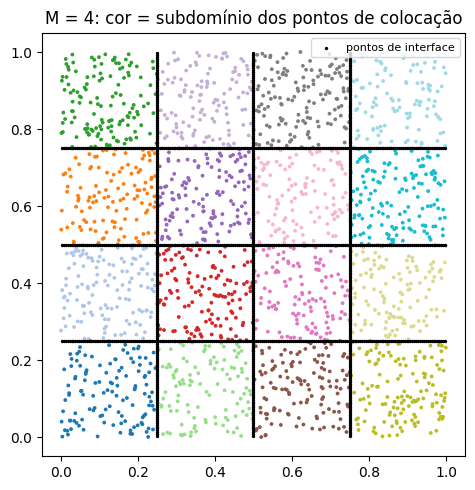

Pontos de colocação por subdomínio: [123, 127, 117, 133, 113, 136, 129, 122, 130, 121, 113, 136, 134, 116, 141, 109]


In [31]:
print(f"{'M':>3} {'largura iso-parâmetro':>22} {'parâmetros totais':>18}   (monolítica: {n_parametros(64)})")
for M in [2, 4]:
    w = largura_iso_parametro(M)
    print(f"{M:>3} {w:>22} {M**2 * n_parametros(w):>18}")

M = 4
xp = XPINN(M, largura_iso_parametro(M))
xy_f = pontos_colocacao(2000, SEMENTE)
k = xp.subdominio(xy_f).cpu()
xy_f = xy_f.cpu()
xy_I, ka, kb, normal = pontos_interface(M, 50)
xy_I = xy_I.cpu()

plt.figure(figsize=(5.5, 5.5))
plt.scatter(xy_f[:, 0], xy_f[:, 1], c=k, s=3, cmap="tab20")
plt.scatter(xy_I[..., 0].ravel(), xy_I[..., 1].ravel(), s=2, c="k", label="pontos de interface")
plt.gca().set_aspect("equal")
plt.title(f"M = {M}: cor = subdomínio dos pontos de colocação")
plt.legend(loc="upper right", fontsize=8)
plt.show()

print("Pontos de colocação por subdomínio:", torch.bincount(k).tolist())

### Reprodutibilidade: a mesma configuração duas vezes

A célula de configuração, no início do notebook, pede ao PyTorch a versão determinística de cada operação (`use_deterministic_algorithms`), mas com `warn_only=True`: uma operação sem versão determinística só emite um aviso, e o treino segue. Para não depender disso, o teste é direto: a mesma configuração roda **duas vezes**, e as saídas são comparadas **bit a bit**.

- **Monolítica e XPINN $M = 4$ na GPU**, P2(11), 500 iterações (300 Adam + 10 passos de L-BFGS): todos os parâmetros finais e a perda em todas as iterações.
- **DDP $p = 2$ em CPU**, P1, mesmo orçamento: a perda em todas as iterações e as métricas finais, em dois lançamentos independentes dos processos.
- No fim, a lista de avisos de operação sem versão determinística registrados desde o início do notebook.

In [18]:
CURTO_DET = dict(epocas_adam=300, passos_lbfgs_max=10)        # 300 Adam + 10 x 20 L-BFGS = 500 iteracoes


def parametros_identicos(a, b):
    return all(torch.equal(x, y) for x, y in zip(a.parameters(), b.parameters()))


prob = criar_problema("P2", n=11)
print(f"{'configuração':>18} {'parâmetros idênticos':>21} {'perda idêntica em todas as it.':>31} {'maior |dif.| de parâmetro':>26}")
for nome, treinar, kw in [("Monolítica (GPU)", treinar_pinn, {}), ("XPINN M=4 (GPU)", treinar_xpinn, {"M": 4})]:
    r1, h1, _ = treinar(prob, imprimir=False, **CURTO_DET, **kw)
    r2, h2, _ = treinar(prob, imprimir=False, **CURTO_DET, **kw)
    dif = max((x - y).abs().max().item() for x, y in zip(r1.parameters(), r2.parameters()))
    print(f"{nome:>18} {str(parametros_identicos(r1, r2)):>21} {str(h1['loss'] == h2['loss']):>31} {dif:26.1e}")

ddp_det = [rodar_ddp("P1", p=2, semente=0, epocas_adam=300, passos_lbfgs=10, sem_plato=True, reaproveitar=False,
                     rotulo=f"_det{k}") for k in (1, 2)]
print(f"{'DDP p=2 (CPU)':>18} {'-':>21} {str(ddp_det[0]['hist']['loss'] == ddp_det[1]['hist']['loss']):>31} "
      f"{'métricas iguais: ' + str(ddp_det[0]['metricas'] == ddp_det[1]['metricas']):>26}")

print("\nAvisos de operação sem versão determinística registrados desde o início:")
for aviso in sorted(AVISOS_DETERMINISMO) or ["nenhum"]:
    print(" -", aviso)


      configuração  parâmetros idênticos  perda idêntica em todas as it.  maior |dif.| de parâmetro


  Monolítica (GPU)                  True                            True                    0.0e+00


   XPINN M=4 (GPU)                  True                            True                    0.0e+00


     DDP p=2 (CPU)                     -                            True      métricas iguais: True

Avisos de operação sem versão determinística registrados desde o início:
 - nenhum


**Como ler:**

- **Monolítica e XPINN $M = 4$ na GPU:** parâmetros finais idênticos bit a bit (maior diferença 0) e perda idêntica em todas as iterações.
- **DDP $p = 2$ em CPU**, dois lançamentos independentes dos processos: perda idêntica em todas as iterações e métricas finais iguais.
- **Nenhum aviso** de operação sem versão determinística foi registrado desde o início do notebook. O `warn_only=True` não escondeu nada nesta execução.
- **Entre sessões:** a re-execução parcial refez a monolítica de P2(11) (sementes 0 a 5) e a monolítica da grade da seção 13, e repetiu a execução completa em todos os dígitos impressos.
- **Limites:**
  - o teste vale para esta máquina, esta versão do PyTorch e este driver; outro hardware pode dar outros bits;
  - determinismo **não** quer dizer que DDP e sequencial coincidem: a ordem das somas muda, e as trajetórias se separam (seção 10).


### Experimento: interface sem e com continuidade do fluxo

P1 com $M = 4$ e contorno fraco, treinado duas vezes: com a interface do TCC (valor + resíduo) e com o termo de fluxo.

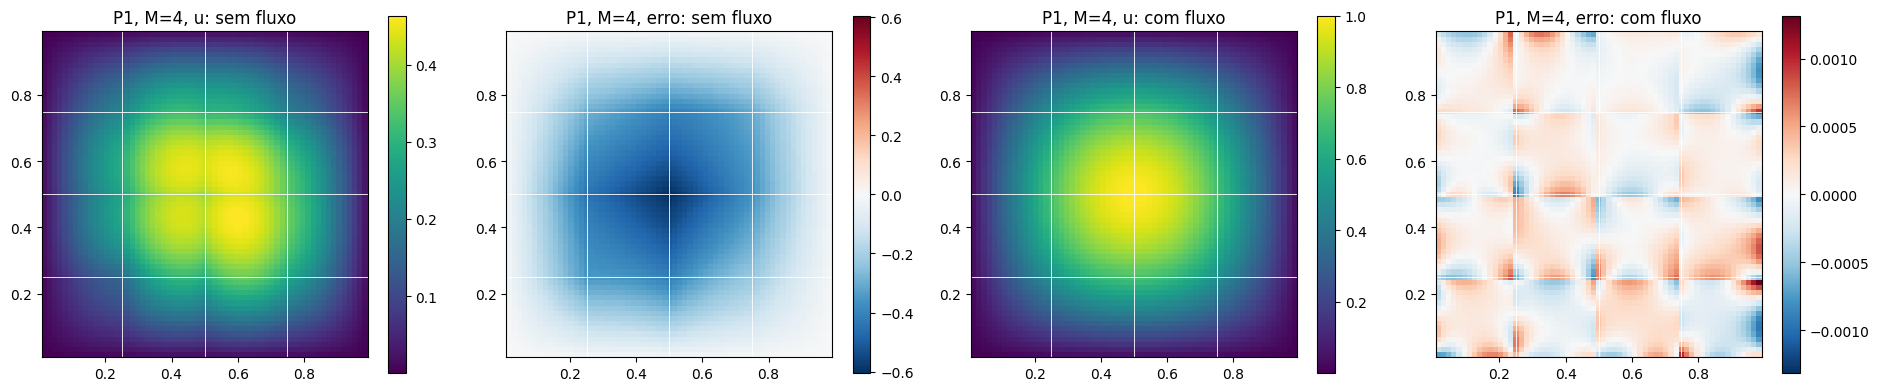

   interface      E_L2  L_PDE final  L_I final       J_u       J_n     E_bal


   sem fluxo  5.31e-01     9.98e-05   4.16e-07   7.6e-04   3.7e-01   5.0e-01
   com fluxo  4.28e-04     3.14e-04   1.87e-06   1.1e-03   3.5e-04   5.0e-05


In [32]:
prob = criar_problema("P1")
xp_sem, h_sem, t_sem = treinar_xpinn(prob, M=4, fluxo=False, imprimir=False)
xp_com, h_com, t_com = treinar_xpinn(prob, M=4, fluxo=True, imprimir=False)
m_sem, m_com = avaliar(xp_sem, prob), avaliar(xp_com, prob)

_, X, Y = grade_interior(63)
U_ex = prob["u"](X, Y).cpu().numpy()
X, Y = X.cpu(), Y.cpu()
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for a, Z, titulo, cmap in [(ax[0], m_sem["U"], "u: sem fluxo", "viridis"), (ax[1], m_sem["U"] - U_ex, "erro: sem fluxo", "RdBu_r"),
                            (ax[2], m_com["U"], "u: com fluxo", "viridis"), (ax[3], m_com["U"] - U_ex, "erro: com fluxo", "RdBu_r")]:
    lim = np.abs(Z).max() if "erro" in titulo else None
    im = a.pcolormesh(X, Y, Z, shading="auto", cmap=cmap, vmin=-lim if lim else None, vmax=lim)
    for q in range(1, 4):
        a.axvline(q / 4, color="w", lw=.6); a.axhline(q / 4, color="w", lw=.6)
    a.set_title(f"P1, M=4, {titulo}")
    a.set_aspect("equal")
    plt.colorbar(im, ax=a)
plt.tight_layout()
plt.show()

print(f"{'interface':>12} {'E_L2':>9} {'L_PDE final':>12} {'L_I final':>10} {'J_u':>9} {'J_n':>9} {'E_bal':>9}")
for nome, m, h, xp in [("sem fluxo", m_sem, h_sem, xp_sem), ("com fluxo", m_com, h_com, xp_com)]:
    J_u, J_n = saltos_interface(xp, prob)
    print(f"{nome:>12} {m['L2']:9.2e} {h['pde'][-1]:12.2e} {h['int'][-1]:10.2e} {J_u:9.1e} {J_n:9.1e} {balanco_global(xp, prob):9.1e}")

**Como ler:**

- **Sem o termo de fluxo**, $\mathcal{L}_{PDE}$ e $\mathcal{L}_I$ terminam pequenas ($10^{-4}$ e $4 \times 10^{-7}$) e mesmo assim $\mathcal{E}_{L^2} \approx 0{,}53$.
- **As métricas da RQ2 detectam a falha que a perda não vê:** o salto da derivada normal na avaliação é $\mathcal{J}_n \approx 0{,}37$ e o balanço global é $\mathcal{E}_{\text{bal}} \approx 0{,}50$. O salto de $u$ fica pequeno ($\mathcal{J}_u \sim 8 \times 10^{-4}$): a solução é contínua, mas tem "dobras".
- **Com o termo de fluxo:** $\mathcal{E}_{L^2} \approx 4 \times 10^{-4}$, $\mathcal{J}_n \approx 4 \times 10^{-4}$ e $\mathcal{E}_{\text{bal}} \approx 5 \times 10^{-5}$.
- Consequência para o TCC: a eq. 15 precisa incluir a continuidade de $\partial_n u$, coerente com a §2.5.4. E $\mathcal{J}_n$ e $\mathcal{E}_{\text{bal}}$ devem ser reportados, porque são eles que distinguem uma solução contínua e correta de uma contínua e errada.

### Experimento: a baixa frequência atravessa os subdomínios?

Na versão anterior (com $D$ produto), o XPINN perdeu o modo baixo mesmo onde o peso $n^{-4}$ não pesa: em P2(5) e em L0, que só tem baixa frequência. Esse peso é **o mesmo** na monolítica e no XPINN (a $\mathcal{L}_{PDE}$ é idêntica), então ele não explica a diferença entre os dois.

**Correção da leitura anterior.** A versão anterior descreveu P2(5) com $M = 4$ como "contínua e localmente plausível, mas com o nível global errado", como se um componente global ficasse indeterminado. **Isso é matematicamente impossível.** Com Dirichlet exato, continuidade de $u$ e de $\partial_n u$ nas interfaces e resíduo pequeno, a solução é **única**: $u_\theta$ resolve o problema de Poisson com fonte $f + r$, onde $r = -\nabla^2 u_\theta - f$ é o resíduo. Pelo teorema da divergência, somando sobre os subdomínios,

$$
\sum_k \int_{\Omega_k} r\, dA \;=\; -\oint_{\partial\Omega} \partial_n u_\theta\, ds \;-\; \int_\Omega f\, dA \;-\; \sum_{\text{interfaces}} \int_\Gamma [\![\partial_n u_\theta]\!]\, ds .
$$

O primeiro membro do lado direito, dividido pela escala, é o $\mathcal{E}_{\text{bal}}$ (com sinal). Então um $\mathcal{E}_{\text{bal}} \approx 0{,}5$ com saltos pequenos **obriga** a integral do resíduo a ser grande em algum subdomínio. O problema é de **ajuste** (capacidade ou o $D$ produto perto dos cantos), não um componente global indeterminado.

Por isso o teste agora imprime, para cada subdomínio $\Omega_k$ de uma partição $4 \times 4$:

- $\mathcal{L}_{PDE,k}$: a média de $r^2$ em $\Omega_k$ (grade de $128 \times 128$ centros de célula, sem pontos nas interfaces);
- $I_k = \int_{\Omega_k} r\, dA \,/ \oint |\partial_n u^*|\, ds$, na escala do $\mathcal{E}_{\text{bal}}$. A soma $\sum_k I_k$ deve acompanhar o $\mathcal{E}_{\text{bal}}$ quando os saltos são pequenos.

**Hipótese a testar:** é o comportamento clássico da decomposição de domínio de **um nível**. Uma componente global e suave só se ajusta "de vizinho em vizinho" pelas interfaces, e a convergência piora com $M$. Por isso os métodos de Schwarz usam um **espaço grosso** e as FBPINNs multinível acrescentam um nível global. Previsões: (1) o erro do modo baixo cai mais devagar com $M$ maior; (2) com mais iterações, o XPINN continua melhorando, sem platô; (3) aumentar $\lambda_I$ não resolve.

**Teste:** monolítica e XPINN $M = 2$ e $M = 4$ (iso-parâmetro), **com contorno fraco**, em L0 e P2(5), com o teto dobrado para **10.000 iterações** (3000 Adam + até 7000 L-BFGS). Mais o caso da versão anterior, P2(5) com $M = 4$ e $D$ produto, para ver onde está o resíduo que explica o $\mathcal{E}_{\text{bal}}$.

Uma ressalva de desenho: em iso-parâmetro, a largura das sub-redes cai com $M$ (31 e 15). Separar capacidade de propagação exige o mesmo teste em iso-largura; a grade da seção 13 tem as duas famílias.

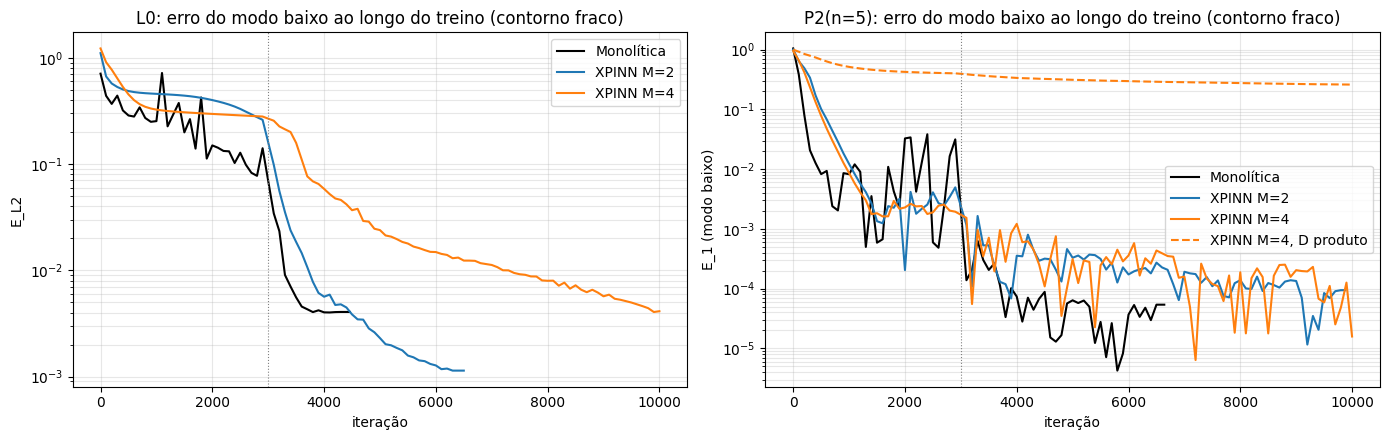

benchmark      config.  contorno  métrica  em 5000 it     final  iterações  platô       J_u       J_n     E_bal
       L0   Monolítica     fraco       L2    4.06e-03  4.06e-03       4460    sim         -         -   1.0e-05
       L0    XPINN M=2     fraco       L2    2.30e-03  1.14e-03       6500    sim   1.7e-03   4.8e-04   1.0e-05
       L0    XPINN M=4     fraco       L2    2.39e-02  4.12e-03      10000    não   9.9e-03   1.7e-03   9.6e-06
  P2(n=5)   Monolítica     fraco      E_1    6.36e-05  5.38e-05       6640    sim         -         -   3.6e-05
  P2(n=5)    XPINN M=2     fraco      E_1    3.28e-04  9.41e-05       9880    sim   3.1e-04   3.8e-04   1.4e-05
  P2(n=5)    XPINN M=4     fraco      E_1    3.11e-04  1.58e-05      10000    não   1.9e-03   5.9e-04   1.9e-04
  P2(n=5)    XPINN M=4     exato      E_1    3.12e-01  2.59e-01      10000    não   1.6e-03   2.6e-04   4.5e-01

L0, Monolítica, contorno fraco | E_bal = 1.00e-05 | soma dos I_k = -1.03e-05 | max |I_k| = 2.31e-05
L_P


L0, XPINN M=4, contorno fraco | E_bal = 9.65e-06 | soma dos I_k = -1.50e-05 | max |I_k| = 2.00e-05
L_PDE por subdomínio (linha de cima = faixa y em [3/4, 1]):
[[  1.3e-05   5.8e-06   5.7e-06   1.3e-05]
 [  1.0e-05   5.4e-06   1.5e-05   8.5e-06]
 [  7.0e-06   1.5e-05   1.4e-05   2.3e-05]
 [  1.5e-05   2.3e-05   3.5e-05   3.9e-05]]
I_k = integral do resíduo no subdomínio / int |du*/dn|:
[[ +1.5e-07  +1.8e-07  -4.7e-06  +7.7e-06]
 [ -3.7e-06  +9.7e-08  +1.0e-05  -4.1e-06]
 [ +3.5e-06  -5.2e-06  -1.0e-05  +5.1e-06]
 [ -9.8e-06  -8.0e-06  -1.6e-05  +2.0e-05]]

P2(n=5), Monolítica, contorno fraco | E_bal = 3.59e-05 | soma dos I_k = +3.78e-05 | max |I_k| = 4.58e-05
L_PDE por subdomínio (linha de cima = faixa y em [3/4, 1]):
[[  1.5e-03   5.3e-04   8.2e-04   2.1e-03]
 [  8.2e-04   3.2e-04   4.6e-04   5.8e-04]
 [  4.9e-04   6.8e-04   4.2e-04   1.2e-03]
 [  1.6e-03   1.9e-03   7.0e-04   1.1e-03]]
I_k = integral do resíduo no subdomínio / int |du*/dn|:
[[ +2.3e-05  -7.9e-07  +1.1e-05  -1.4e-05]



P2(n=5), XPINN M=4, contorno exato | E_bal = 4.55e-01 | soma dos I_k = -4.55e-01 | max |I_k| = 2.06e-01
L_PDE por subdomínio (linha de cima = faixa y em [3/4, 1]):
[[  1.5e+03   4.1e+02   1.6e-01   4.2e+02]
 [  3.9e-02   7.2e-03   4.5e+02   1.8e-02]
 [  7.2e-03   1.9e-02   6.0e-02   2.0e+00]
 [  3.8e+02   1.8e+04   3.0e-02   8.1e+02]]
I_k = integral do resíduo no subdomínio / int |du*/dn|:
[[ -7.7e-02  -2.6e-02  -5.0e-04  -3.7e-02]
 [ -3.7e-05  +1.7e-05  -3.0e-02  -1.5e-04]
 [ +5.4e-05  -2.2e-04  -3.6e-04  -2.3e-03]
 [ -2.5e-02  -2.1e-01  -1.4e-04  -5.1e-02]]


In [33]:
LONGO = dict(passos_lbfgs_max=350)          # teto: 3000 Adam + 350 x 20 L-BFGS = 10.000 iteracoes
propagacao = {}


def guardar(rede, hist, prob, chave, M):
    return dict(rede=rede, hist=hist, m=avaliar(rede, prob), bal=balanco_global(rede, prob), chave=chave,
                saltos=saltos_interface(rede, prob) if M > 1 else (None, None))


for nome, kw, chave in [("L0", {}, "L2"), ("P2", {"n": 5}, "E_1")]:
    prob = criar_problema(nome, **kw)
    rede, hist, tempo = treinar_pinn(prob, imprimir=False, **LONGO)
    propagacao[(prob["nome"], 1, "fraco")] = guardar(rede, hist, prob, chave, 1)
    for M in [2, 4]:
        rede, hist, tempo = treinar_xpinn(prob, M=M, imprimir=False, **LONGO)
        propagacao[(prob["nome"], M, "fraco")] = guardar(rede, hist, prob, chave, M)

# Caso da versao anterior: P2(5), M = 4, D produto
prob = criar_problema("P2", n=5)
rede, hist, tempo = treinar_xpinn(prob, M=4, contorno="exato", imprimir=False, **LONGO)
propagacao[("P2(n=5)", 4, "exato")] = guardar(rede, hist, prob, "E_1", 4)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for j, nome in enumerate(["L0", "P2(n=5)"]):
    for (n_, M, contorno), r in propagacao.items():
        if n_ != nome:
            continue
        cor = {1: "k", 2: "tab:blue", 4: "tab:orange"}[M]
        rotulo = ("Monolítica" if M == 1 else f"XPINN M={M}") + (", D produto" if contorno == "exato" else "")
        ax[j].semilogy(r["hist"]["aval_it"], r["hist"][r["chave"]], color=cor, ls="--" if contorno == "exato" else "-", label=rotulo)
    ax[j].axvline(3000, color="gray", ls=":", lw=.8)
    ax[j].set_xlabel("iteração")
    ax[j].set_ylabel("E_L2" if nome == "L0" else "E_1 (modo baixo)")
    ax[j].set_title(f"{nome}: erro do modo baixo ao longo do treino (contorno fraco)")
    ax[j].grid(True, which="both", alpha=.3)
    ax[j].legend()
plt.tight_layout()
plt.show()

print(f"{'benchmark':>9} {'config.':>12} {'contorno':>9} {'métrica':>8} {'em 5000 it':>11} {'final':>9} {'iterações':>10} {'platô':>6} {'J_u':>9} {'J_n':>9} {'E_bal':>9}")
for (nome, M, contorno), r in propagacao.items():
    h, k = r["hist"], r["chave"]
    em5000 = [v for it, v in zip(h["aval_it"], h[k]) if it <= 5000][-1]
    J_u, J_n = r["saltos"]
    js = f"{J_u:9.1e} {J_n:9.1e}" if J_u is not None else f"{'-':>9} {'-':>9}"
    cfg = "Monolítica" if M == 1 else f"XPINN M={M}"
    print(f"{nome:>9} {cfg:>12} {contorno:>9} {k:>8} {em5000:11.2e} {r['m'][k]:9.2e} {h['it_final']:10d} {'sim' if h['platô'] else 'não':>6} {js} {r['bal']:9.1e}")

# Residuo por subdominio numa particao 4 x 4 (a monolitica entra como referencia, com a mesma particao)
np.set_printoptions(precision=1, suppress=False, linewidth=120)
for chave_p in [("L0", 1, "fraco"), ("L0", 4, "fraco"), ("P2(n=5)", 1, "fraco"), ("P2(n=5)", 4, "fraco"), ("P2(n=5)", 4, "exato")]:
    r = propagacao[chave_p]
    prob = criar_problema("L0") if chave_p[0] == "L0" else criar_problema("P2", n=5)
    L_k, I_k = residuo_por_subdominio(r["rede"], prob, M=4)
    print(f"\n{chave_p[0]}, {'Monolítica' if chave_p[1] == 1 else 'XPINN M=4'}, contorno {chave_p[2]} "
          f"| E_bal = {r['bal']:.2e} | soma dos I_k = {I_k.sum():+.2e} | max |I_k| = {np.abs(I_k).max():.2e}")
    print("L_PDE por subdomínio (linha de cima = faixa y em [3/4, 1]):")
    print(np.array2string(L_k, formatter={"float_kind": lambda v: f"{v:9.1e}"}))
    print("I_k = integral do resíduo no subdomínio / int |du*/dn|:")
    print(np.array2string(I_k, formatter={"float_kind": lambda v: f"{v:+9.1e}"}))


**Como ler:**

**Com contorno fraco, o "colapso do modo baixo" da versão anterior desaparece.**
- **L0:** com 5000 iterações, o $M = 4$ ainda está em $2{,}4 \times 10^{-2}$, contra $4 \times 10^{-3}$ da monolítica. Com o teto de 10.000, ele chega a $4{,}1 \times 10^{-3}$, o mesmo nível, sem parar no platô. O $M = 2$ termina **melhor** que a monolítica ($1{,}1 \times 10^{-3}$, platô em 6500). Não há ordenação do erro **final** por $M$. O que cresce com $M$ é o número de iterações para chegar lá.
- **P2(5):** $E_1$ em 5000 iterações é ~5 vezes pior no XPINN ($3 \times 10^{-4}$ contra $6 \times 10^{-5}$). No fim, o $M = 4$ tem $E_1 = 1{,}6 \times 10^{-5}$, **melhor** que a monolítica. Nenhum dos XPINN com contorno fraco estagnou no modo baixo.
- **P2(5), $M = 4$, $D$ produto (o caso da versão anterior):** $E_1 \approx 0{,}26$ e $\mathcal{E}_{\text{bal}} \approx 0{,}45$, com saltos pequenos ($\mathcal{J}_u \sim 2 \times 10^{-3}$, $\mathcal{J}_n \sim 3 \times 10^{-4}$), o mesmo sintoma de antes.

**Onde está o resíduo.** Nas tabelas por subdomínio:
- **Com $D$ produto**, $\mathcal{L}_{PDE,k}$ vai de $7 \times 10^{-3}$ a $1{,}8 \times 10^4$. Os subdomínios ruins são quase todos encostados na borda (cantos e faixas de cima e de baixo, mais um interior). A soma $\sum_k I_k = -0{,}455$ reproduz **exatamente** o $\mathcal{E}_{\text{bal}} = 0{,}455$, e quase toda ela vem de quatro subdomínios ($-0{,}21$, $-0{,}077$, $-0{,}051$, $-0{,}037$).
- **O $\mathcal{E}_{\text{bal}}$ alto é explicado inteiro pela integral do resíduo** em poucos subdomínios onde a equação não é satisfeita na grade fina (o treino só controla os pontos de colocação). Não há nenhum componente global indeterminado. Isso confirma a correção feita acima.
- **Com contorno fraco**, $\mathcal{L}_{PDE,k}$ é homogêneo entre subdomínios (uma ordem de grandeza de variação) e os $|I_k|$ ficam em $10^{-5}$ a $10^{-4}$.
- Na monolítica, $\sum_k I_k$ acompanha o $\mathcal{E}_{\text{bal}}$ ($|\sum_k I_k| = 1{,}03 \times 10^{-5}$ contra $\mathcal{E}_{\text{bal}} = 1{,}00 \times 10^{-5}$ em L0; $3{,}8$ contra $3{,}6 \times 10^{-5}$ em P2(5)). No XPINN, a diferença entre os dois é o termo de salto do fluxo da identidade (por exemplo, $9{,}6 \times 10^{-4}$ contra $1{,}9 \times 10^{-4}$, com $\mathcal{J}_n \approx 6 \times 10^{-4}$).

**O que isso permite afirmar:**
- **A leitura "nível global errado" está retirada.** O colapso do modo baixo era um resíduo grande e localizado, ligado ao $D$ produto perto da borda. Não era uma falha de propagação entre subdomínios.
- **Da hipótese de decomposição de um nível, sobra só a previsão 2** (convergência mais lenta com $M$ maior): o $M = 4$ precisa de ~2 vezes as iterações da monolítica para chegar ao mesmo erro. A previsão 1, sobre o erro final, não se confirmou com contorno fraco. A previsão 3 ($\lambda_I$) é tratada na seção 13.
- **O XPINN de dois níveis deixa de ser necessário para corrigir acurácia.** Ele só se justifica se a velocidade de convergência importar.

### XPINN distribuído por replicação de parâmetros, em processos `gloo` (RQ1 do lado do XPINN)

**Como a carga é dividida.** Com $p$ processos e $M^2$ subdomínios ($p$ divide $M^2$):

- cada processo guarda **todos** os parâmetros (são ~12 mil) e calcula só a EDP e o contorno dos **seus** $M^2/p$ subdomínios, e um a cada $p$ segmentos de interface;
- as somas locais são divididas pelos totais **globais** ($N_f$, $N_b$, $N_I \times$ número de segmentos), então a perda global é a **soma** das perdas locais;
- depois de cada `backward`, os gradientes são **somados entre processos** (all-reduce). Cada processo tem então o gradiente exato da perda global e a mesma perda global.

**As três condições da seção 11, uma a uma:**

1. **Troca síncrona a cada iteração:** é o all-reduce dos gradientes. Ele carrega a informação da interface: quem calcula um segmento avalia as duas sub-redes vizinhas e manda o gradiente para as duas.
2. **Médias pelo total global:** feito acima.
3. **O L-BFGS continua o mesmo algoritmo:** todos os processos têm o mesmo vetor de parâmetros, o mesmo gradiente e a mesma perda, então os produtos internos e a busca de linha dão o mesmo resultado em todos.

O código é o mesmo `treinar_xpinn`, com `distribuido=True`. A comunicação por iteração é a de um DDP: um all-reduce do tamanho do modelo.

**Que tipo de paralelismo é este.** Na prática, é **paralelismo de dados particionado por subdomínio**: todos os processos têm todos os parâmetros, e o que se divide é o cálculo da perda. **Não** é o esquema de Shukla et al. (2021), em que cada processo guarda uma sub-rede e troca com os vizinhos só os valores da interface. Duas consequências:

- **A RQ4 (custo de sincronizar as interfaces) não é medida aqui.** Não existe comunicação de interface, só um all-reduce do tamanho do modelo inteiro.
- **No TCC, o esquema deve ser nomeado com precisão:** "XPINN distribuído por replicação de parâmetros". O esquema por interface fica como trabalho futuro, e a redação da RQ4 precisa ser ajustada a isso.

**A alternativa não implementada:** cada processo guarda só a sua sub-rede e troca com os vizinhos os valores de interface ($u$, $\nabla^2 u$, $\partial_n u$). Isso economiza memória e comunicação para redes grandes. Mas exige um L-BFGS com produtos internos distribuídos (condição 3). Com sub-redes de 12 mil parâmetros, a memória não é o gargalo.

**Desequilíbrio de carga:** os pontos de colocação (LHS) não se dividem igualmente entre subdomínios (seção 11: de 109 a 141 por subdomínio com $M = 4$). O processo mais carregado dita o ritmo.

**Protocolo** (fixado antes), em CPU, 1 thread por processo:

- **Verificação:** P1, XPINN $M = 2$ iso-parâmetro, contorno fraco, orçamento fixo de 5000 iterações sem platô. $p = 4$ (um subdomínio por processo) contra o mesmo `treinar_xpinn` sequencial em CPU, 10 sementes. Mesmas perguntas da seção 10: as perdas coincidem no começo? O TOST com margem $[0{,}8;\ 1{,}25]$ demonstra equivalência?
- **Tempo:** $M = 2$ e $M = 4$ (iso-parâmetro), $N_f \in \{2000, 8000\}$, $p \in \{1, 2, 4\}$, orçamento curto (700 iterações), afinidade fixa, cada execução sozinha. Ajuste de Amdahl como na seção 10.

In [19]:
with open("pinn_xpinn.py", "w", encoding="utf-8") as arquivo:
    arquivo.write("# Gerado automaticamente a partir do notebook. Nao editar a mao.\n")
    arquivo.write("import math\n\nimport numpy as np\nimport torch\nimport torch.distributed as dist\n\nfrom pinn_comum import *\n")
    arquivo.write("\n\n" + codigo_fonte(XPINN))          # a celula inteira das definicoes do XPINN, inclusive treinar_xpinn

import pinn_xpinn
importlib.reload(pinn_xpinn)

# Teste rapido do lancamento: M = 2 com 4 processos e a referencia sequencial (40 iteracoes)
teste = rodar_ddp_lote([dict(nome="P1", p=4, M=2, epocas_adam=20, passos_lbfgs=1, sem_plato=True, reaproveitar=False),
                        dict(nome="P1", p=1, M=2, epocas_adam=20, passos_lbfgs=1, sem_plato=True, reaproveitar=False)])
print("pinn_xpinn.py gravado | E_L2 após 40 iterações: XPINN distribuído p=4 {:.3e} | sequencial {:.3e}".format(
      teste[0]["metricas"]["L2"], teste[1]["metricas"]["L2"]))


pinn_xpinn.py gravado | E_L2 após 40 iterações: XPINN distribuído p=4 1.295e-01 | sequencial 1.295e-01


XPINN M=2, p = 4: diferença relativa de L_PDE nas 100 primeiras iterações: máx 1.9e-07 | no fim: 3.0e-02


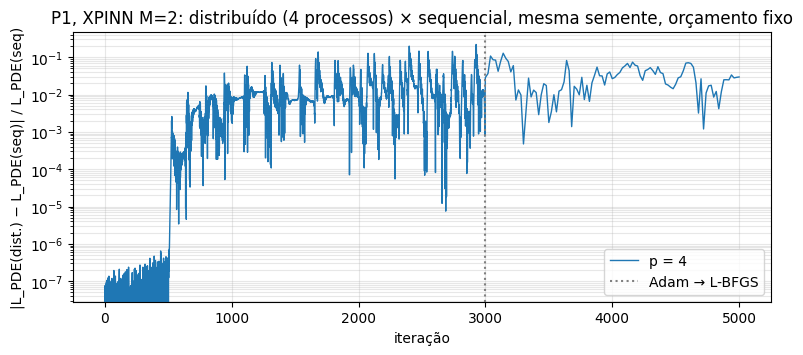


Iterações finais: p=1: [5000], p=4: [5000]

semente  E_L2 seq.  E_L2 p = 4
      0   2.84e-04    3.12e-04
      1   3.14e-04    3.14e-04
      2   2.41e-04    2.76e-04
      3   4.23e-04    4.01e-04
      4   4.22e-04    4.40e-04
      5   2.39e-04    2.24e-04
      6   4.36e-04    4.02e-04
      7   3.51e-04    3.25e-04
      8   3.71e-04    3.65e-04
      9   1.43e-04    1.63e-04

razão geométrica distribuído/sequencial 1.011 | IC 90% [0.962, 1.062] | TOST p = 1.3e-05 -> equivalência demonstrada a 5%
Fator de dispersão entre sementes: sequencial 1.42 | p=4 1.35


In [20]:
SEMENTES_XD = list(range(10))
tarefas = [dict(nome="P1", p=p, M=2, semente=s, **ORCAMENTO_FIXO) for s in SEMENTES_XD for p in (1, 4)]
verif_x = {(t["p"], t["semente"]): r for t, r in zip(tarefas, rodar_ddp_lote(tarefas))}

h_seq = verif_x[(1, 0)]["hist"]
pde_seq, its = np.array(h_seq["pde"]), np.array(h_seq["it"])
dif = np.abs(np.array(verif_x[(4, 0)]["hist"]["pde"]) - pde_seq) / pde_seq
print(f"XPINN M=2, p = 4: diferença relativa de L_PDE nas 100 primeiras iterações: máx {dif[:100].max():.1e} | no fim: {dif[-1]:.1e}")
plt.figure(figsize=(9, 3.5))
plt.semilogy(its, dif, lw=1, label="p = 4")
plt.axvline(h_seq["fim_adam"], color="gray", ls=":", label="Adam → L-BFGS")
plt.xlabel("iteração")
plt.ylabel("|L_PDE(dist.) − L_PDE(seq)| / L_PDE(seq)")
plt.title("P1, XPINN M=2: distribuído (4 processos) × sequencial, mesma semente, orçamento fixo")
plt.legend()
plt.grid(True, which="both", alpha=.3)
plt.show()

print(f"\nIterações finais: " + ", ".join(f"p={p}: {sorted({verif_x[(p, s)]['hist']['it_final'] for s in SEMENTES_XD})}" for p in (1, 4)))
print(f"\n{'semente':>7} {'E_L2 seq.':>10} {'E_L2 p = 4':>11}")
for s in SEMENTES_XD:
    print(f"{s:>7} {verif_x[(1, s)]['metricas']['L2']:10.2e} {verif_x[(4, s)]['metricas']['L2']:11.2e}")
l2_seq = [verif_x[(1, s)]["metricas"]["L2"] for s in SEMENTES_XD]
l2_dist = [verif_x[(4, s)]["metricas"]["L2"] for s in SEMENTES_XD]
razao, (ic_lo, ic_hi), p_tost = tost_log(l2_dist, l2_seq, margem=MARGEM_TOST)
print(f"\nrazão geométrica distribuído/sequencial {razao:.3f} | IC 90% [{ic_lo:.3f}, {ic_hi:.3f}] | TOST p = {p_tost:.2g} -> "
      f"{'equivalência demonstrada a 5%' if p_tost < ALFA else 'equivalência NÃO demonstrada'}")
print("Fator de dispersão entre sementes: sequencial {:.2f} | p=4 {:.2f}".format(resumo_log(l2_seq)[1], resumo_log(l2_dist)[1]))


In [21]:
P_XD = [1, 2, 4]
NF_XD = [2000, 8000]
CURTO_XD = dict(epocas_adam=500, passos_lbfgs=10, sem_plato=True, sem_avaliacao=True)

t_xd = {}
for M in (2, 4):
    for N_f in NF_XD:
        for p in P_XD:
            r = rodar_ddp("P1", p=p, M=M, N_f=N_f, semente=0, **CURTO_XD, **MEDICAO)
            t_xd[(M, N_f, p)] = r["tempo"] / r["hist"]["it_final"]

print(f"{'M':>3} {'N_f':>6} {'p':>3} {'subdom./processo':>17} {'ms/iteração':>12} {'S(p)':>6} {'eficiência':>11}")
f_xd = {}
for M in (2, 4):
    for N_f in NF_XD:
        S = {p: t_xd[(M, N_f, 1)] / t_xd[(M, N_f, p)] for p in P_XD}
        for p in P_XD:
            print(f"{M:>3} {N_f:>6} {p:>3} {M * M // p:>17} {1000 * t_xd[(M, N_f, p)]:12.1f} {S[p]:6.2f} {S[p] / p:11.2f}")
        x = np.array([1 - 1 / p for p in P_XD[1:]])
        y = np.array([1 - 1 / S[p] for p in P_XD[1:]])
        f_xd[(M, N_f)] = float(x @ y / (x @ x))
        f = f_xd[(M, N_f)]
        print(f"{'':>3} Amdahl (Eq. 17): f = {f:.3f} | S(p -> infinito) = {1 / (1 - f) if f < 1 else float('inf'):.1f}\n")


  M    N_f   p  subdom./processo  ms/iteração   S(p)  eficiência
  2   2000   1                 4         40.6   1.00        1.00
  2   2000   2                 2         35.1   1.16        0.58
  2   2000   4                 1         39.1   1.04        0.26
    Amdahl (Eq. 17): f = 0.118 | S(p -> infinito) = 1.1

  2   8000   1                 4         86.7   1.00        1.00
  2   8000   2                 2         64.6   1.34        0.67
  2   8000   4                 1         60.3   1.44        0.36
    Amdahl (Eq. 17): f = 0.439 | S(p -> infinito) = 1.8

  4   2000   1                16         38.1   1.00        1.00
  4   2000   2                 8         32.7   1.17        0.58
  4   2000   4                 4         36.6   1.04        0.26
    Amdahl (Eq. 17): f = 0.124 | S(p -> infinito) = 1.1

  4   8000   1                16         60.0   1.00        1.00
  4   8000   2                 8         45.9   1.31        0.65
  4   8000   4                 4         44.6   1

**Como ler:**

- **Lançamento:** depois de 40 iterações, o $\mathcal{E}_{L^2}$ do XPINN distribuído ($p = 4$) e o do sequencial coincidem ($1{,}295 \times 10^{-1}$).
- **Verificação:**
  - as perdas coincidem até $1{,}9 \times 10^{-7}$ nas 100 primeiras iterações, o arredondamento de `float32`;
  - no fim, a diferença relativa de $\mathcal{L}_{PDE}$ é de 3%, bem menor que os ~100% do DDP monolítico;
  - todas as execuções foram até 5000 iterações.
- **TOST: equivalência demonstrada.** Razão distribuído/sequencial 1,01, IC 90% $[0{,}96;\ 1{,}06]$, $p = 1{,}3 \times 10^{-5}$, 10 sementes. As três condições da seção 11 valem na prática.
- **Tempo: o XPINN distribuído quase não acelera.**

| $N_f$ | $M$ | $S(2)$ | $S(4)$ | $f$ (Amdahl) |
|---|---|---|---|---|
| 2000 | 2 | 1,16 | 1,04 | 0,12 |
| 2000 | 4 | 1,17 | 1,04 | 0,12 |
| 8000 | 2 | 1,34 | 1,44 | 0,44 |
| 8000 | 4 | 1,31 | 1,34 | 0,38 |

  Para comparação, o DDP monolítico com $N_f = 2400$ tem $S(4) = 1{,}74$ e $f = 0{,}57$.
- **Por que escala mal** (hipóteses, não medidas separadamente):
  - O XPINN sequencial em CPU já é barato (~40 ms por iteração com $N_f = 2000$), porque cada ponto passa por uma sub-rede estreita. Sobra pouca conta para dividir. O custo fixo de cada iteração não cai com $p$: lançar as operações, o autograd e o all-reduce de ~12 mil gradientes.
  - Os termos de interface avaliam duas sub-redes e as derivadas segundas por segmento.
  - Há desequilíbrio de carga entre subdomínios.
  - Com $N_f = 8000$ o speedup melhora, o que é coerente com uma parte fixa por iteração.
- **CPU contra GPU:** com $p = 1$ em CPU, o XPINN custa ~40 ms por iteração com $N_f = 2000$; na GPU (seção 12), ~100 ms. Com redes deste tamanho, a CPU de 1 thread é mais rápida. É por isso que o XPINN da seção 13 roda em CPU.
- **Custo por ponto da arquitetura** (sem paralelismo: $p = 1$, cada execução sozinha, afinidade fixa, 500 Adam + 10 L-BFGS, P1). Juntando esta tabela com a da seção 10:

| Configuração (CPU, 1 processo) | $N_f$ | ms/iteração | ms por ponto |
|---|---|---|---|
| Monolítica 4 × 64 | 2400 / 4800 / 9600 | 60 / 112 / 230 | 0,025 / 0,023 / 0,024 |
| XPINN $M = 2$ iso-parâmetro (largura 31) | 2000 / 8000 | 41 / 87 | 0,020 / 0,011 |
| XPINN $M = 4$ iso-parâmetro (largura 15) | 2000 / 8000 | 38 / 60 | 0,019 / 0,0075 |

  - Com a mesma capacidade total, o XPINN $M = 4$ custa **~3 vezes menos por ponto** com $N_f = 8000$, e ~1,3 vez menos com $N_f = 2000$, onde o custo fixo de cada iteração domina. O ganho é **estrutural**: cada ponto passa por uma sub-rede estreita, e a conta de uma camada cresce com o quadrado da largura. Vem da **arquitetura**, e não do paralelismo.
  - Limites: os $N_f$ não são idênticos (a monolítica custa ~0,024 ms por ponto em toda a faixa, então a comparação vale); o XPINN inclui os termos de interface; é uma medição de custo por iteração, e não de *time-to-solution*. Os ~30 contra ~7 min por execução da verificação da seção 13 vêm de execuções simultâneas e não servem para isso.
- **Para a H1:** distribuir o XPINN por replicação de parâmetros **preserva a acurácia** (equivalência demonstrada). Mas, neste hardware e com estas redes, **não dá ganho de tempo útil**.
- **A RQ4 fica sem resposta:** o tempo medido aqui é o de um all-reduce do modelo inteiro, e não o de sincronizar interfaces entre sub-redes em processos diferentes.


---
## 12. Piloto L0 e estimativa de custo

A §13 do documento recomenda medir o tempo de uma execução de cada configuração em L0 **antes** de decidir o conjunto complementar. O custo **por iteração** praticamente não depende do benchmark (mesmos $N_f$, rede e otimizador; só muda $f$). Mas, com a parada por platô, o **número de iterações** depende do benchmark: P2 com $n$ alto tende a ir até o teto. A estimativa abaixo usa o tempo por iteração de L0 e o **teto** de iterações (5000), então é um limite superior.

As quatro configurações de acurácia do núcleo, todas com contorno fraco, mais a referência sequencial em CPU:

| Configuração | Implementação aqui | Dispositivo |
|---|---|---|
| Monolítica | `treinar_pinn` (seção 5) | GPU |
| DDP $p=4$ | 4 processos `gloo` + `treinar_pinn(..., distribuido=True)` | CPU, 1 thread por processo |
| XPINN $M=2$ | `treinar_xpinn(M=2)`, iso-parâmetro, com fluxo | GPU |
| XPINN $M=4$ | `treinar_xpinn(M=4)`, iso-parâmetro, com fluxo | GPU |
| (referência) Sequencial CPU | `treinar_pinn` em CPU, 1 thread | CPU |

Os tempos de GPU e de CPU entram juntos só na estimativa de custo total; não servem para comparar arquiteturas.

In [34]:
prob = criar_problema("L0")
piloto = {}
_, _, h_mono, t_mono, m_mono = resultados["L0"]
piloto["Monolítica"] = (m_mono["L2"], t_mono, h_mono["it_final"], "GPU")

for nome_cfg, p in [("DDP p=4", 4), ("Sequencial CPU", 1)]:
    r = rodar_ddp("L0", p=p, semente=0)
    piloto[nome_cfg] = (r["metricas"]["L2"], r["tempo"], r["hist"]["it_final"], "CPU")

for M in [2, 4]:
    rede, hist, tempo = treinar_xpinn(prob, M=M, imprimir=False)
    piloto[f"XPINN M={M}"] = (avaliar(rede, prob)["L2"], tempo, hist["it_final"], "GPU")
    J_u, J_n = saltos_interface(rede, prob)
    print(f"XPINN M={M}: saltos na avaliação J_u = {J_u:.1e}, J_n = {J_n:.1e}; E_bal = {balanco_global(rede, prob):.1e}")

print(f"{'configuração':>15} {'dispositivo':>12} {'E_L2':>9} {'tempo (s)':>10} {'iterações':>10} {'ms/iteração':>12}")
for nome, (l2, t, it, disp) in piloto.items():
    print(f"{nome:>15} {disp:>12} {l2:9.2e} {t:10.1f} {it:10d} {1000 * t / it:12.1f}")


XPINN M=2: saltos na avaliação J_u = 4.0e-03, J_n = 7.4e-04; E_bal = 5.0e-05


XPINN M=4: saltos na avaliação J_u = 7.2e-02, J_n = 6.6e-03; E_bal = 7.3e-04
   configuração  dispositivo      E_L2  tempo (s)  iterações  ms/iteração
     Monolítica          GPU  4.06e-03      130.1       4460         29.2
        DDP p=4          CPU  2.88e-03      145.7       4520         32.2
 Sequencial CPU          CPU  2.39e-03      278.2       5000         55.6
      XPINN M=2          GPU  2.30e-03      520.0       5000        104.0
      XPINN M=4          GPU  2.39e-02      515.6       5000        103.1


### Estimativa (§13)

Por configuração, o núcleo tem 70 execuções: L0, P0 e P1 com 10 sementes (30) e P2 com 4 valores de $n$ e 10 sementes (40). Os complementares (160 execuções) são estimados com o tempo médio por iteração das quatro configurações. Todas as execuções são contadas no teto de 5000 iterações.

In [35]:
EXECUCOES_NUCLEO_POR_CONFIG = 3 * N_SEMENTES + 4 * N_SEMENTES      # = 70
EXECUCOES_COMPLEMENTARES = 160
TETO_ITERACOES = 3000 + 100 * 20
CONFIGS_NUCLEO = ["Monolítica", "DDP p=4", "XPINN M=2", "XPINN M=4"]

total_nucleo = 0.0
print(f"{'configuração':>13} {'dispositivo':>12} {'execuções':>10} {'limite superior':>16}")
for nome in CONFIGS_NUCLEO:
    _, t, it, disp = piloto[nome]
    custo = EXECUCOES_NUCLEO_POR_CONFIG * TETO_ITERACOES * t / it
    total_nucleo += custo
    print(f"{nome:>13} {disp:>12} {EXECUCOES_NUCLEO_POR_CONFIG:>10} {custo / 3600:14.2f} h")

t_it_medio = np.mean([piloto[c][1] / piloto[c][2] for c in CONFIGS_NUCLEO])
total_comp = EXECUCOES_COMPLEMENTARES * TETO_ITERACOES * t_it_medio
print(f"\nNúcleo ({4 * EXECUCOES_NUCLEO_POR_CONFIG} execuções): até {total_nucleo / 3600:.1f} h")
print(f"Complementares ({EXECUCOES_COMPLEMENTARES} execuções): até {total_comp / 3600:.1f} h")
print(f"Total: até {(total_nucleo + total_comp) / 3600:.1f} h de treino, uma execução por vez, sem contar avaliação nem filas")


 configuração  dispositivo  execuções  limite superior
   Monolítica          GPU         70           2.84 h
      DDP p=4          CPU         70           3.13 h
    XPINN M=2          GPU         70          10.11 h
    XPINN M=4          GPU         70          10.03 h

Núcleo (280 execuções): até 26.1 h
Complementares (160 execuções): até 14.9 h
Total: até 41.0 h de treino, uma execução por vez, sem contar avaliação nem filas


**Como ler:**

- **Acurácia em L0** (contorno fraco, critério $10^{-2}$): monolítica $4{,}1 \times 10^{-3}$, DDP $p = 4$ $2{,}9 \times 10^{-3}$, sequencial em CPU $2{,}4 \times 10^{-3}$, XPINN $M = 2$ $2{,}3 \times 10^{-3}$. Todos passam. **O XPINN $M = 4$ fica em $2{,}4 \times 10^{-2}$** no orçamento padrão de 5000 iterações; a seção 11 mostra que ele chega a $4 \times 10^{-3}$ com 10.000. **A preservação de acurácia (H1) só está sustentada para a paralelização em si:** o DDP não piora a acurácia (seção 10: não inferioridade com 20 sementes, mas equivalência não demonstrada) e o XPINN distribuído reproduz o XPINN sequencial (seção 11: equivalência demonstrada). Para o XPINN **como arquitetura**, comparado com a monolítica, os dados não bastam: o $M = 2$ passa em L0 com uma semente, mas na grade de P2 é pior que a monolítica em $n = 5$ e $n = 7$; o $M = 4$ precisa de orçamento maior.
- **Tempo por iteração:** monolítica 29 ms (GPU), DDP $p = 4$ 32 ms (CPU), sequencial 56 ms (CPU), XPINN ~104 ms (GPU).
  - **A GPU quase não acelera estas redes.** A monolítica na GPU (29 ms) custa o mesmo que na CPU de 1 thread da versão anterior (27 ms). Durante a execução, a GPU ficou em ~10% de uso, com um núcleo de CPU saturado. O custo é o lançamento das operações e o autograd de uma rede de 12 mil parâmetros, e não a conta.
  - **O XPINN custa ~3,5 vezes a monolítica por iteração** (sub-redes em lote, termos de interface, mais derivadas).
- **Custo do protocolo completo:** até ~26 h para o núcleo e ~41 h com os complementares, uma execução por vez e todas no teto de iterações. As execuções de DDP (CPU) podem rodar ao mesmo tempo que as de GPU, mas cada processo de GPU também ocupa um núcleo de CPU.

---
## 13. P2 completo (contorno fraco)

A grade da §11 do documento: $n \in \{5, 7, 11, 13\}$, $\varepsilon = 0{,}1$ e $M \in \{2, 4\}$, mais o **controle alinhado** $n = 12$ (§12.3), em que $M$ divide $n$ para $M = 2$ e $M = 4$ e as interfaces caem sobre nós do modo $\varphi_{nn}$.

**Toda a seção usa contorno fraco**, nas duas arquiteturas. A versão anterior desta grade usava $D$ produto, que a seção 9 mostrou prejudicar a monolítica em P2; aqueles resultados foram descartados.

Cinco configurações por $n$:

| Configuração | Para quê |
|---|---|
| Monolítica (largura 64) | Referência |
| XPINN $M = 2$ e $M = 4$, **iso-parâmetro** | Comparação com a mesma capacidade total (H2) |
| XPINN $M = 2$ e $M = 4$, **iso-largura** (64) | Sub-redes com a **mesma arquitetura** da monolítica. É a família certa para testar a dependência em $n/M$: a monolítica é o caso $M = 1$ dela |

- **O XPINN desta seção roda em CPU** (1 thread), por custo; a monolítica continua na GPU. Por semente, o dispositivo muda a trajetória do XPINN (inicialização e ordem das somas), então um mesmo número de semente não dá o mesmo XPINN na GPU e na CPU. O pareamento continua valendo pelos pontos de colocação, que são os mesmos, e o que se compara é a **distribuição** do erro entre sementes.
- **$\lambda_I$ é escolhido primeiro**, com sementes separadas, e o valor escolhido vale para todos os XPINN da seção.
- O DDP fica de fora: ele não muda o problema de otimização (seção 10), então não altera $E_n$.
- **Uma semente por configuração** (`N_SEMENTES_P2 = 1`). Tudo nesta grade é **indicação**, não resultado. A comparação pareada com várias sementes vem depois.
- As execuções monolíticas de $n = 5$ e $n = 11$ da seção 6 são reaproveitadas (na re-execução parcial, foram refeitas; o treino é determinístico).
- Por custo, o controle alinhado $n = 12$ roda só com a monolítica e o XPINN iso-parâmetro.
- Para o XPINN, a tabela inclui os saltos medidos na avaliação ($\mathcal{J}_u$, $\mathcal{J}_n$) e o balanço global.
- **Limitação de amostragem:** com $N_f = 2000$ fixo há ~45 pontos por direção, ou ~$90/n$ pontos por comprimento de onda: ~18 em $n = 5$, ~8 em $n = 11$, ~7 em $n = 13$. Nesta grade isso basta. Para $n$ maior, uma falha com $N_f$ fixo pode ser **subamostragem**, e não dificuldade da rede; a varredura do fim da seção mantém os pontos por comprimento de onda constantes.

### Primeiro passo: escolha de $\lambda_I$ com sementes (§12.4)

Na versão anterior, a sensibilidade a $\lambda_I$ usou uma semente e mostrou $\lambda_I = 0{,}1$ cerca de 2 vezes melhor que 1. Mesmo assim, a comparação pareada rodou com $\lambda_I = 1$. Isso desequilibra a comparação **contra** o XPINN: o mesmo tipo de problema do $D$ produto, do outro lado.

Protocolo, fixado antes de rodar:
- P2(11), XPINN $M = 4$ iso-parâmetro, contorno fraco, orçamento padrão;
- $\lambda_I \in \{0{,}03;\ 0{,}1;\ 0{,}3;\ 1\}$ com as sementes **10, 11 e 12**, separadas das sementes 0 a 5 das comparações pareadas (escolher e testar nas mesmas sementes favoreceria o XPINN);
- **critério:** a menor média geométrica de $\mathcal{E}_{L^2}$, que junta as duas escalas. $E_n$, $E_1$, $\mathcal{J}_n$ e $\mathcal{E}_{\text{bal}}$ são impressos para conferir que o escolhido não troca acurácia por saltos grandes na interface;
- o valor escolhido (`LAM_I`) entra em **todos** os XPINN desta seção: na grade e nas comparações pareadas em $n = 11$ e $n = 13$.

In [22]:
LAM_I_CANDIDATOS = [0.03, 0.1, 0.3, 1.0]
SEMENTES_LAM_I = [10, 11, 12]          # separadas das sementes 0-5 das comparacoes pareadas
DISPOSITIVO_XPINN = torch.device("cpu")   # XPINN da secao 13 em CPU: ~43 ms/iteracao, contra ~100 ms na GPU


def geom(v):
    return float(10 ** np.mean(np.log10(v)))


prob = criar_problema("P2", n=11)
escolha_I = {}
for lam_i in LAM_I_CANDIDATOS:
    escolha_I[lam_i] = []
    for s in SEMENTES_LAM_I:
        with DISPOSITIVO_XPINN:
            rede, hist, tempo = treinar_xpinn(prob, M=4, lam_i=lam_i, semente=s, imprimir=False)
            m = avaliar(rede, prob)
            J_u, J_n = saltos_interface(rede, prob)
            escolha_I[lam_i].append(dict(L2=m["L2"], E_n=m["E_n"], E_1=m["E_1"], J_n=J_n, bal=balanco_global(rede, prob),
                                         plato=hist["platô"]))

print(f"{'lam_I':>6} {'E_L2 geom.':>11} {'E_L2 máx':>9} {'E_n geom.':>10} {'E_n máx':>8} {'E_1 geom.':>10} {'J_n geom.':>10} {'E_bal geom.':>12} {'platô':>6}")
for lam_i, ls in escolha_I.items():
    print(f"{lam_i:6.2f} {geom([l['L2'] for l in ls]):11.2e} {max(l['L2'] for l in ls):9.2e} {geom([l['E_n'] for l in ls]):10.3f} "
          f"{max(l['E_n'] for l in ls):8.3f} {geom([l['E_1'] for l in ls]):10.2e} {geom([l['J_n'] for l in ls]):10.1e} "
          f"{geom([l['bal'] for l in ls]):12.1e} {sum(l['plato'] for l in ls):>4}/{len(ls)}")

LAM_I = min(LAM_I_CANDIDATOS, key=lambda l: geom([r["L2"] for r in escolha_I[l]]))
print(f"\nEscolhido pelo critério fixado antes (menor E_L2 geométrico nas sementes 10-12): LAM_I = {LAM_I}")


 lam_I  E_L2 geom.  E_L2 máx  E_n geom.  E_n máx  E_1 geom.  J_n geom.  E_bal geom.  platô
  0.03    1.03e-02  1.28e-02      0.005    0.007   1.81e-03    5.5e-03      5.3e-04    0/3
  0.10    1.05e-02  1.22e-02      0.002    0.005   4.06e-03    5.0e-03      6.1e-03    0/3
  0.30    2.78e-02  5.02e-02      0.007    0.011   1.51e-02    4.7e-03      3.0e-02    0/3
  1.00    2.20e-02  2.46e-02      0.015    0.018   6.10e-03    5.1e-03      8.0e-03    0/3

Escolhido pelo critério fixado antes (menor E_L2 geométrico nas sementes 10-12): LAM_I = 0.03


In [23]:
N_SEMENTES_P2 = 1
VALORES_N = [5, 7, 11, 12, 13]
CONFIGS_XPINN = {"XPINN M=2 iso-par.": (2, None), "XPINN M=4 iso-par.": (4, None),
                 "XPINN M=2 iso-larg.": (2, 64), "XPINN M=4 iso-larg.": (4, 64)}


def registrar_grade(m, hist, tempo, M, rede, prob):
    J_u, J_n = saltos_interface(rede, prob) if M > 1 else (None, None)
    return dict(m, tempo=tempo, tts=time_to_solution(hist, "E_n", 0.1), M=M, plato=hist["platô"], it=hist["it_final"],
                J_u=J_u, J_n=J_n, bal=balanco_global(rede, prob))


grade_p2 = {}       # (n, configuração) -> métricas + time-to-solution
for n in VALORES_N:
    prob = criar_problema("P2", n=n)
    if f"P2(n={n})" in resultados:
        _, rede, hist, tempo, _ = resultados[f"P2(n={n})"]
    else:
        rede, hist, tempo = treinar_pinn(prob, imprimir=False)
    grade_p2[(n, "Monolítica")] = registrar_grade(avaliar(rede, prob), hist, tempo, 1, rede, prob)

    for cfg, (M, largura) in CONFIGS_XPINN.items():
        if largura == 64 and n == 12:
            continue                     # custo: o caso alinhado roda so em iso-parametro
        with DISPOSITIVO_XPINN:
            rede, hist, tempo = treinar_xpinn(prob, M=M, largura=largura, lam_i=LAM_I, imprimir=False)
            grade_p2[(n, cfg)] = registrar_grade(avaliar(rede, prob), hist, tempo, M, rede, prob)

    print(f"n = {n:2d}: " + " | ".join(f"{c}: E_n {grade_p2[(n, c)]['E_n']:.3f}" for c in ["Monolítica", *CONFIGS_XPINN] if (n, c) in grade_p2))

n =  5: Monolítica: E_n 0.000 | XPINN M=2 iso-par.: E_n 0.000 | XPINN M=4 iso-par.: E_n 0.010 | XPINN M=2 iso-larg.: E_n 0.000 | XPINN M=4 iso-larg.: E_n 0.006


n =  7: Monolítica: E_n 0.001 | XPINN M=2 iso-par.: E_n 0.000 | XPINN M=4 iso-par.: E_n 0.001 | XPINN M=2 iso-larg.: E_n 0.000 | XPINN M=4 iso-larg.: E_n 0.002


n = 11: Monolítica: E_n 0.001 | XPINN M=2 iso-par.: E_n 0.001 | XPINN M=4 iso-par.: E_n 0.011 | XPINN M=2 iso-larg.: E_n 0.000 | XPINN M=4 iso-larg.: E_n 0.005


n = 12: Monolítica: E_n 0.042 | XPINN M=2 iso-par.: E_n 0.007 | XPINN M=4 iso-par.: E_n 0.031


n = 13: Monolítica: E_n 0.104 | XPINN M=2 iso-par.: E_n 0.014 | XPINN M=4 iso-par.: E_n 0.004 | XPINN M=2 iso-larg.: E_n 0.010 | XPINN M=4 iso-larg.: E_n 0.000


In [24]:
print(f"{'n':>3} {'configuração':>20} {'n/M':>6} {'E_L2':>9} {'E_n':>7} {'E_1':>9} {'E_esp':>9} {'iter.':>6} {'platô':>6} {'J_u':>8} {'J_n':>8} {'E_bal':>8}")
for (n, cfg), m in grade_p2.items():
    alinhado = "  <- M divide n" if (m["M"] > 1 and n % m["M"] == 0) else ""
    js = f"{m['J_u']:8.1e} {m['J_n']:8.1e}" if m["J_u"] is not None else f"{'-':>8} {'-':>8}"
    print(f"{n:>3} {cfg:>20} {n / m['M']:6.2f} {m['L2']:9.2e} {m['E_n']:7.3f} {m['E_1']:9.2e} {m['E_esp']:9.2e} {m['it']:6d} {'sim' if m['plato'] else 'não':>6} {js} {m['bal']:8.1e}{alinhado}")

  n         configuração    n/M      E_L2     E_n       E_1     E_esp  iter.  platô      J_u      J_n    E_bal
  5           Monolítica   5.00  2.21e-04   0.000  6.36e-05  2.13e-04   5000    não        -        -  4.3e-05
  5   XPINN M=2 iso-par.   2.50  7.93e-04   0.000  9.71e-05  7.90e-04   5000    não  3.4e-03  1.2e-03  4.2e-05
  5   XPINN M=4 iso-par.   1.25  3.32e-03   0.010  1.05e-04  3.19e-03   5000    não  1.0e-02  2.0e-03  8.1e-04
  5  XPINN M=2 iso-larg.   2.50  4.57e-04   0.000  8.68e-05  4.50e-04   5000    não  2.2e-03  7.0e-04  3.7e-06
  5  XPINN M=4 iso-larg.   1.25  1.75e-03   0.006  1.65e-04  1.65e-03   5000    não  5.3e-03  1.4e-03  1.1e-04
  7           Monolítica   7.00  6.22e-04   0.001  3.78e-05  6.22e-04   5000    não        -        -  2.1e-04
  7   XPINN M=2 iso-par.   3.50  6.31e-04   0.000  3.35e-04  5.38e-04   5000    não  2.3e-03  1.4e-03  1.9e-05
  7   XPINN M=4 iso-par.   1.75  4.53e-03   0.001  8.74e-04  4.47e-03   5000    não  1.6e-02  3.7e-03  2.3e-03
 

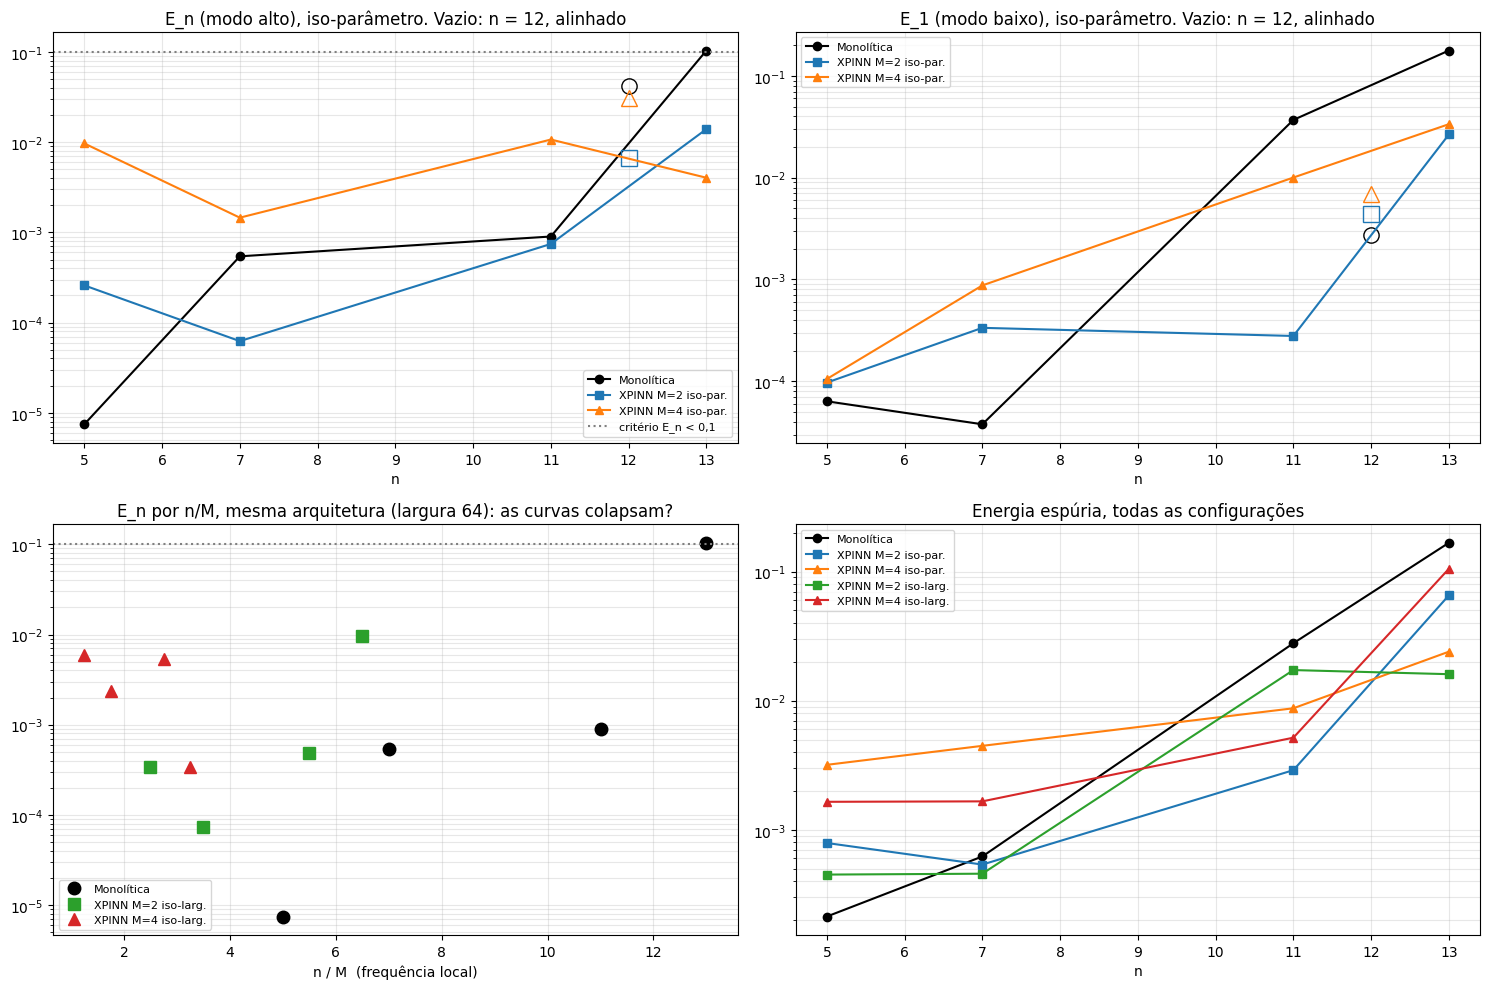

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
estilos = {"Monolítica": ("k", "o"), "XPINN M=2 iso-par.": ("tab:blue", "s"), "XPINN M=4 iso-par.": ("tab:orange", "^"),
           "XPINN M=2 iso-larg.": ("tab:green", "s"), "XPINN M=4 iso-larg.": ("tab:red", "^")}
nao_alinhados = [5, 7, 11, 13]

for cfg, (cor, marc) in estilos.items():
    ns = [n for n in nao_alinhados if (n, cfg) in grade_p2]
    for a, chave in [(ax[0, 0], "E_n"), (ax[0, 1], "E_1")]:
        if "iso-larg." in cfg:
            continue
        a.semilogy(ns, [grade_p2[(n, cfg)][chave] for n in ns], marker=marc, color=cor, label=cfg)
        a.semilogy([12], [grade_p2[(12, cfg)][chave]], marker=marc, color=cor, mfc="none", ms=11, ls="none")
    if cfg == "Monolítica" or "iso-larg." in cfg:
        Mv = grade_p2[(5, cfg)]["M"]
        ax[1, 0].semilogy([n / Mv for n in ns], [grade_p2[(n, cfg)]["E_n"] for n in ns],
                          marker=marc, color=cor, ls="none", ms=9, label=cfg)
    ax[1, 1].semilogy(ns, [grade_p2[(n, cfg)]["E_esp"] for n in ns], marker=marc, color=cor, label=cfg)

ax[0, 0].axhline(0.1, color="gray", ls=":", label="critério E_n < 0,1")
ax[0, 0].set_title("E_n (modo alto), iso-parâmetro. Vazio: n = 12, alinhado")
ax[0, 1].set_title("E_1 (modo baixo), iso-parâmetro. Vazio: n = 12, alinhado")
ax[1, 0].axhline(0.1, color="gray", ls=":")
ax[1, 0].set_xlabel("n / M  (frequência local)")
ax[1, 0].set_title("E_n por n/M, mesma arquitetura (largura 64): as curvas colapsam?")
ax[1, 1].set_title("Energia espúria, todas as configurações")
for a in ax.flat:
    if a is not ax[1, 0]:
        a.set_xlabel("n")
    a.grid(True, which="both", alpha=.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Comparação pareada com orçamento igual (contorno fraco nas duas)

Monolítica × XPINN $M = 4$ iso-parâmetro em P2(11), com as mesmas 6 sementes da seção 9 (mesmos pontos de colocação por semente) e contorno fraco nas duas arquiteturas ($\lambda_{PDE} = 1/\overline{f^2}$, $\lambda_{BC} = 1$ e $\lambda_I$ = `LAM_I`, escolhido acima em outras sementes). A monolítica é reaproveitada da seção 9.

- **Orçamento igual:** o XPINN é avaliado **na mesma iteração em que a monolítica da mesma semente parou** (o `hist` guarda $E_n$, $E_1$ e $\mathcal{E}_{L^2}$ a cada 100 iterações).
- **Orçamento completo:** o XPINN até o próprio fim, para comparação.

A comparação pareada com $D$ produto da versão anterior foi retirada: a seção 9 mostrou que ela media o XPINN contra uma monolítica prejudicada pela formulação.

In [26]:
def valor_na_iteracao(hist, chave, it_alvo):
    # Ultimo valor avaliado ate a iteracao it_alvo
    return [v for it, v in zip(hist["aval_it"], hist[chave]) if it <= it_alvo][-1]


print(f"XPINN M=4 iso-par., contorno fraco, lam_I = {LAM_I}")
with DISPOSITIVO_XPINN:
    par_xpinn_fraco = rodar_sementes(treinar_xpinn, prob11, SEMENTES_FORM, M=4, contorno="fraco", lam_i=LAM_I)
par_mono_fraco = formulacoes["fraco"]

print(f"\n{'semente':>7} {'it mono':>8} {'E_n mono':>9} {'E_n XPINN (mesma it)':>21} {'E_1 mono':>9} {'E_1 XPINN (mesma it)':>21} {'E_L2 mono':>10} {'E_L2 XPINN (final)':>19}")
for lm, lx in zip(par_mono_fraco, par_xpinn_fraco):
    it = lm["hist"]["it_final"]
    print(f"{lm['semente']:>7} {it:>8} {lm['E_n']:9.3f} {valor_na_iteracao(lx['hist'], 'E_n', it):21.3f} "
          f"{lm['E_1']:9.2e} {valor_na_iteracao(lx['hist'], 'E_1', it):21.2e} {lm['L2']:10.2e} {lx['L2']:19.2e}")

for titulo, pega in [("ORÇAMENTO IGUAL (XPINN na iteração em que a monolítica parou)",
                      lambda lx, lm, k: valor_na_iteracao(lx["hist"], k, lm["hist"]["it_final"])),
                     ("ORÇAMENTO COMPLETO (XPINN até o próprio fim)", lambda lx, lm, k: lx[k])]:
    print(f"\n=== {titulo}")
    for chave in ["E_n", "E_1", "L2"]:
        print(f"[{chave}]")
        comparar_pareado([pega(lx, lm, chave) for lx, lm in zip(par_xpinn_fraco, par_mono_fraco)],
                         [lm[chave] for lm in par_mono_fraco], "XPINN M=4 (fraco)", "Monolítica (fraco)")

XPINN M=4 iso-par., contorno fraco, lam_I = 0.03


  semente 0: E_L2 1.33e-02 | E_H1 5.55e-02 | E_n 0.011 | E_1 1.00e-02 | tempo 262.0 s


  semente 1: E_L2 7.86e-03 | E_H1 4.62e-02 | E_n 0.008 | E_1 7.22e-04 | tempo 266.4 s


  semente 2: E_L2 8.39e-03 | E_H1 4.21e-02 | E_n 0.003 | E_1 4.25e-03 | tempo 254.9 s


  semente 3: E_L2 1.34e-02 | E_H1 4.96e-02 | E_n 0.003 | E_1 9.28e-03 | tempo 262.5 s


  semente 4: E_L2 2.06e-02 | E_H1 6.04e-02 | E_n 0.001 | E_1 1.77e-02 | tempo 263.5 s


  semente 5: E_L2 1.13e-02 | E_H1 4.33e-02 | E_n 0.003 | E_1 9.16e-03 | tempo 259.9 s

semente  it mono  E_n mono  E_n XPINN (mesma it)  E_1 mono  E_1 XPINN (mesma it)  E_L2 mono  E_L2 XPINN (final)
      0     5000     0.001                 0.011  3.69e-02              1.00e-02   4.60e-02            1.33e-02
      1     5000     0.002                 0.008  8.18e-03              7.22e-04   1.21e-02            7.86e-03
      2     5000     0.003                 0.003  3.91e-03              4.25e-03   6.38e-03            8.39e-03
      3     5000     0.001                 0.003  9.01e-04              9.28e-03   8.78e-03            1.34e-02
      4     5000     0.001                 0.001  1.34e-03              1.77e-02   2.46e-03            2.06e-02
      5     5000     0.001                 0.003  3.38e-03              9.16e-03   6.95e-03            1.13e-02

=== ORÇAMENTO IGUAL (XPINN na iteração em que a monolítica parou)
[E_n]
XPINN M=4 (fraco) / Monolítica (fraco): razão geométrica

### Como ler

Tudo nesta seção usa **contorno fraco** nas duas arquiteturas. O XPINN roda em CPU com $\lambda_I = 0{,}03$; a monolítica, na GPU. Todas as execuções foram até o teto de 5000 iterações, sem platô.

**Escolha de $\lambda_I$** (sementes 10 a 12, P2(11), $M = 4$ iso-parâmetro):
- Pelo critério fixado antes, **$\lambda_I = 0{,}03$** ($\mathcal{E}_{L^2}$ geométrico $1{,}03 \times 10^{-2}$), praticamente empatado com 0,1 ($1{,}05 \times 10^{-2}$). Com 0,3 e 1, o erro é 2 a 3 vezes maior ($2{,}8 \times 10^{-2}$ e $2{,}2 \times 10^{-2}$).
- Entre 0,03 e 0,1 há uma troca: 0,1 tem $E_n$ menor (0,002 contra 0,005); 0,03 tem $E_1$ menor ($1{,}8 \times 10^{-3}$ contra $4{,}1 \times 10^{-3}$) e balanço global melhor.
- Os saltos nas interfaces **não** crescem com $\lambda_I$ menor: $\mathcal{J}_n \approx 5 \times 10^{-3}$ nos quatro valores.
- **0,03 é o menor candidato**, então o ótimo pode estar abaixo dele. Fica como limitação.

**Grade (uma semente, indicação).**
- **Monolítica:** $E_n \le 0{,}001$ até $n = 11$. Piora em $n = 12$ (0,04) e passa do critério em $n = 13$ ($E_n \approx 0{,}10$, $\mathcal{E}_{L^2} \approx 0{,}24$). Idêntica à execução completa.
- **Até $n = 11$:**
  - o XPINN $M = 2$ empata com a monolítica em $E_n$ ($\le 0{,}001$); o $M = 4$ é pior (0,001 a 0,011);
  - em $n = 5$ e $n = 7$, a monolítica tem o menor $\mathcal{E}_{L^2}$ ($2{,}2 \times 10^{-4}$ e $6{,}2 \times 10^{-4}$, contra $4{,}6 \times 10^{-4}$ a $4{,}5 \times 10^{-3}$);
  - em $n = 11$, todos os XPINN têm $\mathcal{E}_{L^2}$ menor que a monolítica, mas a semente 0 é a pior da monolítica ($E_1 = 0{,}037$; a comparação pareada abaixo usa 6 sementes).
- **Caso alinhado $n = 12$:** $E_n$ de 0,007 ($M = 2$) e 0,031 ($M = 4$), contra 0,042 da monolítica.
- **Em $n = 13$, os quatro XPINN são melhores que a monolítica:** $E_n \le 0{,}014$ contra 0,104; $\mathcal{E}_{L^2}$ de 0,022 a 0,136 contra 0,243. O $M = 4$ iso-largura acerta o modo alto ($E_n < 0{,}001$), mas perde parte do baixo ($E_1 = 0{,}088$).
- **$\lambda_I$ importa acima do limiar.** Com $\lambda_I = 1$ (execução completa), o XPINN tinha $E_n$ de 0,006 a 0,17 em $n = 13$; com 0,03, de $< 0{,}001$ a 0,014.
- **Colapso em $n/M$:** não aparece.
- **Saltos:** $\mathcal{J}_u$ entre $2 \times 10^{-3}$ e $4 \times 10^{-2}$; $\mathcal{J}_n$ entre $7 \times 10^{-4}$ e $6 \times 10^{-3}$. O balanço global acompanha o erro (até 0,16, no $M = 4$ iso-largura em $n = 13$).

**Comparação pareada em P2(11), 6 sementes, $\lambda_I = 0{,}03$.**
- **O XPINN $M = 4$ iso-parâmetro ainda é pior em $E_n$:** razão geométrica 3,0, pior em 5 de 6 sementes, $t$ pareado $p = 0{,}030$, Wilcoxon $p = 0{,}0625$ (não significativo; o mínimo possível com 6 pares é 0,031).
- **Em $E_1$ e $\mathcal{E}_{L^2}$, sem diferença detectável:** razões 1,46 e 1,31, pior em 4 de 6, $p > 0{,}5$.
- **A maior parte da desvantagem anterior vinha do $\lambda_I$.** Com $\lambda_I = 1$ (execução completa), a razão em $E_n$ era ~16, e o XPINN perdia em 6 de 6 sementes nas três métricas.
- **Orçamento igual e orçamento completo dão o mesmo número**, porque as duas arquiteturas foram até o mesmo teto de 5000 iterações.

**Leitura para a H2:**
- Em $n = 11$ a monolítica não falha. Com $\lambda_I$ escolhido, o XPINN fica um pouco pior no modo alto e empata no resto.
- O teste da H2 é **acima do limiar** da monolítica: a varredura abaixo localiza esse limiar, e a comparação pareada em $n = 13$ vem depois dela.


### Varredura de $n$ com pontos por comprimento de onda constantes

**Pergunta:** a partir de que $n$ a monolítica (contorno fraco, rede 4 × 64 fixa, 5000 iterações) começa a falhar? E falha como: só no modo alto (*spectral bias*) ou nos dois? É o caminho (a) para a H2: achar esse $n$ e só então comparar com o XPINN.

**Cuidado de amostragem.** Com $N_f$ fixo, o número de pontos por comprimento de onda cai com $n$ (~$90/n$ com $N_f = 2000$). Uma falha em $n$ alto poderia ser **subamostragem**, e não dificuldade da rede. Por isso:

- $N_f = 2000\,(n/11)^2$ e $N_b = 400\,n/11$ (arredondados; $N_b$ múltiplo de 4): ~8 pontos por comprimento de onda em todo $n$, como em P2(11);
- $n \in \{11, 15, 21, 25, 31\}$, 3 sementes por $n$;
- em $n = 21$ e $n = 31$, também $N_f = 2000$ fixo, com as mesmas sementes, para ver o efeito da subamostragem;
- avaliação numa grade de $N = \max(63,\ 4n + 3)$ pontos por direção, para que o $\mathcal{E}_{L^2}$ resolva o modo alto (a DST-I é exata para modos até $N$);
- $n = 11$ reaproveita as sementes 0 a 2 da seção 9 (contorno fraco, mesma configuração).

A largura da rede **não** cresce com $n$: a capacidade fixa faz parte da pergunta.

n = 11, N_f =  2000: E_n por semente 0.001, 0.002, 0.003


n = 15, N_f =  3719: E_n por semente 0.496, 0.469, 0.380


n = 21, N_f =  7289: E_n por semente 1.000, 1.000, 1.000


n = 21, N_f =  2000: E_n por semente 0.312, 0.650, 1.000


n = 25, N_f = 10331: E_n por semente 1.000, 1.000, 1.000


n = 31, N_f = 15884: E_n por semente 1.000, 1.000, 1.000


n = 31, N_f =  2000: E_n por semente 1.000, 1.000, 1.000

  n    N_f   N_b  pts/comp. onda  E_n mediano  E_n máx  E_1 mediano  E_L2 mediano  iter. (média)  platô  tempo médio (s)
 11   2000   400             8.1        0.002    0.003     8.18e-03      1.21e-02           5000    0/3            178.5
 15   3719   544             8.1        0.469    0.496     4.21e-01      4.60e-01           4947    1/3            185.8
 21   7289   764             8.1        1.000    1.000     9.85e-01      9.85e-01           3220    3/3             68.8
 21   2000   400             4.3        0.650    1.000     9.47e-01      9.93e-01           4407    1/3            151.0
 25  10331   908             8.1        1.000    1.000     9.91e-01      9.92e-01           3220    3/3             63.0
 31  15884  1128             8.1        1.000    1.000     9.97e-01      9.97e-01           3220    3/3             78.9
 31   2000   400             2.9        1.000    1.000     9.99e-01      9.99e-01           322

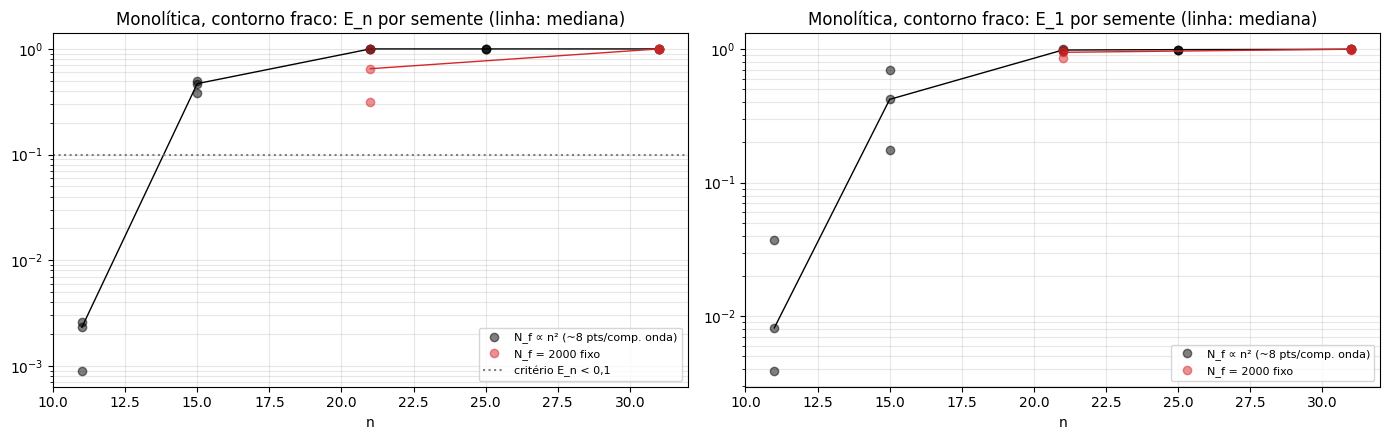

In [41]:
VALORES_N_VARR = [11, 15, 21, 25, 31]
SEMENTES_VARR = [0, 1, 2]
N_FIXO_TAMBEM = (21, 31)


def config_varredura(n, escalar=True):
    N_f = int(round(2000 * (n / 11) ** 2)) if escalar else 2000
    N_b = 4 * int(round(100 * n / 11)) if escalar else 400
    return dict(N_f=N_f, N_b=N_b, N_aval=max(63, 4 * n + 3))


varredura = {}
for n in VALORES_N_VARR:
    prob = criar_problema("P2", n=n)
    for escalar in ([True, False] if n in N_FIXO_TAMBEM else [True]):
        cfg = config_varredura(n, escalar)
        for s in SEMENTES_VARR:
            if n == 11:                                   # mesma configuracao da secao 9
                l = formulacoes["fraco"][s]
                varredura[(n, escalar, s)] = dict(E_n=l["E_n"], E_1=l["E_1"], L2=l["L2"], it=l["hist"]["it_final"],
                                                  plato=l["platô"], tempo=l["tempo"], **cfg)
                continue
            rede, hist, tempo = treinar_pinn(prob, semente=s, imprimir=False, **cfg)
            m = avaliar(rede, prob, cfg["N_aval"])
            varredura[(n, escalar, s)] = dict(E_n=m["E_n"], E_1=m["E_1"], L2=m["L2"], it=hist["it_final"],
                                              plato=hist["platô"], tempo=tempo, **cfg)
        print(f"n = {n:2d}, N_f = {cfg['N_f']:5d}: E_n por semente " +
              ", ".join(f"{varredura[(n, escalar, s)]['E_n']:.3f}" for s in SEMENTES_VARR))

print(f"\n{'n':>3} {'N_f':>6} {'N_b':>5} {'pts/comp. onda':>15} {'E_n mediano':>12} {'E_n máx':>8} {'E_1 mediano':>12} "
      f"{'E_L2 mediano':>13} {'iter. (média)':>14} {'platô':>6} {'tempo médio (s)':>16}")
for n in VALORES_N_VARR:
    for escalar in ([True, False] if n in N_FIXO_TAMBEM else [True]):
        ls = [varredura[(n, escalar, s)] for s in SEMENTES_VARR]
        ppw = 2 * math.sqrt(ls[0]["N_f"]) / n
        print(f"{n:>3} {ls[0]['N_f']:>6} {ls[0]['N_b']:>5} {ppw:15.1f} {np.median([l['E_n'] for l in ls]):12.3f} "
              f"{max(l['E_n'] for l in ls):8.3f} {np.median([l['E_1'] for l in ls]):12.2e} {np.median([l['L2'] for l in ls]):13.2e} "
              f"{np.mean([l['it'] for l in ls]):14.0f} {sum(l['plato'] for l in ls):>4}/{len(ls)} {np.mean([l['tempo'] for l in ls]):16.1f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for j, chave in enumerate(["E_n", "E_1"]):
    for escalar, cor, rot in [(True, "k", "N_f ∝ n² (~8 pts/comp. onda)"), (False, "tab:red", "N_f = 2000 fixo")]:
        ns = [n for n in VALORES_N_VARR if (n, escalar, 0) in varredura]
        for s in SEMENTES_VARR:
            ax[j].semilogy(ns, [varredura[(n, escalar, s)][chave] for n in ns], "o", color=cor, alpha=.5, ms=6,
                           label=rot if s == 0 else None)
        ax[j].semilogy(ns, [np.median([varredura[(n, escalar, s)][chave] for s in SEMENTES_VARR]) for n in ns], "-", color=cor, lw=1)
    if chave == "E_n":
        ax[j].axhline(0.1, color="gray", ls=":", label="critério E_n < 0,1")
    ax[j].set_xlabel("n")
    ax[j].set_title(f"Monolítica, contorno fraco: {chave} por semente (linha: mediana)")
    ax[j].grid(True, which="both", alpha=.3)
    ax[j].legend(fontsize=8)
plt.tight_layout()
plt.show()


**Como ler:**

- **Limiar nesta configuração (rede 4 × 64, 5000 iterações, critério de platô): entre $n = 11$ e $n = 15$**, com ~8 pontos por comprimento de onda em todo $n$:
  - $n = 11$ acerta nas 3 sementes ($E_n \le 0{,}003$, $E_1 \le 0{,}04$);
  - $n = 15$ falha nas 3 ($E_n$ de 0,38 a 0,50);
  - de $n = 21$ em diante, $E_n = 1{,}00$ em todas as sementes, e $\mathcal{E}_{L^2} \approx 0{,}99$.

  Com a grade ($n = 13$: $E_n \approx 0{,}10$), o limiar fica em $n \approx 13$. **É um limiar desta rede, deste orçamento e deste critério de parada, e não um limiar intrínseco do problema.**
- **Acima do limiar, os dois modos se perdem. Isso não é *spectral bias* no sentido clássico.**
  - *Spectral bias* (Rahaman et al.) é aprender o modo baixo e errar o alto: $E_1$ pequeno, $E_n$ grande.
  - Aqui, em $n = 13$, a monolítica tem $E_1 \approx 0{,}18$, **maior** que $E_n \approx 0{,}10$. Em $n = 15$, $E_1 \approx 0{,}42$ e $E_n \approx 0{,}47$. Em $n \ge 21$, $E_1 \approx E_n \approx 1$: a rede fica em $u \approx 0$.
- **O mecanismo mais plausível é a otimização de uma perda mal condicionada, dominada pela fonte de alta frequência:**
  - com $\lambda_{PDE} = 1/\overline{f^2}$ e $\overline{f^2} \propto 1 + \varepsilon^2 n^4$, o peso do modo baixo na perda cai com $n^{-4}$: ele praticamente some da perda;
  - o resíduo $-\nabla^2 u - f$ multiplica o modo $(n, n)$ por $2n^2\pi^2$, então a razão entre as curvaturas da perda nos dois modos cresce com $n^4$.
- **Algumas "falhas" são paradas na solução trivial.** Em $n \ge 21$ com $N_f$ escalado, todas as execuções pararam por platô em 3220 iterações. É a parada mais cedo possível pelo critério (3000 Adam + 11 passos de L-BFGS), com a perda normalizada presa em ~1, o valor de $u \approx 0$. Ali o resultado depende do orçamento e do critério de platô; um orçamento maior sem platô não foi testado.
- **Não é subamostragem.** Com $N_f = 2000$ fixo (4,3 pontos por comprimento de onda), $n = 21$ fica **melhor** que com $N_f = 7289$: $E_n$ mediano 0,65, com uma semente em 0,31. Em $n = 31$, os dois falham.
- **Para a H2**, a pergunta deixa de ser "o XPINN reduz o *spectral bias*?" e passa a ser "o XPINN melhora a otimização acima do limiar da monolítica?". A comparação pareada a seguir testa isso em $n = 13$.

### Comparação pareada em $n = 13$, acima do limiar da monolítica

A varredura e a grade põem o limiar da monolítica (rede 4 × 64, 5000 iterações) em $n \approx 13$. É ali que a H2 pode ser testada: em $n = 11$ a monolítica não falha, e não há o que o XPINN corrigir.

- Monolítica × XPINN $M = 4$ iso-parâmetro, contorno fraco, $\lambda_I$ = `LAM_I`, as mesmas 6 sementes da seção 9, orçamento padrão.
- **Pergunta sobre o mecanismo:** se o XPINN ajudar, $E_1$ melhora **junto** com $E_n$? Uma explicação plausível, que este teste não prova, é de **pré-condicionamento**: em coordenadas locais, cada sub-rede vê a frequência $n/M$ e uma perda menos mal condicionada. Nesse caso os dois modos melhoram juntos, e não só o alto.

In [27]:
prob13 = criar_problema("P2", n=13)
print("Monolítica, contorno fraco")
par13_mono = rodar_sementes(treinar_pinn, prob13, SEMENTES_FORM)
print(f"\nXPINN M=4 iso-par., contorno fraco, lam_I = {LAM_I}")
with DISPOSITIVO_XPINN:
    par13_xpinn = rodar_sementes(treinar_xpinn, prob13, SEMENTES_FORM, M=4, lam_i=LAM_I)

print(f"\n{'semente':>7} {'E_n mono':>9} {'E_n XPINN':>10} {'E_1 mono':>9} {'E_1 XPINN':>10} {'E_L2 mono':>10} {'E_L2 XPINN':>11} {'it mono':>8} {'it XPINN':>9}")
for lm, lx in zip(par13_mono, par13_xpinn):
    print(f"{lm['semente']:>7} {lm['E_n']:9.3f} {lx['E_n']:10.3f} {lm['E_1']:9.2e} {lx['E_1']:10.2e} {lm['L2']:10.2e} {lx['L2']:11.2e} "
          f"{lm['hist']['it_final']:8d} {lx['hist']['it_final']:9d}")

for chave in ["E_n", "E_1", "L2"]:
    print(f"\n[{chave}]  medianas: monolítica {np.median([l[chave] for l in par13_mono]):.2e} | "
          f"XPINN {np.median([l[chave] for l in par13_xpinn]):.2e}")
    comparar_pareado([l[chave] for l in par13_xpinn], [l[chave] for l in par13_mono], "XPINN M=4", "Monolítica")

ambos = sum(lx["E_n"] < lm["E_n"] and lx["E_1"] < lm["E_1"] for lx, lm in zip(par13_xpinn, par13_mono))
print(f"\nSementes em que o XPINN melhora E_n e E_1 ao mesmo tempo: {ambos} de {len(par13_mono)}")


Monolítica, contorno fraco


  semente 0: E_L2 2.43e-01 | E_H1 5.21e-01 | E_n 0.104 | E_1 1.77e-01 | tempo 176.3 s


  semente 1: E_L2 7.39e-01 | E_H1 9.82e-01 | E_n 0.133 | E_1 3.73e-01 | tempo 178.0 s


  semente 2: E_L2 2.46e-02 | E_H1 6.53e-02 | E_n 0.001 | E_1 1.42e-02 | tempo 175.0 s


  semente 3: E_L2 6.72e-01 | E_H1 9.88e-01 | E_n 0.341 | E_1 5.26e-01 | tempo 177.5 s


  semente 4: E_L2 2.16e-01 | E_H1 3.36e-01 | E_n 0.037 | E_1 1.65e-01 | tempo 180.4 s


... (3 outputs left out)

  semente 2: E_L2 3.70e-02 | E_H1 8.29e-02 | E_n 0.008 | E_1 3.45e-02 | tempo 276.8 s


  semente 3: E_L2 3.56e-02 | E_H1 8.75e-02 | E_n 0.001 | E_1 2.51e-02 | tempo 276.7 s


  semente 4: E_L2 3.77e-02 | E_H1 1.06e-01 | E_n 0.015 | E_1 3.20e-02 | tempo 280.8 s


  semente 5: E_L2 1.83e-02 | E_H1 6.44e-02 | E_n 0.005 | E_1 1.84e-03 | tempo 280.0 s

semente  E_n mono  E_n XPINN  E_1 mono  E_1 XPINN  E_L2 mono  E_L2 XPINN  it mono  it XPINN
      0     0.104      0.004  1.77e-01   3.35e-02   2.43e-01    4.10e-02     5000      5000
      1     0.133      0.009  3.73e-01   1.25e-02   7.39e-01    3.27e-02     5000      5000
      2     0.001      0.008  1.42e-02   3.45e-02   2.46e-02    3.70e-02     5000      5000
      3     0.341      0.001  5.26e-01   2.51e-02   6.72e-01    3.56e-02     5000      5000
      4     0.037      0.015  1.65e-01   3.20e-02   2.16e-01    3.77e-02     5000      5000
      5     0.002      0.005  1.04e-02   1.84e-03   1.95e-02    1.83e-02     5000      5000

[E_n]  medianas: monolítica 7.06e-02 | XPINN 6.74e-03
XPINN M=4 / Monolítica: razão geométrica 0.20 (melhor) | XPINN M=4 pior em 2 de 6 sementes
  t pareado em log10: p = 0.207 | Wilcoxon: p = 0.219

[E_1]  medianas: monolítica 1.71e-01 | XPINN 2.85e-02
XPINN M=4 / Mo

**Como ler:**

- **Em $n = 13$, a monolítica tem dois desfechos.** Ela acerta em 2 de 6 sementes ($\mathcal{E}_{L^2}$ de 0,025 e 0,020) e falha nas outras 4 ($\mathcal{E}_{L^2}$ de 0,22 a 0,74). É o que se espera bem em cima do limiar.
- **O XPINN $M = 4$ não falha em nenhuma semente:** $\mathcal{E}_{L^2}$ de 0,018 a 0,041 e $E_n \le 0{,}015$.

| Métrica | Razão XPINN/monolítica | XPINN pior em | $t$ pareado | Wilcoxon |
|---|---|---|---|---|
| $\mathcal{E}_{L^2}$ | 0,21 | 1 de 6 | 0,048 | 0,094 |
| $E_1$ | 0,17 | 1 de 6 | 0,035 | 0,0625 |
| $E_n$ | 0,20 | 2 de 6 | 0,21 | 0,22 |

- **Não é significativo pelo Wilcoxon** (mínimo possível 0,031 com 6 pares). Com três métricas, o $t$ pareado também não passa por Bonferroni ($0{,}05/3 \approx 0{,}017$). É uma **indicação forte, não uma demonstração**. Com 10 sementes, o mínimo do Wilcoxon cai para 0,002.
- **$E_1$ melhora junto com $E_n$.**
  - Nas 4 sementes em que a monolítica falha, o XPINN melhora os dois modos ao mesmo tempo, e o modo **baixo** é o que mais melhora: $E_1$ cai de 0,17–0,53 para 0,013–0,034.
  - Nas 2 sementes em que a monolítica acerta, o XPINN fica parecido ($\mathcal{E}_{L^2}$ 0,037 contra 0,025 e 0,018 contra 0,020).
  - Nas 4 falhas da monolítica, $E_1 > E_n$: ela perde mais o modo baixo que o alto. De novo, não é *spectral bias*.
- **Assimetria de ajuste.** O XPINN recebeu um hiperparâmetro ajustado ($\lambda_I$, nas sementes 10 a 12), e a monolítica nenhum. Como a falha da monolítica é de otimização, um revisor pode perguntar se ela só não foi ajustada. O teste confirmatório logo abaixo fecha isso: a monolítica recebe 4 candidatos de $\lambda_{BC}$ nas mesmas sementes, e $n = 13$ e $n = 15$ são repetidos com 10 sementes novas.
- **Dispositivo.** O "4 de 6" é da monolítica na GPU. Bem em cima do limiar, outro dispositivo muda a trajetória e pode trocar quais sementes acertam. A comparação vale para a distribuição do erro, e não semente a semente.
- **Leitura para a H2 reformulada:** acima do limiar da monolítica, o XPINN evitou a falha de otimização nas 6 sementes e ganhou nos dois modos. Isso é compatível com o pré-condicionamento (cada sub-rede vê a frequência local $n/M$), mas este teste não isola o mecanismo. O resultado confirmatório está abaixo.
- **Custo:** o XPINN levou ~270 s por execução em CPU, contra ~178 s da monolítica na GPU. São dispositivos diferentes, então isso não é uma comparação de velocidade entre arquiteturas.


### Teste confirmatório da H2 (protocolo fixado antes de rodar)

A comparação em $n = 13$ acima é **exploratória**: foi olhando para as sementes 0 a 5 que surgiu a hipótese. Esta parte é o teste que a confirma ou não. Tudo abaixo foi escrito **antes** de lançar as execuções, e o resultado vai para o texto como sair, sem leitura a posteriori.

**Simetria de ajuste.** O XPINN recebeu um peso da perda ajustado ($\lambda_I$). A monolítica recebe o mesmo tratamento no único peso da perda que ela tem, $\lambda_{BC}$:
- candidatos $\lambda_{BC} \in \{0{,}1;\ 0{,}3;\ 1;\ 3\}$ (inclui o 1 atual, como o $\lambda_I$ incluía);
- P2(11), sementes 10 a 12 (as mesmas da escolha de $\lambda_I$), orçamento fixo;
- critério: menor média geométrica de $\mathcal{E}_{L^2}$. Se o escolhido for 1, a monolítica ajustada é a própria monolítica padrão.
- A taxa de aprendizado **não** é ajustada: ela vale para as duas arquiteturas, e ajustá-la só na monolítica criaria uma assimetria a favor dela.
- $\lambda_I = 0{,}03$ e $\lambda_{BC}$ ficam fixos nos valores escolhidos em $n = 11$; não são reajustados em $n = 13$ e $n = 15$.

**Execuções.**
- $n \in \{13, 15\}$, **sementes novas 20 a 29** nas duas arquiteturas. As sementes 0 a 5 de $n = 13$ geraram a hipótese e ficam como resultado exploratório; as 10 a 12 foram usadas nos ajustes.
- **Orçamento fixo: 3000 Adam + 100 passos de L-BFGS = 5000 iterações, sem critério de platô**, em todas as execuções. Isso evita as paradas na solução trivial da varredura e define a regra de reaproveitamento: só uma execução que foi até 5000 iterações sem platô é igual, bit a bit, a uma de orçamento fixo.
- $n = 13$: $N_f = 2000$ e $N_b = 400$ (~7 pontos por comprimento de onda, suficiente pela varredura). $n = 15$: $N_f = 3719$ e $N_b = 544$ (~8 pontos), como na varredura, para não misturar subamostragem com arquitetura. As duas arquiteturas usam os mesmos pontos.
- Monolítica (padrão e ajustada) na GPU; XPINN $M = 4$ iso-parâmetro em CPU. As execuções rodam em processos separados, ao mesmo tempo (GPU e CPU), cada uma presa a um núcleo físico. **Só acurácia:** execuções simultâneas disputam memória, e os tempos delas não entram em nenhuma conta de speedup.

**Teste principal, um por $n$.**
- Comparação: **XPINN $M = 4$ contra a monolítica ajustada.** A monolítica padrão entra só como referência.
- Métrica: $\mathcal{E}_{L^2}$. Estatística: **Wilcoxon pareado bilateral** sobre $d_s = \log_{10}\mathcal{E}^{\text{XPINN}}_s - \log_{10}\mathcal{E}^{\text{mono aj.}}_s$, 10 sementes (menor $p$ possível: 0,002).
- Correção: dois testes ($n = 13$ e $n = 15$), então **$\alpha = 0{,}025$ em cada**.
- **Sentido do resultado pelo estimador de Hodges–Lehmann** de $d$ (mediana das médias de Walsh), a mesma família do Wilcoxon, e não pela média geométrica.
- Desfechos, por $n$:
  - $p < 0{,}025$ e Hodges–Lehmann $< 0$: **H2 confirmada** naquele $n$;
  - $p < 0{,}025$ e Hodges–Lehmann $> 0$: **H2 refutada** naquele $n$ (a monolítica ajustada é melhor);
  - $p \ge 0{,}025$: **sem diferença detectável** (não quer dizer "equivalentes").
- Os dois $n$ são reportados separadamente. Por exemplo, "confirmada em $n = 13$, sem diferença em $n = 15$" é reportado assim mesmo.

**Apoio (não decide sozinho):** $E_1$ e $E_n$ (Wilcoxon e Hodges–Lehmann, sem correção) e a **taxa de falha**, com falha definida antes como $\mathcal{E}_{L^2} > 0{,}1$ **ou** $E_n > 0{,}5$. O segundo critério fecha o caso de acertar o modo baixo e ignorar o alto, que dá $\mathcal{E}_{L^2} \approx 0{,}0995$ e passaria pelo primeiro.

### Teste da ordem das somas (DDP melhor que o sequencial, seção 10)

Hipótese da seção 10: o DDP fica um pouco melhor porque soma o resíduo em pedaços, com menos erro de arredondamento em `float32`. Teste: o **sequencial em `float64`**, P1, sementes 0 a 19, orçamento fixo de 5000 iterações, em CPU com 1 thread. **Mesmos pontos de colocação e de contorno e mesma inicialização** do sequencial em `float32` (a rede e os pontos são gerados em `float32` e convertidos; esses valores são exatos em `float64`): só a aritmética muda. O DDP e o sequencial em `float32` são os da seção 10, lidos dos arquivos `.json`.

Leitura fixada antes (Wilcoxon bilateral, $\alpha = 0{,}05$; é uma explicação, e não uma hipótese do TCC):
- **Efeito numérico sustentado** se o `float64` for melhor que o `float32` ($p < 0{,}05$, Hodges–Lehmann $< 0$) **e** o IC 90% da razão DDP $p = 4$ / sequencial `float64` contiver 1.
- **A precisão não explica** se o `float64` não diferir do `float32` ($p \ge 0{,}05$).
- Qualquer outro caso é descrito como está, sem forçar uma das duas leituras.

Estas execuções rodam na fila de CPU, nos núcleos livres, ao mesmo tempo que a monolítica ocupa a GPU.


In [17]:
TAREFA_SCRIPT = r"""# Gerado automaticamente a partir do notebook. Nao editar a mao.
# Um treino (monolitica ou XPINN) num processo proprio, com o resultado num .json (secao 13, teste confirmatorio).
import json
import math
import os
import sys
import warnings

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch

cfg = json.loads(sys.argv[1])
saida = sys.argv[2]
torch.set_num_threads(1)
torch.set_default_device(cfg["dispositivo"])
torch.use_deterministic_algorithms(True, warn_only=True)     # mesma configuracao do notebook
avisos = set()


def _aviso(message, category, filename, lineno, file=None, line=None):
    avisos.add(str(message).split("\n")[0][:300])


warnings.showwarning = _aviso

import pinn_comum as pc

if cfg["float64"]:
    # Pontos, rede (inicializacao) e grade de avaliacao gerados em float32 e convertidos: os valores float32 sao exatos
    # em float64. Assim o treino em float64 tem os mesmos pontos e os mesmos pesos iniciais; so a aritmetica muda.
    torch.set_default_dtype(torch.float64)

    def em_float32(funcao):
        def envolvida(*a, **k):
            torch.set_default_dtype(torch.float32)
            try:
                r = funcao(*a, **k)
            finally:
                torch.set_default_dtype(torch.float64)
            return tuple(t.double() for t in r) if isinstance(r, tuple) else r.double()
        return envolvida

    for nome in ("pontos_colocacao", "pontos_contorno", "criar_rede", "grade_interior"):
        setattr(pc, nome, em_float32(getattr(pc, nome)))

prob = pc.criar_problema(cfg["problema"], n=cfg["n"])
kw = dict(semente=cfg["semente"], N_f=cfg["N_f"], N_b=cfg["N_b"], lam_bc=cfg["lam_bc"], epocas_adam=cfg["epocas_adam"],
          passos_lbfgs_max=cfg["passos_lbfgs"], imprimir=False)
if cfg["sem_plato"]:
    kw["tolerancia_plato"] = -math.inf
if cfg["M"] > 0:
    from pinn_xpinn import treinar_xpinn          # gerado na secao 11
    rede, hist, tempo = treinar_xpinn(prob, M=cfg["M"], lam_i=cfg["lam_i"], **kw)
else:
    rede, hist, tempo = pc.treinar_pinn(prob, **kw)
m = pc.avaliar(rede, prob)
metricas = {k: float(v) for k, v in m.items() if k in ("L2", "H1", "PDE", "E_n", "E_1", "E_esp")}
with open(saida, "w") as arquivo:
    json.dump({"cfg": cfg, "metricas": metricas, "it_final": hist["it_final"], "plato": bool(hist["platô"]),
               "tempo": tempo, "dtype": str(next(rede.parameters()).dtype), "avisos": sorted(avisos)}, arquivo)
"""

with open("tarefa_pinn.py", "w", encoding="utf-8") as arquivo:
    arquivo.write(TAREFA_SCRIPT)

PADRAO_TAREFA = dict(problema="P2", n=None, semente=0, N_f=2000, N_b=400, lam_bc=1.0, M=0, lam_i=1.0,
                     epocas_adam=3000, passos_lbfgs=100, sem_plato=True, float64=False, dispositivo="cpu")


def arquivo_tarefa(cfg):
    # Nome a partir das opcoes que diferem do padrao: a mesma configuracao sempre cai no mesmo arquivo (retomada)
    partes = [f"{k}{cfg[k]}" for k in sorted(cfg) if k in ("problema", "semente", "dispositivo") or cfg[k] != PADRAO_TAREFA[k]]
    return "tarefa_" + "_".join(partes).replace(".", "p") + ".json"


def rodar_fila(tarefas, nucleos_cpu=(2, 4, 6, 8, 10), nucleo_gpu=0, reaproveitar=True):
    # GPU: uma tarefa por vez, presa ao nucleo fisico 0. CPU: uma tarefa por nucleo fisico livre (1 thread cada).
    # So ACURACIA: tarefas simultaneas disputam memoria, entao os tempos delas nao entram em contas de speedup.
    # reaproveitar: se o .json ja existe, nao roda de novo (retomada depois de uma interrupcao).
    cfgs = [dict(PADRAO_TAREFA, **t) for t in tarefas]
    fila = {"cuda": [], "cpu": []}
    for i, c in enumerate(cfgs):
        if not (reaproveitar and os.path.exists(arquivo_tarefa(c))):
            fila[c["dispositivo"]].append(i)
    livres, ativos, t0 = {"cuda": [nucleo_gpu], "cpu": list(nucleos_cpu)}, [], time.time()
    novas = sum(len(v) for v in fila.values())
    try:
        while any(fila.values()) or ativos:
            for d in ("cuda", "cpu"):
                while fila[d] and livres[d]:
                    i, nucleo = fila[d].pop(0), livres[d].pop(0)
                    saida = arquivo_tarefa(cfgs[i])
                    ambiente = dict(os.environ, OMP_NUM_THREADS="1", MKL_NUM_THREADS="1")
                    if d == "cpu":
                        ambiente["CUDA_VISIBLE_DEVICES"] = ""
                    log = open(saida + ".log", "w")
                    proc = subprocess.Popen([sys.executable, "tarefa_pinn.py", json.dumps(cfgs[i]), saida],
                                            env=ambiente, stdout=log, stderr=log)
                    psutil.Process(proc.pid).cpu_affinity([nucleo])
                    ativos.append((i, proc, log, nucleo, d))
            time.sleep(1)
            for a in [a for a in ativos if a[1].poll() is not None]:
                i, proc, log, nucleo, d = a
                ativos.remove(a)
                log.close()
                livres[d].append(nucleo)
                saida = arquivo_tarefa(cfgs[i])
                if proc.returncode != 0:
                    with open(saida + ".log") as arquivo:
                        print(arquivo.read()[-3000:])
                    raise RuntimeError(f"tarefa falhou: {saida}")
                os.remove(saida + ".log")
    finally:
        for _, proc, log, _, _ in ativos:         # numa falha (ou interrupcao), nao deixa processos soltos
            proc.kill()
            proc.wait()
            log.close()
    if novas:
        print(f"{novas} execuções novas, {len(cfgs) - novas} reaproveitadas | {(time.time() - t0) / 60:.1f} min")
    resultados = []
    for c in cfgs:
        with open(arquivo_tarefa(c)) as arquivo:
            resultados.append(json.load(arquivo))
    return resultados


# Teste do lancamento (orcamento minimo, 20 Adam + 1 passo de L-BFGS): o processo separado reproduz o notebook?
CURTO_T = dict(epocas_adam=20, passos_lbfgs=1)
prob = criar_problema("P2", n=11)
r_gpu, r_xp, r_32, r_64 = rodar_fila([dict(n=11, dispositivo=DISPOSITIVO, **CURTO_T),
                                      dict(n=11, M=4, lam_i=LAM_I, **CURTO_T),
                                      dict(problema="P1", **CURTO_T), dict(problema="P1", float64=True, **CURTO_T)],
                                     reaproveitar=False)
rede, _, _ = treinar_pinn(prob, epocas_adam=20, passos_lbfgs_max=1, tolerancia_plato=-math.inf, imprimir=False)
l2_nb = avaliar(rede, prob)["L2"]
with torch.device("cpu"):
    rede, _, _ = treinar_xpinn(prob, M=4, lam_i=LAM_I, epocas_adam=20, passos_lbfgs_max=1, tolerancia_plato=-math.inf,
                               imprimir=False)
    l2_xp_nb = avaliar(rede, prob)["L2"]
r_ddp = rodar_ddp("P1", p=1, epocas_adam=20, passos_lbfgs=1, sem_plato=True, reaproveitar=False)
print(f"Monolítica GPU: processo {r_gpu['metricas']['L2']:.6e} | notebook {l2_nb:.6e} | iguais: {r_gpu['metricas']['L2'] == l2_nb}")
print(f"XPINN CPU:      processo {r_xp['metricas']['L2']:.6e} | notebook {l2_xp_nb:.6e} | iguais: {r_xp['metricas']['L2'] == l2_xp_nb}")
print(f"P1 float32 CPU: processo {r_32['metricas']['L2']:.6e} | ddp_pinn.py --sequencial {r_ddp['metricas']['L2']:.6e} | "
      f"iguais: {r_32['metricas']['L2'] == r_ddp['metricas']['L2']}")
print(f"P1 float64 CPU: processo {r_64['metricas']['L2']:.6e} | parâmetros em {r_64['dtype']}")


4 execuções novas, 0 reaproveitadas | 0.4 min


Monolítica GPU: processo 9.684724e-01 | notebook 9.684724e-01 | iguais: True
XPINN CPU:      processo 7.721860e-01 | notebook 7.721860e-01 | iguais: True
P1 float32 CPU: processo 1.163962e-01 | ddp_pinn.py --sequencial 1.163962e-01 | iguais: True
P1 float64 CPU: processo 1.163963e-01 | parâmetros em torch.float64


In [18]:
LAM_BC_CANDIDATOS = [0.1, 0.3, 1.0, 3.0]
SEMENTES_LAM_BC = [10, 11, 12]                 # as mesmas da escolha de lam_I
SEMENTES_H2 = list(range(20, 30))              # novas: as sementes 0-5 de n = 13 geraram a hipotese
VALORES_N_H2 = [13, 15]
ORCAMENTO_H2 = dict(epocas_adam=3000, passos_lbfgs=100, sem_plato=True)   # 5000 iteracoes, sem plato
SEMENTES_ORDEM = list(range(20))               # teste da ordem das somas: as mesmas sementes do DDP (secao 10)


def config_h2(n):
    # n = 13: N_f = 2000 (~7 pontos por comprimento de onda). n = 15: escalado como na varredura (~8)
    if n <= 13:
        return dict(N_f=2000, N_b=400)
    return dict(N_f=int(round(2000 * (n / 11) ** 2)), N_b=4 * int(round(100 * n / 11)))


# Primeira fila: escolha de lam_BC e monolitica padrao (GPU); XPINN e sequencial em float64 (CPU), ao mesmo tempo
t_escolha = [dict(n=11, semente=s, lam_bc=l, dispositivo=DISPOSITIVO, **ORCAMENTO_H2)
             for l in LAM_BC_CANDIDATOS for s in SEMENTES_LAM_BC]
t_padrao = [dict(n=n, semente=s, dispositivo=DISPOSITIVO, **config_h2(n), **ORCAMENTO_H2)
            for n in VALORES_N_H2 for s in SEMENTES_H2]
t_xpinn = [dict(n=n, semente=s, M=4, lam_i=LAM_I, **config_h2(n), **ORCAMENTO_H2) for n in VALORES_N_H2 for s in SEMENTES_H2]
t_f64 = [dict(problema="P1", semente=s, float64=True, **ORCAMENTO_H2) for s in SEMENTES_ORDEM]
r = rodar_fila(t_escolha + t_padrao + t_xpinn + t_f64)
r_escolha, r = r[:len(t_escolha)], r[len(t_escolha):]
r_padrao, r = r[:len(t_padrao)], r[len(t_padrao):]
r_xpinn, r_f64 = r[:len(t_xpinn)], r[len(t_xpinn):]

geom = lambda v: 10**np.mean(np.log10(v))
print(f"\n{'lam_BC':>7} {'E_L2 geom.':>11} {'E_L2 máx':>9} {'E_n geom.':>10} {'E_1 geom.':>10}")
escolha_bc = {}
for l in LAM_BC_CANDIDATOS:
    ms = [x["metricas"] for x in r_escolha if x["cfg"]["lam_bc"] == l]
    escolha_bc[l] = geom([m["L2"] for m in ms])
    print(f"{l:7.2f} {escolha_bc[l]:11.2e} {max(m['L2'] for m in ms):9.2e} {geom([m['E_n'] for m in ms]):10.3f} "
          f"{geom([m['E_1'] for m in ms]):10.2e}")
LAM_BC = min(escolha_bc, key=escolha_bc.get)
print(f"\nEscolhido pelo critério fixado antes (menor E_L2 geométrico nas sementes 10-12): LAM_BC = {LAM_BC}")
print("Iterações finais (todas devem ser 5000):", sorted({x["it_final"] for x in r_escolha + r_padrao + r_xpinn + r_f64}))


72 execuções novas, 0 reaproveitadas | 231.1 min



 lam_BC  E_L2 geom.  E_L2 máx  E_n geom.  E_1 geom.
   0.10    7.91e-03  1.04e-02      0.008   1.72e-03
   0.30    6.46e-03  1.10e-02      0.007   2.57e-03
   1.00    5.28e-03  8.90e-03      0.002   1.66e-03
   3.00    1.09e-02  1.68e-02      0.002   6.10e-03

Escolhido pelo critério fixado antes (menor E_L2 geométrico nas sementes 10-12): LAM_BC = 1.0
Iterações finais (todas devem ser 5000): [5000]


In [19]:
# Monolitica ajustada (lam_BC escolhido). Se LAM_BC = 1, os arquivos sao os da monolitica padrao e nada roda de novo.
r_ajustada = rodar_fila([dict(n=n, semente=s, lam_bc=LAM_BC, dispositivo=DISPOSITIVO, **config_h2(n), **ORCAMENTO_H2)
                         for n in VALORES_N_H2 for s in SEMENTES_H2])
print(f"Monolítica ajustada: lam_BC = {LAM_BC}" + (" (a própria monolítica padrão)" if LAM_BC == 1.0 else ""))


Monolítica ajustada: lam_BC = 1.0 (a própria monolítica padrão)


=== n = 13 (N_f = 2000, N_b = 400), sementes 20-29, lam_BC = 1.0, lam_I = 0.03
semente | E_L2 padrão E_L2 ajust.  E_L2 XPINN | E_n ajust.  E_n XPINN | E_1 ajust.  E_1 XPINN | falha (pad/aju/XP)
     20 |    4.13e-01    4.13e-01    3.07e-02 |      0.247      0.004 |   1.06e-01   2.66e-02 | x/x/.
     21 |    5.49e-02    5.49e-02    1.71e-02 |      0.001      0.004 |   4.50e-02   2.96e-03 | ././.
     22 |    7.30e-02    7.30e-02    2.97e-01 |      0.006      0.016 |   6.31e-02   2.72e-01 | ././x
     23 |    7.49e-01    7.49e-01    2.40e-02 |      0.256      0.003 |   7.04e-01   1.85e-02 | x/x/.
     24 |    3.90e-01    3.90e-01    4.50e-02 |      0.297      0.011 |   2.46e-01   3.75e-02 | x/x/.
     25 |    1.04e+00    1.04e+00    3.53e-02 |      0.339      0.009 |   9.42e-01   3.01e-02 | x/x/.
     26 |    5.20e-02    5.20e-02    2.01e-02 |      0.000      0.004 |   1.73e-02   2.07e-03 | ././.
     27 |    4.50e-02    4.50e-02    1.84e-02 |      0.001      0.015 |   1.89e-02   6.61e-0


TESTE PRINCIPAL (E_L2, XPINN / monolítica ajustada): Hodges-Lehmann 0.189 | XPINN pior em 2 de 10 | Wilcoxon bilateral p = 0.0645 (alfa = 0.025) -> sem diferença detectável
Apoio (sem correção, não decide):
  E_1: Hodges-Lehmann 0.152 | XPINN pior em 2 de 10 | Wilcoxon p = 0.0645
  E_n: Hodges-Lehmann 0.311 | XPINN pior em 5 de 10 | Wilcoxon p = 0.492
  E_L2 contra a monolítica padrão (referência): Hodges-Lehmann 0.189 | Wilcoxon p = 0.0645
  Falhas (E_L2 > 0,1 ou E_n > 0,5): padrão 5/10 | ajustada 5/10 | XPINN 2/10

=== n = 15 (N_f = 3719, N_b = 544), sementes 20-29, lam_BC = 1.0, lam_I = 0.03
semente | E_L2 padrão E_L2 ajust.  E_L2 XPINN | E_n ajust.  E_n XPINN | E_1 ajust.  E_1 XPINN | falha (pad/aju/XP)
     20 |    1.36e-01    1.36e-01    1.73e-02 |      0.036      0.000 |   1.47e-02   1.01e-02 | x/x/.
     21 |    6.09e-01    6.09e-01    2.41e-02 |      0.343      0.005 |   5.48e-01   1.35e-02 | x/x/.
     22 |    8.71e-01    8.71e-01    1.50e-02 |      0.490      0.010 |   8.58

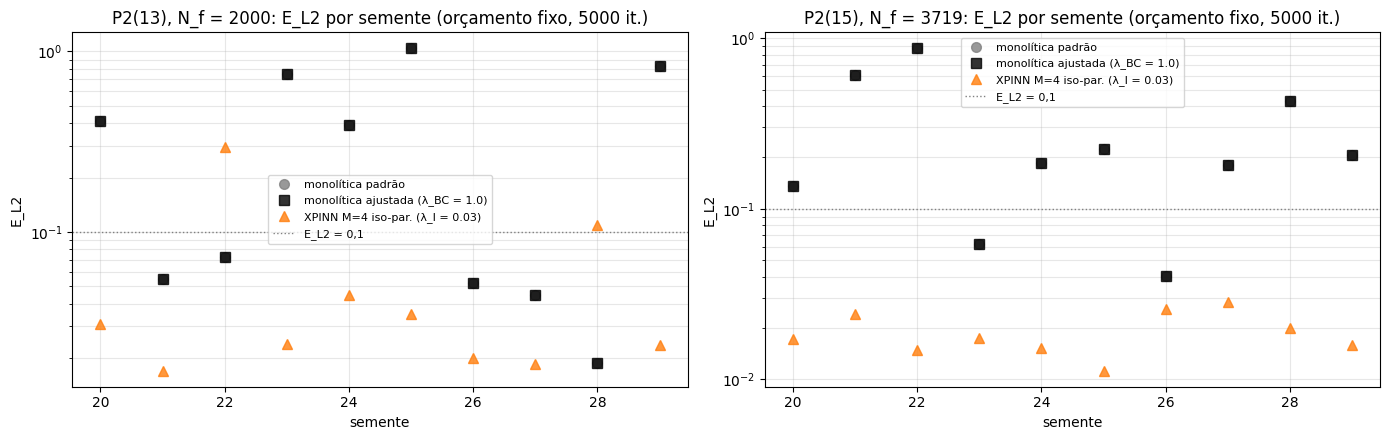

Avisos de operação sem versão determinística nos processos: nenhum


In [20]:
def hodges_lehmann(d):
    # Mediana das medias de Walsh: o estimador de posicao associado ao Wilcoxon
    d = np.asarray(d)
    return float(np.median([(d[i] + d[j]) / 2 for i in range(len(d)) for j in range(i, len(d))]))


def falhou(m):
    return m["L2"] > 0.1 or m["E_n"] > 0.5            # definicao fixada antes


ALFA_H2 = 0.05 / len(VALORES_N_H2)                    # Bonferroni: dois testes
por_n = lambda lista, n: [x["metricas"] for x in lista if x["cfg"]["n"] == n]
avisos = sorted({a for x in r_escolha + r_padrao + r_xpinn + r_ajustada + r_f64 for a in x["avisos"]})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for j, n in enumerate(VALORES_N_H2):
    pad, aju, xp = por_n(r_padrao, n), por_n(r_ajustada, n), por_n(r_xpinn, n)
    cfg = config_h2(n)
    print(f"=== n = {n} (N_f = {cfg['N_f']}, N_b = {cfg['N_b']}), sementes {SEMENTES_H2[0]}-{SEMENTES_H2[-1]}, lam_BC = {LAM_BC}, lam_I = {LAM_I}")
    print(f"{'semente':>7} | {'E_L2 padrão':>11} {'E_L2 ajust.':>11} {'E_L2 XPINN':>11} | {'E_n ajust.':>10} {'E_n XPINN':>10} | "
          f"{'E_1 ajust.':>10} {'E_1 XPINN':>10} | falha (pad/aju/XP)")
    for s, a, b, c in zip(SEMENTES_H2, pad, aju, xp):
        print(f"{s:>7} | {a['L2']:11.2e} {b['L2']:11.2e} {c['L2']:11.2e} | {b['E_n']:10.3f} {c['E_n']:10.3f} | "
              f"{b['E_1']:10.2e} {c['E_1']:10.2e} | {'x' if falhou(a) else '.'}/{'x' if falhou(b) else '.'}/{'x' if falhou(c) else '.'}")
    d = np.log10([c["L2"] for c in xp]) - np.log10([b["L2"] for b in aju])
    p = stats.wilcoxon(d).pvalue
    hl = hodges_lehmann(d)
    desfecho = ("H2 CONFIRMADA" if hl < 0 else "H2 REFUTADA (monolítica ajustada melhor)") if p < ALFA_H2 else "sem diferença detectável"
    print(f"\nTESTE PRINCIPAL (E_L2, XPINN / monolítica ajustada): Hodges-Lehmann {10**hl:.3f} | "
          f"XPINN pior em {np.sum(d > 0)} de {len(d)} | Wilcoxon bilateral p = {p:.3g} (alfa = {ALFA_H2}) -> {desfecho}")
    print("Apoio (sem correção, não decide):")
    for k in ("E_1", "E_n"):
        dk = np.log10([c[k] for c in xp]) - np.log10([b[k] for b in aju])
        print(f"  {k}: Hodges-Lehmann {10**hodges_lehmann(dk):.3f} | XPINN pior em {np.sum(dk > 0)} de {len(dk)} | "
              f"Wilcoxon p = {stats.wilcoxon(dk).pvalue:.3g}")
    dp = np.log10([c["L2"] for c in xp]) - np.log10([a["L2"] for a in pad])
    print(f"  E_L2 contra a monolítica padrão (referência): Hodges-Lehmann {10**hodges_lehmann(dp):.3f} | "
          f"Wilcoxon p = {stats.wilcoxon(dp).pvalue:.3g}")
    print(f"  Falhas (E_L2 > 0,1 ou E_n > 0,5): padrão {sum(map(falhou, pad))}/{len(pad)} | ajustada {sum(map(falhou, aju))}/{len(aju)} | "
          f"XPINN {sum(map(falhou, xp))}/{len(xp)}\n")
    for lista, cor, mk, rot in [(pad, "gray", "o", "monolítica padrão"), (aju, "k", "s", f"monolítica ajustada (λ_BC = {LAM_BC})"),
                                (xp, "tab:orange", "^", f"XPINN M=4 iso-par. (λ_I = {LAM_I})")]:
        ax[j].semilogy(SEMENTES_H2, [m["L2"] for m in lista], mk, color=cor, label=rot, ms=7, alpha=.8)
    ax[j].axhline(0.1, color="gray", ls=":", lw=1, label="E_L2 = 0,1")
    ax[j].set_xlabel("semente")
    ax[j].set_ylabel("E_L2")
    ax[j].set_title(f"P2({n}), N_f = {cfg['N_f']}: E_L2 por semente (orçamento fixo, 5000 it.)")
    ax[j].grid(True, which="both", alpha=.3)
    ax[j].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Avisos de operação sem versão determinística nos processos:", avisos if avisos else "nenhum")


**Como ler:**

**Ajuste da monolítica.** O critério fixado antes escolheu $\lambda_{BC} = 1$, o valor que já era usado:

| $\lambda_{BC}$ | 0,1 | 0,3 | **1** | 3 |
|---|---|---|---|---|
| $\mathcal{E}_{L^2}$ geom. (P2(11), sementes 10 a 12) | $7{,}9 \times 10^{-3}$ | $6{,}5 \times 10^{-3}$ | $\mathbf{5{,}3 \times 10^{-3}}$ | $1{,}1 \times 10^{-2}$ |

A monolítica ajustada é a própria monolítica padrão, e a assimetria de ajuste fica fechada para o peso da perda: entre os candidatos, a monolítica já estava no melhor. Todas as execuções chegaram a 5000 iterações.

**Teste principal** ($\mathcal{E}_{L^2}$, XPINN $M = 4$ contra a monolítica ajustada, sementes 20 a 29, $\alpha = 0{,}025$ por $n$):

| | Hodges–Lehmann (razão) | XPINN pior em | Wilcoxon $p$ | Desfecho | Falhas mono / XPINN |
|---|---|---|---|---|---|
| $n = 13$ | 0,19 | 2 de 10 | 0,065 | **sem diferença detectável** | 5 / 2 de 10 |
| $n = 15$ | 0,082 | 0 de 10 | 0,0020 | **H2 confirmada** | 8 / 0 de 10 |

- **$n = 15$: H2 confirmada.** O XPINN é melhor nas 10 sementes, com $\mathcal{E}_{L^2}$ ~12 vezes menor pelo Hodges–Lehmann, e $p = 0{,}002$ é o menor valor possível com 10 pares. O XPINN não falha em nenhuma semente ($\mathcal{E}_{L^2}$ de 0,011 a 0,028); a monolítica falha em 8. $E_1$ (0,068; $p = 0{,}002$) e $E_n$ (0,097; $p = 0{,}014$) vão no mesmo sentido.
- **$n = 13$: sem diferença detectável.** O sentido é o mesmo (Hodges–Lehmann 0,19, ~5 vezes melhor, o mesmo tamanho do exploratório), mas $p = 0{,}065$ não passa de 0,025. O motivo está na tabela: em $n = 13$ a monolítica **acerta em metade das sementes**, e o XPINN falha em 2 (sementes 22 e 28, $\mathcal{E}_{L^2}$ de 0,30 e 0,11, com $E_n$ pequeno: erro no modo baixo). Nas 5 sementes em que a monolítica acerta, o XPINN ganha em 3 (~2,5 vezes) e perde nessas 2. Isso **não** quer dizer que as arquiteturas sejam equivalentes em $n = 13$.
- **Taxa de falha** (critério fixado antes): monolítica 5 de 10 em $n = 13$ e 8 de 10 em $n = 15$; XPINN 2 de 10 e 0 de 10. A falha da monolítica cresce com $n$, como na varredura; a do XPINN não.
- **O XPINN também falha**, e falha no modo baixo ($E_1 \gg E_n$ nas sementes 22 e 28 de $n = 13$). O resultado não é "o XPINN nunca falha", e sim "acima do limiar, falha bem menos".
- **Leitura para a H2 reformulada:** confirmada em $n = 15$; em $n = 13$, bem em cima do limiar, o efeito tem o mesmo sentido e tamanho, mas 10 sementes não bastam para distinguir do acaso. O teste continua sem isolar o mecanismo (pré-condicionamento pela frequência local $n/M$).
- **Limites:** a taxa de aprendizado não foi ajustada em nenhuma das duas arquiteturas (fixado antes); a monolítica roda na GPU e o XPINN em CPU (vale a distribuição do erro, e não a semente a semente; em $n = 15$, a verificação no fim desta seção repete a monolítica em CPU); um orçamento fixo de 5000 iterações.


In [21]:
# Sequencial float32, DDP p = 2 e p = 4: os da secao 10 (arquivos .json; nada roda de novo)
l2_32 = [rodar_ddp("P1", p=1, semente=s, sem_plato=True)["metricas"]["L2"] for s in SEMENTES_ORDEM]
l2_ddp = {p: [rodar_ddp("P1", p=p, semente=s, sem_plato=True)["metricas"]["L2"] for s in SEMENTES_ORDEM] for p in (2, 4)}
l2_64 = [x["metricas"]["L2"] for x in r_f64]

print(f"{'semente':>7} {'seq. float32':>13} {'seq. float64':>13} {'DDP p=2':>10} {'DDP p=4':>10}")
for i, s in enumerate(SEMENTES_ORDEM):
    print(f"{s:>7} {l2_32[i]:13.2e} {l2_64[i]:13.2e} {l2_ddp[2][i]:10.2e} {l2_ddp[4][i]:10.2e}")


def comparar_ordem(a, b, rotulo):
    d = np.log10(a) - np.log10(b)
    meia = stats.t.ppf(0.95, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    p = stats.wilcoxon(d).pvalue
    print(f"{rotulo:>32}: razão geom. {10**d.mean():.3f} | IC 90% [{10**(d.mean() - meia):.3f}, {10**(d.mean() + meia):.3f}] | "
          f"Hodges-Lehmann {10**hodges_lehmann(d):.3f} | Wilcoxon p = {p:.3g}")
    return d, (10**(d.mean() - meia), 10**(d.mean() + meia)), p


print()
d_prec, _, p_prec = comparar_ordem(l2_64, l2_32, "float64 / float32 (sequencial)")
_, ic_4, _ = comparar_ordem(l2_ddp[4], l2_64, "DDP p=4 / sequencial float64")
comparar_ordem(l2_ddp[2], l2_64, "DDP p=2 / sequencial float64")
comparar_ordem(l2_ddp[4], l2_32, "DDP p=4 / sequencial float32")
comparar_ordem(l2_ddp[2], l2_32, "DDP p=2 / sequencial float32")
if p_prec < 0.05 and hodges_lehmann(d_prec) < 0 and ic_4[0] <= 1 <= ic_4[1]:
    leitura = "efeito numérico sustentado: o float64 alcança o DDP"
elif p_prec >= 0.05:
    leitura = "a precisão não explica: o float64 não difere do float32"
else:
    leitura = "outro caso: descrever como está"
print(f"\nLeitura fixada antes: {leitura}")


semente  seq. float32  seq. float64    DDP p=2    DDP p=4
      0      9.69e-05      9.87e-05   1.47e-04   1.50e-04
      1      1.47e-04      6.92e-05   9.63e-05   8.95e-05
      2      1.09e-04      8.80e-05   9.85e-05   8.91e-05
      3      1.14e-04      6.55e-05   7.86e-05   9.99e-05
      4      1.47e-04      1.45e-04   1.46e-04   1.46e-04
      5      1.09e-04      1.08e-04   1.02e-04   9.41e-05
      6      9.61e-05      8.68e-05   1.03e-04   1.12e-04
      7      1.29e-04      1.26e-04   1.25e-04   1.22e-04
      8      1.58e-04      9.99e-05   1.49e-04   1.20e-04
      9      1.49e-04      1.12e-04   1.14e-04   1.04e-04
     10      1.39e-04      9.96e-05   1.54e-04   1.15e-04
     11      1.01e-04      9.42e-05   1.10e-04   9.92e-05
     12      8.78e-04      7.16e-05   6.98e-05   6.39e-05
     13      6.39e-05      6.71e-05   1.42e-04   6.72e-05
     14      1.36e-04      1.11e-04   1.16e-04   1.26e-04
     15      1.31e-04      9.73e-05   9.54e-05   1.22e-04
     16      2

**Como ler:**

A leitura fixada antes deu **"outro caso"**: o `float64` é melhor que o `float32`, mas o IC 90% de DDP $p = 4$ / sequencial `float64` **não contém 1**. O resultado, como está:

| Razão (geom.) | Valor | IC 90% | Hodges–Lehmann | Wilcoxon $p$ |
|---|---|---|---|---|
| sequencial `float64` / `float32` | 0,73 | $[0{,}59;\ 0{,}91]$ | 0,82 | 0,0001 |
| DDP $p = 4$ / sequencial `float64` | 1,10 | $[1{,}03;\ 1{,}17]$ | 1,08 | 0,019 |
| DDP $p = 2$ / sequencial `float64` | 1,18 | $[1{,}07;\ 1{,}30]$ | 1,17 | 0,022 |
| DDP $p = 4$ / sequencial `float32` (seção 10) | 0,80 | $[0{,}63;\ 1{,}01]$ | 0,90 | 0,009 |

- **A precisão importa neste nível de erro** ($\mathcal{E}_{L^2} \sim 10^{-4}$). Só trocando a aritmética, com os mesmos pontos e a mesma inicialização, o sequencial melhora em 17 de 20 sementes (~18% pelo Hodges–Lehmann; ~18% também na média geométrica sem a semente 12).
- **A semente 12 era um acidente de arredondamento.** Em `float32` o sequencial erra $8{,}8 \times 10^{-4}$; em `float64`, $7{,}2 \times 10^{-5}$, como as demais. É o valor extremo que alargava o IC do TOST na seção 10.
- **O DDP $p = 4$ fica entre os dois sequenciais, e isso não depende da semente 12.** O Wilcoxon usa postos e quase não sente o tamanho de um valor extremo: ele dá o DDP $p = 4$ melhor que o sequencial `float32` com $p = 0{,}009$ (Hodges–Lehmann 0,90), e pior que o `float64` com $p = 0{,}019$ (1,08). A ordem do erro $\mathcal{E}_{L^2}$ é consistente:
$$\text{sequencial } \texttt{float32} \;>\; \text{DDP } p = 4\ (\texttt{float32}) \;>\; \text{sequencial } \texttt{float64}$$
  com o DDP ~10% melhor que o primeiro e ~10% pior que o último.
- **Compatível com a ordem das somas, sem isolá-la.** Somar em pedaços tira parte do erro de arredondamento; o `float64` tira mais. O sinal aparece em $p = 4$ (blocos de ~500 pontos) e não em $p = 2$ (blocos de ~1000; Wilcoxon contra o `float32`, $p = 0{,}20$), o que também vai no sentido da hipótese. Mas o teste não troca só a ordem das somas: uma soma em blocos no sequencial, com o resto igual, é o que isolaria o mecanismo.
- **Para a H1 nada muda:** "o DDP não piora a acurácia". A melhora do DDP sobre o sequencial em `float32` é compatível com um efeito de arredondamento, e não há base para chamá-la de vantagem do paralelismo: não entra como resultado da H1.


### Verificação complementar: a monolítica em CPU em $n = 15$

O teste confirmatório comparou a monolítica na **GPU** com o XPINN em **CPU**. Por semente, o dispositivo muda a trajetória (outro gerador aleatório na inicialização, outra ordem das somas). Esta verificação tira o dispositivo da comparação: a monolítica roda em CPU, com as mesmas sementes 20 a 29, os mesmos pontos ($N_f = 3719$, $N_b = 544$), $\lambda_{BC} = 1$ e o mesmo orçamento fixo de 5000 iterações.

É uma verificação **complementar**, decidida depois do teste confirmatório. Ela não altera o resultado já registrado. Leitura fixada antes de rodar:
- Mesma regra do teste principal: Wilcoxon pareado bilateral sobre $\log_{10}\mathcal{E}_{L^2}$, XPINN contra a monolítica em CPU, $\alpha = 0{,}025$, sentido pelo Hodges–Lehmann.
- **Independente do dispositivo** se der $p < 0{,}025$ e Hodges–Lehmann $< 0$. Caso contrário, o texto tem de dizer que o resultado de $n = 15$ depende do dispositivo da monolítica.
- Apoio: taxa de falha da monolítica em CPU (mesmo critério) e a comparação monolítica CPU × GPU.


In [22]:
N_CPU = 15
r_mono_cpu = rodar_fila([dict(n=N_CPU, semente=s, lam_bc=LAM_BC, dispositivo="cpu", **config_h2(N_CPU), **ORCAMENTO_H2)
                         for s in SEMENTES_H2])
gpu, cpu, xp = por_n(r_ajustada, N_CPU), [x["metricas"] for x in r_mono_cpu], por_n(r_xpinn, N_CPU)
print("Iterações finais (todas devem ser 5000):", sorted({x["it_final"] for x in r_mono_cpu}))
print(f"\n{'semente':>7} | {'mono GPU':>9} {'mono CPU':>9} {'XPINN CPU':>10} | {'E_n mono CPU':>12} {'E_1 mono CPU':>12} | falha (GPU/CPU/XP)")
for s, a, b, c in zip(SEMENTES_H2, gpu, cpu, xp):
    print(f"{s:>7} | {a['L2']:9.2e} {b['L2']:9.2e} {c['L2']:10.2e} | {b['E_n']:12.3f} {b['E_1']:12.2e} | "
          f"{'x' if falhou(a) else '.'}/{'x' if falhou(b) else '.'}/{'x' if falhou(c) else '.'}")

d = np.log10([c["L2"] for c in xp]) - np.log10([b["L2"] for b in cpu])
p, hl = stats.wilcoxon(d).pvalue, hodges_lehmann(d)
leitura = "independente do dispositivo" if (p < ALFA_H2 and hl < 0) else "depende do dispositivo da monolítica"
print(f"\nXPINN / monolítica em CPU (E_L2): Hodges-Lehmann {10**hl:.3f} | XPINN pior em {np.sum(d > 0)} de {len(d)} | "
      f"Wilcoxon bilateral p = {p:.3g} (alfa = {ALFA_H2}) -> {leitura}")
for k in ("E_1", "E_n"):
    dk = np.log10([c[k] for c in xp]) - np.log10([b[k] for b in cpu])
    print(f"  {k}: Hodges-Lehmann {10**hodges_lehmann(dk):.3f} | XPINN pior em {np.sum(dk > 0)} de {len(dk)} | "
          f"Wilcoxon p = {stats.wilcoxon(dk).pvalue:.3g}")
dd = np.log10([b["L2"] for b in cpu]) - np.log10([a["L2"] for a in gpu])
print(f"Monolítica CPU / GPU (E_L2, mesma semente): Hodges-Lehmann {10**hodges_lehmann(dd):.3f} | "
      f"Wilcoxon p = {stats.wilcoxon(dd).pvalue:.3g} | iguais em {np.sum(dd == 0)} de {len(dd)}")
print(f"Falhas: monolítica GPU {sum(map(falhou, gpu))}/{len(gpu)} | monolítica CPU {sum(map(falhou, cpu))}/{len(cpu)} | "
      f"XPINN {sum(map(falhou, xp))}/{len(xp)}")
avisos_cpu = sorted({a for x in r_mono_cpu for a in x["avisos"]})
print("Avisos de operação sem versão determinística:", avisos_cpu if avisos_cpu else "nenhum")


10 execuções novas, 0 reaproveitadas | 63.8 min
Iterações finais (todas devem ser 5000): [5000]

semente |  mono GPU  mono CPU  XPINN CPU | E_n mono CPU E_1 mono CPU | falha (GPU/CPU/XP)
     20 |  1.36e-01  6.17e-02   1.73e-02 |        0.007     5.79e-02 | x/./.
     21 |  6.09e-01  1.07e+00   2.41e-02 |        0.380     1.01e+00 | x/x/.
     22 |  8.71e-01  2.61e-01   1.50e-02 |        0.075     1.32e-01 | x/x/.
     23 |  6.21e-02  5.68e-02   1.76e-02 |        0.001     4.62e-02 | ././.
     24 |  1.87e-01  4.39e-02   1.54e-02 |        0.006     6.42e-03 | x/./.
     25 |  2.25e-01  3.56e-01   1.13e-02 |        0.355     1.63e-01 | x/x/.
     26 |  4.02e-02  3.84e-02   2.59e-02 |        0.006     2.45e-02 | ././.
     27 |  1.81e-01  6.81e-01   2.83e-02 |        0.260     5.96e-01 | x/x/.
     28 |  4.28e-01  3.82e-01   1.99e-02 |        0.400     3.01e-01 | x/x/.
     29 |  2.07e-01  9.52e-01   1.58e-02 |        0.533     9.51e-01 | x/x/.

XPINN / monolítica em CPU (E_L2): Hodges-L

**Como ler:**

- **Pela regra fixada antes, o resultado de $n = 15$ é independente do dispositivo.** Contra a monolítica em CPU, o XPINN é melhor nas 10 sementes: Hodges–Lehmann 0,094 (~11 vezes), Wilcoxon $p = 0{,}002$, o menor possível com 10 pares. Contra a monolítica na GPU tinha dado 0,082, com o mesmo $p$. $E_1$ (0,048; $p = 0{,}006$) e $E_n$ (0,11; $p = 0{,}014$) vão no mesmo sentido.
- **Por semente, o dispositivo muda o desfecho da monolítica**, como esperado bem acima do limiar: nenhuma das 10 sementes repete o $\mathcal{E}_{L^2}$ da GPU, e duas mudam de lado (sementes 20 e 24 falham na GPU e acertam em CPU). Na **distribuição**, os dois dispositivos não se distinguem: razão CPU/GPU 0,96 pelo Hodges–Lehmann, Wilcoxon $p = 1$.
- **Falhas:** monolítica 8 de 10 na GPU e 6 de 10 em CPU; XPINN 0 de 10. A taxa de falha da monolítica em $n = 15$ fica, então, entre 6 e 8 de 10 conforme o dispositivo; a do XPINN, zero nos dois casos comparados.
- **Custo:** em CPU, com 5 execuções ao mesmo tempo, cada monolítica levou ~30 a 32 min, contra ~7 min do XPINN com a mesma capacidade total (cada sub-rede vê só os pontos do seu subdomínio). Esses tempos são de execuções simultâneas e não entram em nenhuma conta de speedup.
- **Para o texto:** "o efeito em $n = 15$ não depende do dispositivo em que a monolítica roda". A frase vale para esta máquina, esta rede e este orçamento.


---
## 14. O que levar para a reunião

Os números abaixo vêm da execução completa (~11 h 30 min) e de três re-execuções parciais (~7 h 20 min, ~3 h 55 min e ~66 min), todas neste computador (Xeon E5-2620 v3 + GTX 1660). A célula de abertura diz o que veio de cada uma.

| # | Ponto | Seção | Decisão sugerida |
|---|---|---|---|
| 1 | **Contorno fraco no núcleo.** Em P2(11), o $D$ produto é ~600 vezes pior em $E_n$ (6 de 6 sementes, Wilcoxon $p \approx 0{,}031$). O transfinito empata com o fraco, mas custa 2 a 4 vezes mais e falhou em 1 de 6 sementes. Em L0, P0 e P1, o fraco erra $10^{-4}$ a $4 \times 10^{-3}$, contra ~$10^{-5}$ do exato | 9 | Adotar o fraco para as três arquiteturas no documento. Reportar o exato só como sensibilidade |
| 2 | **Limiar da monolítica: $n \approx 13$, com rede 4 × 64, 5000 iterações e critério de platô.** Acerta $n = 11$ em todas as sementes. No teste confirmatório (10 sementes novas, 5000 iterações sem platô), falha em 5 de 10 em $n = 13$ e em 8 de 10 em $n = 15$ (o exploratório dava 4 de 6 e 3 de 3). Mesmo em $n = 15$ ela acerta às vezes (2 de 10). Mais pontos não ajudam. É um limiar desta configuração, e não do problema. Em $n \ge 21$, as "falhas" são paradas por platô na solução trivial (3220 iterações) | 13 | Declarar o limiar com as condições. Testar um orçamento maior sem platô em $n \ge 21$ antes de chamar de falha |
| 3 | **Acima do limiar, os dois modos se perdem: não é *spectral bias*.** Nas falhas da monolítica, $E_1 \ge E_n$. O mecanismo mais plausível é a otimização de uma perda mal condicionada: o peso do modo baixo cai com $n^{-4}$ e a razão entre curvaturas cresce com $n^4$ | 6 e 13 | Reescrever a H2: "acima do limiar da monolítica, o XPINN melhora a otimização", e não "o XPINN reduz o *spectral bias*" |
| 4 | **XPINN contra monolítica, com $\lambda_I$ fixado antes.** Abaixo do limiar ($n = 11$): $E_n$ ~3 vezes pior (5 de 6; $t$ $p = 0{,}03$, Wilcoxon 0,0625); $E_1$ e $\mathcal{E}_{L^2}$ sem diferença. Acima, **teste confirmatório fixado antes** (monolítica com $\lambda_{BC}$ ajustado, que deu o próprio 1; sementes novas 20 a 29; 5000 iterações; Wilcoxon bilateral, $\alpha = 0{,}025$ por $n$): **$n = 15$, H2 confirmada** ($\mathcal{E}_{L^2}$ ~12 vezes menor pelo Hodges–Lehmann, XPINN melhor em 10 de 10, $p = 0{,}002$; falhas 8 de 10 contra 0 de 10), **independente do dispositivo**: com a monolítica também em CPU, ~11 vezes, 10 de 10, $p = 0{,}002$, falhas 6 de 10 contra 0. **$n = 13$, sem diferença detectável** (mesmo sentido, ~5 vezes, $p = 0{,}065$; falhas 5 de 10 contra 2 de 10) | 13 | No texto, com as condições: "com rede 4 × 64, orçamento fixo de 5000 iterações e taxa de aprendizado não ajustada em nenhuma arquitetura, o XPINN $M = 4$ com capacidade total igual à da monolítica falhou significativamente menos acima do limiar da monolítica: confirmado em $n = 15$, não detectado em $n = 13$, onde teve o mesmo sentido. O teste não isola o mecanismo." Com o resultado abaixo do limiar, a decomposição ajuda onde a otimização da monolítica quebra |
| 5 | **$\lambda_I$:** escolhido com as sementes 10 a 12: 0,03 (empatado com 0,1); 0,3 e 1 são 2 a 3 vezes piores. Com $\lambda_I = 1$, a razão em $E_n$ em $n = 11$ era ~16; com 0,03, ~3 | 13 | Fixar $\lambda_I = 0{,}03$ (ou 0,1). Estender a varredura para baixo de 0,03 se houver tempo |
| 6 | **Interface do XPINN.** Sem continuidade do fluxo, $\mathcal{E}_{L^2} \approx 0{,}53$ com perda baixa. $\mathcal{J}_n$ e $\mathcal{E}_{\text{bal}}$ detectam a falha | 11 | Incluir $\partial_n u$ na eq. 15; corrigir $f_\theta \to u_\theta$ na eq. 21; reportar $\mathcal{J}_n$ e $\mathcal{E}_{\text{bal}}$ (RQ2) |
| 7 | **"Nível global errado" retirado.** É matematicamente impossível. O $\mathcal{E}_{\text{bal}} = 0{,}455$ do caso com $D$ produto é a integral do resíduo em 4 subdomínios. Com contorno fraco, o XPINN não perde o modo baixo; só converge mais devagar ($M = 4$ precisa de ~2× as iterações) | 11 | Retirar a afirmação do texto. O XPINN de dois níveis passa a ser opcional |
| 8 | **H1 só para a paralelização em si.** O DDP não piora a acurácia; o XPINN distribuído reproduz o sequencial. O XPINN **como arquitetura** muda a acurácia (pior ou melhor, conforme $n$), então não cabe em "preserva acurácia" | 10, 11 e 12 | Separar: H1 = "paralelizar não muda a acurácia" (DDP e XPINN distribuído); a arquitetura XPINN vai para a H2 |
| 9 | **DDP com 20 sementes, TOST com Bonferroni: equivalência não demonstrada** para $p = 2$ (razão 0,86, IC 90% $[0{,}68;\ 1{,}09]$) nem $p = 4$ (0,80, $[0{,}63;\ 1{,}01]$). Os IC passam da margem só por baixo: **não inferioridade** (leitura a posteriori). **O IC largo vem da semente 12, que era um acidente de arredondamento do sequencial em `float32`**: em `float64` (seção 13) ela erra como as demais. O sequencial em `float64` é ~18% melhor que o em `float32` (17 de 20). O **DDP $p = 4$ fica entre os dois**, de forma robusta à semente 12 (Wilcoxon $p = 0{,}009$ contra o `float32`; 10% pior que o `float64`): compatível com as somas em pedaços tirando parte do arredondamento, sem isolar o mecanismo | 10 e 13 | No texto: "o DDP não piora a acurácia", e não "é equivalente". Para a grade final, fixar antes um TOST robusto (Hodges–Lehmann ou média aparada) e reportar a sensibilidade a valores extremos. A melhora sobre o `float32` não entra como resultado da H1 |
| 10 | **XPINN distribuído por replicação de parâmetros (4 processos `gloo`, $M = 2$).** É paralelismo de dados particionado por subdomínio, e não o esquema de Shukla et al. (uma sub-rede por processo, troca só na interface); por isso **a RQ4 não é medida**. Equivalência demonstrada (razão 1,01, IC 90% $[0{,}96;\ 1{,}06]$, $p = 1{,}3 \times 10^{-5}$). Mas o speedup é pequeno: $S(4) \approx 1{,}04$ com $N_f = 2000$ e 1,34 a 1,44 com $N_f = 8000$; $f = 0{,}12$ a $0{,}44$ | 11 | Nomear o esquema assim no TCC e ajustar a redação da RQ4. Reportar como resultado negativo de escala com redes pequenas. O esquema por interface, com L-BFGS distribuído, fica como trabalho futuro |
| 11 | **Amdahl do DDP, com afinidade e controle do turbo:** $S(4) = 1{,}54$ a $1{,}84$, $S(6) \le 1{,}83$. O turbo deixa a referência 13 a 14% mais rápida e responde por ~0,1 de $f$: $f = 0{,}50$ a $0{,}61$ com a referência sozinha e $0{,}61$ a $0{,}71$ com ela carregada. O $f$ não cresce com $N_f$ | 10 | Usar $f$ com a referência carregada (~0,65) como medida do DDP em CPU nesta máquina, e não como fração serial do algoritmo. Declarar o turbo |
| 12 | **Reprodutibilidade:** a mesma configuração duas vezes dá bits idênticos (monolítica e XPINN na GPU, DDP em CPU), sem nenhum aviso de operação não determinística. Entre sessões, a monolítica repetiu todos os dígitos impressos | 11 | Declarar no texto, com o limite: vale para este hardware e esta versão do software |
| 13 | **Plataforma e custo:** DDP em CPU com `gloo` em até 6 núcleos e uma GPU só; **NCCL multi-GPU não é possível nesta máquina**. A GPU quase não acelera estas redes (~10% de uso); o XPINN é mais rápido em CPU (~40 ms por iteração) que na GPU (~100 ms). Núcleo até ~26 h, ~41 h com os complementares. Na seção 13, o XPINN roda em CPU e a monolítica na GPU: por semente, o dispositivo muda a trajetória, e só a distribuição do erro é comparável. Em $n = 15$, a monolítica em CPU deu a mesma distribuição (Hodges–Lehmann CPU/GPU 0,96, $p = 1$), com 2 de 10 sementes trocando de desfecho | 0, 12 e 13 | Declarar a plataforma no texto. Rodar o XPINN em CPU e o DDP em paralelo com a monolítica na GPU |
| 14 | **P0 novo:** $x(1-x)y(1-y)(x+y)$, reescalado para amplitude ~1 | 1 | Atualizar o documento |
| 15 | **Engenharia de software (pendente).** Um notebook só, com 107 células, gera módulos copiando o código das células (`pinn_comum.py`, `pinn_xpinn.py` e `tarefa_pinn.py`), e os números vêm de quatro sessões costuradas. Os testes novos da seção 13 já gravam um arquivo de resultado por execução, com retomada. O teste de determinismo torna isso aceitável para análise, mas não como artefato final | — | Antes da grade final (~41 h): pacote `src/`; células de verificação como testes `pytest`; um arquivo de configuração por experimento; um arquivo de resultado por execução, com retomada; o notebook só lê os resultados e gera tabelas e figuras |
| 16 | **Custo por ponto da arquitetura (RQ1).** Em CPU, 1 processo, mesma capacidade total: o XPINN $M = 4$ (sub-redes de largura 15) custa ~0,0075 ms por ponto com $N_f = 8000$, contra ~0,024 ms da monolítica 4 × 64: **~3 vezes menos**. Com $N_f = 2000$, só ~1,3 vez (custo fixo por iteração). É efeito da arquitetura, e não do paralelismo | 10 e 11 | Para a RQ1: "acima do limiar, a decomposição falha menos (H2, $n = 15$) e custa menos por iteração", separando arquitetura de paralelismo. Opcional: medir o *time-to-solution* isolado em $n = 15$ |

As funções `criar_problema`, `laplaciano`, `avaliar`, `coeficientes_seno` e `resolver_fdm` são as mesmas para todas as configurações. Os scripts do DDP e do XPINN distribuído usam o código-fonte copiado deste notebook. É isso que garante que monolítica, DDP e XPINN sejam medidas com a mesma régua.
